In [ ]:
import os
import sys

print("Python version:", sys.version)
print("Current directory:", os.getcwd())

print("\nAvailable input datasets:")
print(os.listdir("/kaggle/input"))

In [ ]:
import os

base_path = "/kaggle/input/competitions"

print("Checking dataset path...")

if not os.path.exists(base_path):
    print("Dataset path does not exist.")
else:
    print("Dataset path exists.\n")

    for root, dirs, files in os.walk(base_path):
        level = root.replace(base_path, "").count(os.sep)

        # Limit directory depth to keep the output readable
        if level > 3:
            dirs[:] = []
            continue

        indent = "    " * level
        print(f"{indent}{os.path.basename(root)}/")

        for file in files[:10]:
            print(f"{indent}    {file}")

        if len(files) > 10:
            print(f"{indent}    ... and {len(files) - 10} more files")

In [ ]:
import os

data_path = (
    "/kaggle/input/competitions/"
    "filament-segmentation-2026/"
    "MAGFiLO_1.0_Kaggle_2026"
)

train_path = os.path.join(data_path, "train")
test_path = os.path.join(data_path, "test")

print("TRAIN FOLDER")
print(os.listdir(train_path)[:20])

print("\nTEST FOLDER")
print(os.listdir(test_path)[:20])

In [ ]:
import json
import os

annotation_path = os.path.join(
    train_path,
    "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
)

with open(annotation_path, "r") as file:
    annotations = json.load(file)

print("Data type:", type(annotations).__name__)

if isinstance(annotations, dict):
    print("\nTop-level keys:")
    print(list(annotations.keys()))

elif isinstance(annotations, list):
    print("\nNumber of records:", len(annotations))

print("\nSample annotation data:")
print(json.dumps(annotations, indent=2)[:3000])

In [ ]:
import os
import json
from collections import Counter

data_path = (
    "/kaggle/input/competitions/"
    "filament-segmentation-2026/"
    "MAGFiLO_1.0_Kaggle_2026"
)

train_path = os.path.join(data_path, "train")
test_path = os.path.join(data_path, "test")

annotation_path = os.path.join(
    train_path,
    "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
)

with open(annotation_path, "r") as f:
    data = json.load(f)

print("Number of image records:", len(data["images"]))
print("Number of annotation records:", len(data["annotations"]))
print("Number of categories:", len(data["categories"]))

print("\nCategories:")
for category in data["categories"]:
    print(category)

print("\nTraining image files:", len(os.listdir(
    os.path.join(train_path, "train_images")
)))

print("Test image files:", len(os.listdir(
    os.path.join(test_path, "test_images")
)))

print("\nAnnotation fields:")
if data["annotations"]:
    print(list(data["annotations"][0].keys()))
    print("\nFirst annotation:")
    print(json.dumps(data["annotations"][0], indent=2)[:2000])

In [ ]:
import os
import matplotlib.pyplot as plt
from PIL import Image

image_dir = os.path.join(train_path, "train_images")

# Select the first image record from the annotation JSON
image_info = data["images"][0]
image_path = os.path.join(image_dir, image_info["file_name"])

print("Image filename:", image_info["file_name"])
print("Image dimensions in JSON:",
      image_info["width"], "x", image_info["height"])
print("Image path:", image_path)
print("File exists:", os.path.exists(image_path))

if os.path.exists(image_path):
    image = Image.open(image_path)

    print("Actual image dimensions:", image.size)
    print("Image mode:", image.mode)

    plt.figure(figsize=(8, 8))
    plt.imshow(image, cmap="gray")
    plt.title("Solar Image — First Training Example")
    plt.axis("off")
    plt.show()
else:
    print("Image not found. We need to check the filename mapping.")


In [ ]:
import os
import json
import matplotlib.pyplot as plt

from PIL import Image
from matplotlib.patches import Polygon

# Paths
data_path = (
    "/kaggle/input/competitions/"
    "filament-segmentation-2026/"
    "MAGFiLO_1.0_Kaggle_2026"
)

train_path = os.path.join(data_path, "train")

image_dir = os.path.join(train_path, "train_images")

annotation_path = os.path.join(
    train_path,
    "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
)

# Load annotations
with open(annotation_path, "r") as f:
    data = json.load(f)

# Select the first image record
image_info = data["images"][0]
image_id = image_info["id"]
image_path = os.path.join(image_dir, image_info["file_name"])

# Load image
image = Image.open(image_path).convert("L")

print("Image ID:", image_id)
print("Filename:", image_info["file_name"])

# Find annotations belonging to this exact image record
image_annotations = [
    ann for ann in data["annotations"]
    if ann["image_id"] == image_id
]

print("Annotations for this image:", len(image_annotations))

# Display image
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(image, cmap="gray")

# Draw each polygon
for ann in image_annotations:
    segmentation = ann.get("segmentation", [])

    for polygon_coords in segmentation:
        # Each polygon is stored as x1, y1, x2, y2, ...
        if len(polygon_coords) < 6:
            continue

        points = list(zip(
            polygon_coords[0::2],
            polygon_coords[1::2]
        ))

        patch = Polygon(
            points,
            closed=True,
            fill=False,
            edgecolor="red",
            linewidth=1
        )

        ax.add_patch(patch)

ax.set_title("Solar Image with Ground-Truth Filament Polygons")
ax.axis("off")
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image, ImageDraw

# Use the image and annotations loaded in the previous step
width, height = image.size

# Start with every pixel classified as background
mask_image = Image.new("L", (width, height), 0)
draw = ImageDraw.Draw(mask_image)

# Fill the annotated polygons
for ann in image_annotations:
    for polygon_coords in ann.get("segmentation", []):

        if len(polygon_coords) < 6:
            continue

        points = list(zip(
            polygon_coords[0::2],
            polygon_coords[1::2]
        ))

        draw.polygon(points, fill=1)

# Convert the PIL image into a NumPy array
mask = np.array(mask_image)

print("Mask shape:", mask.shape)
print("Mask data type:", mask.dtype)
print("Unique pixel values:", np.unique(mask))
print("Foreground pixels:", np.sum(mask == 1))
print("Background pixels:", np.sum(mask == 0))
print("Foreground percentage:", round(np.mean(mask == 1) * 100, 4), "%")

# Display the generated mask
plt.figure(figsize=(8, 8))
plt.imshow(mask, cmap="gray", vmin=0, vmax=1)
plt.title("Binary Ground-Truth Mask")
plt.axis("off")
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original Solar Image")
axes[0].axis("off")

axes[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Ground-Truth Binary Mask")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Check image and mask dimensions
print("Image dimensions:", image.size)
print("Mask dimensions:", mask.shape)

# 2. Check mask values
print("Unique mask values:", np.unique(mask))

# 3. Count foreground and background pixels
foreground_pixels = np.count_nonzero(mask == 1)
background_pixels = np.count_nonzero(mask == 0)
total_pixels = mask.size

print("\nForeground pixels:", foreground_pixels)
print("Background pixels:", background_pixels)
print("Total pixels:", total_pixels)

print(
    "Foreground percentage:",
    round(100 * foreground_pixels / total_pixels, 4),
    "%"
)

# 4. Basic validation
assert mask.shape == (2048, 2048), "Unexpected mask dimensions!"
assert set(np.unique(mask)).issubset({0, 1}), "Unexpected mask values!"
assert foreground_pixels > 0, "Mask contains no foreground pixels!"

print("\nBasic mask checks passed!")

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)

In [ ]:
# Convert the original image to a NumPy array
image_array = np.array(image)

# Improve local contrast
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

enhanced = clahe.apply(image_array)

# Compare original and enhanced images
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(image_array, cmap="gray")
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(enhanced, cmap="gray")
axes[1].set_title("CLAHE-Enhanced Image")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Estimate the slowly varying local background
background = cv2.GaussianBlur(
    enhanced,
    (0, 0),
    sigmaX=12
)

# Calculate local contrast
difference = (
    enhanced.astype(np.float32)
    - background.astype(np.float32)
)

# Detect dark and bright structures separately
dark_response = np.clip(-difference, 0, 255).astype(np.uint8)
bright_response = np.clip(difference, 0, 255).astype(np.uint8)

# Set thresholds using the strongest 1% of responses
dark_threshold = np.percentile(dark_response, 99)
bright_threshold = np.percentile(bright_response, 99)

# Create binary candidate masks
dark_mask = (dark_response >= dark_threshold).astype(np.uint8)
bright_mask = (bright_response >= bright_threshold).astype(np.uint8)

# Combine both predictions
prediction = np.maximum(dark_mask, bright_mask)

print("Dark-response threshold:", dark_threshold)
print("Bright-response threshold:", bright_threshold)
print("Predicted foreground pixels:", np.count_nonzero(prediction))
print(
    "Predicted foreground percentage:",
    round(prediction.mean() * 100, 4),
    "%"
)

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(image_array, cmap="gray")
axes[0].set_title("Original Image")

axes[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Ground-Truth Mask")

axes[2].imshow(prediction, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Classical Baseline Prediction")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

# Convert both masks to Boolean arrays
y_true = mask.astype(bool)
y_pred = prediction.astype(bool)

# Count correctly and incorrectly predicted pixels
true_positives = np.logical_and(y_true, y_pred).sum()
false_positives = np.logical_and(~y_true, y_pred).sum()
false_negatives = np.logical_and(y_true, ~y_pred).sum()
true_negatives = np.logical_and(~y_true, ~y_pred).sum()

# Calculate evaluation metrics safely
precision = (
    true_positives / (true_positives + false_positives)
    if true_positives + false_positives > 0 else 0
)

recall = (
    true_positives / (true_positives + false_negatives)
    if true_positives + false_negatives > 0 else 0
)

dice = (
    2 * true_positives /
    (2 * true_positives + false_positives + false_negatives)
    if 2 * true_positives + false_positives + false_negatives > 0
    else 0
)

print("True positives:", true_positives)
print("False positives:", false_positives)
print("False negatives:", false_negatives)
print("True negatives:", true_negatives)

print("\nPrecision:", round(float(precision), 4))
print("Recall:", round(float(recall), 4))
print("Dice score:", round(float(dice), 4))

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Correctly detected filament pixels
true_positive_map = y_true & y_pred

# Incorrectly predicted foreground pixels
false_positive_map = ~y_true & y_pred

# Missed annotated filament pixels
false_negative_map = y_true & ~y_pred

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(true_positive_map, cmap="gray")
axes[0].set_title("Correctly Detected Pixels")

axes[1].imshow(false_positive_map, cmap="gray")
axes[1].set_title("False Positives")

axes[2].imshow(false_negative_map, cmap="gray")
axes[2].set_title("Missed Filament Pixels")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Use the original grayscale image
gray = np.array(image)

# Smooth the image to reduce small intensity variations
smoothed = cv2.GaussianBlur(gray, (9, 9), 0)

# Threshold the image to separate the solar disk from black space
_, rough_disk = cv2.threshold(
    smoothed,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Find connected components
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
    rough_disk,
    connectivity=8
)

# Ignore background label 0 and select the largest component
if num_labels > 1:
    largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    disk_mask = (labels == largest_label).astype(np.uint8)
else:
    raise RuntimeError("Could not identify the solar disk.")

# Erode the mask slightly to exclude the bright outer rim
kernel = np.ones((15, 15), np.uint8)
disk_inner = cv2.erode(disk_mask, kernel, iterations=1)

print("Disk-mask pixels:", np.count_nonzero(disk_mask))
print("Inner-disk pixels:", np.count_nonzero(disk_inner))

plt.figure(figsize=(7, 7))
plt.imshow(disk_inner, cmap="gray")
plt.title("Estimated Solar Disk Region")
plt.axis("off")
plt.show()

In [ ]:
# Keep the original prediction only inside the estimated disk
prediction_disk = prediction * disk_inner

# Compare the masks
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(mask, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Ground Truth")

axes[1].imshow(prediction, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Original Baseline")

axes[2].imshow(prediction_disk, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Disk-Restricted Baseline")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
y_true = mask.astype(bool)
y_pred = prediction_disk.astype(bool)

tp = np.logical_and(y_true, y_pred).sum()
fp = np.logical_and(~y_true, y_pred).sum()
fn = np.logical_and(y_true, ~y_pred).sum()

precision_disk = tp / (tp + fp) if tp + fp else 0
recall_disk = tp / (tp + fn) if tp + fn else 0

dice_disk = (
    2 * tp / (2 * tp + fp + fn)
    if 2 * tp + fp + fn else 0
)

print("Precision:", round(float(precision_disk), 4))
print("Recall:", round(float(recall_disk), 4))
print("Dice score:", round(float(dice_disk), 4))
print("Predicted foreground pixels:", int(y_pred.sum()))

In [ ]:
import os

data_path = (
    "/kaggle/input/competitions/"
    "filament-segmentation-2026/"
    "MAGFiLO_1.0_Kaggle_2026"
)

for root, dirs, files in os.walk(data_path):
    for filename in files:
        lower_name = filename.lower()

        if (
            "sample_submission" in lower_name
            or "submission" in lower_name
            or "evaluation" in lower_name
        ):
            print(os.path.join(root, filename))

In [ ]:
import os

base_path = "/kaggle/input/competitions/filament-segmentation-2026"

for root, dirs, files in os.walk(base_path):
    for filename in files:
        print(os.path.join(root, filename))

In [ ]:
import os

base_path = (
    "/kaggle/input/competitions/"
    "filament-segmentation-2026/"
    "MAGFiLO_1.0_Kaggle_2026"
)

print("Searching for CSV and submission-related files...\n")

for root, dirs, files in os.walk(base_path):
    for filename in files:
        if (
            filename.lower().endswith(".csv")
            or "submission" in filename.lower()
        ):
            print(os.path.join(root, filename))
            

In [ ]:
import os
import json

base_path = (
    "/kaggle/input/competitions/"
    "filament-segmentation-2026/"
    "MAGFiLO_1.0_Kaggle_2026"
)

test_dir = os.path.join(base_path, "test", "test_images")

test_files = sorted(
    f for f in os.listdir(test_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
)

print("Number of test images:", len(test_files))
print("\nFirst 10 test filenames:")

for filename in test_files[:10]:
    print(filename)

In [ ]:
import json
import os

base_path = (
    "/kaggle/input/competitions/"
    "filament-segmentation-2026/"
    "MAGFiLO_1.0_Kaggle_2026"
)

annotation_path = os.path.join(
    base_path,
    "train",
    "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
)

with open(annotation_path, "r") as f:
    data = json.load(f)

print("First 10 image IDs:")
for item in data["images"][:10]:
    print(item["id"], "->", item["file_name"])

print("\nFirst 10 annotation IDs:")
for ann in data["annotations"][:10]:
    print(
        "annotation_id:", ann["id"],
        "| image_id:", ann["image_id"],
        "| category_id:", ann["category_id"]
    )

In [ ]:
from collections import Counter, defaultdict
import os

# Count annotations for each image ID
annotations_per_image = Counter(
    ann["image_id"] for ann in data["annotations"]
)

# Count how many image records share each filename
image_ids_per_filename = defaultdict(list)

for img in data["images"]:
    image_ids_per_filename[img["file_name"]].append(img["id"])

print("Image records:", len(data["images"]))
print("Unique filenames:", len(image_ids_per_filename))
print("Unique annotated image IDs:", len(annotations_per_image))

print("\nImages with the most annotations:")
for image_id, count in annotations_per_image.most_common(10):
    print(image_id, "->", count, "annotations")

print("\nFilenames associated with multiple image IDs:")
shown = 0

for filename, image_ids in image_ids_per_filename.items():
    if len(image_ids) > 1:
        print(filename, "->", image_ids)
        shown += 1

        if shown == 10:
            break

In [ ]:
try:
    from pycocotools import mask as mask_utils
    print("pycocotools is installed.")
except ImportError:
    print("pycocotools is not installed.")

print("\nImage records:", len(data["images"]))
print("Annotation records:", len(data["annotations"]))
print("Unique filenames:", len({img["file_name"] for img in data["images"]}))

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pycocotools import mask as mask_utils

# Select one annotation
annotation = data["annotations"][0]

# Get the dimensions of its image
image_info = next(
    img for img in data["images"]
    if img["id"] == annotation["image_id"]
)

height = image_info["height"]
width = image_info["width"]

# Convert the polygon into an RLE representation
rle = mask_utils.frPyObjects(
    annotation["segmentation"],
    height,
    width
)

# Decode the RLE into a binary mask
instance_mask = mask_utils.decode(rle)

# Multiple polygons may produce a 3D array
if instance_mask.ndim == 3:
    instance_mask = np.any(instance_mask, axis=2)

instance_mask = instance_mask.astype(np.uint8)

print("Image ID:", annotation["image_id"])
print("Annotation ID:", annotation["id"])
print("Mask shape:", instance_mask.shape)
print("Unique values:", np.unique(instance_mask))
print("Foreground pixels:", int(instance_mask.sum()))

plt.figure(figsize=(7, 7))
plt.imshow(instance_mask, cmap="gray")
plt.title("Individual Filament Instance Mask")
plt.axis("off")
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pycocotools import mask as mask_utils

# Select one filament annotation
annotation = data["annotations"][0]

# Find the corresponding image record
image_info = next(
    img for img in data["images"]
    if img["id"] == annotation["image_id"]
)

height = image_info["height"]
width = image_info["width"]

# Convert polygon coordinates into COCO RLE
rle = mask_utils.frPyObjects(
    annotation["segmentation"],
    height,
    width
)

# Decode the RLE into a binary mask
instance_mask = mask_utils.decode(rle)

# Handle multiple polygons, if returned
if instance_mask.ndim == 3:
    instance_mask = np.any(instance_mask, axis=2)

instance_mask = instance_mask.astype(np.uint8)

print("Image ID:", annotation["image_id"])
print("Image filename:", image_info["file_name"])
print("Annotation ID:", annotation["id"])
print("Category ID:", annotation["category_id"])
print("Mask shape:", instance_mask.shape)
print("Unique values:", np.unique(instance_mask))
print("Foreground pixels:", int(instance_mask.sum()))

plt.figure(figsize=(7, 7))
plt.imshow(instance_mask, cmap="gray", vmin=0, vmax=1)
plt.title("Individual Filament Instance Mask")
plt.axis("off")
plt.show()

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt

train_images_dir = os.path.join(
    "/kaggle/input/competitions/filament-segmentation-2026/"
    "MAGFiLO_1.0_Kaggle_2026",
    "train",
    "train_images"
)

image_path = os.path.join(
    train_images_dir,
    image_info["file_name"]
)

original_image = cv2.imread(
    image_path,
    cv2.IMREAD_GRAYSCALE
)

if original_image is None:
    raise FileNotFoundError(image_path)

print("Original image shape:", original_image.shape)

plt.figure(figsize=(9, 9))
plt.imshow(original_image, cmap="gray")
plt.imshow(instance_mask, cmap="autumn", alpha=0.6)
plt.title("Original Solar Image with Filament Annotation")
plt.axis("off")
plt.show()

In [ ]:
# Verify the decoded mask against the annotation metadata

print("Annotation ID:", annotation["id"])
print("Image filename:", image_info["file_name"])

print("\nAnnotation metadata area:", annotation["area"])
print("Decoded mask area:", int(instance_mask.sum()))

area_difference = abs(
    float(annotation["area"]) - int(instance_mask.sum())
)

print("Absolute area difference:", area_difference)

if annotation["area"] > 0:
    relative_difference = (
        area_difference / float(annotation["area"])
    ) * 100

    print("Relative difference:", round(relative_difference, 4), "%")

In [ ]:
import numpy as np
from pycocotools import mask as mask_utils


def get_filament_instances(image_id, data):
    """
    Return individual filament masks and metadata
    for one annotated image record.
    """

    # Find the image record
    image_info = next(
        (img for img in data["images"] if img["id"] == image_id),
        None
    )

    if image_info is None:
        raise ValueError(f"Image ID not found: {image_id}")

    height = image_info["height"]
    width = image_info["width"]

    # Retrieve annotations belonging to this image record
    annotations = [
        ann for ann in data["annotations"]
        if ann["image_id"] == image_id
    ]

    instances = []

    for ann in annotations:

        # Convert the polygon to COCO RLE
        rle = mask_utils.frPyObjects(
            ann["segmentation"],
            height,
            width
        )

        # Decode the polygon into a binary mask
        decoded = mask_utils.decode(rle)

        # Combine components if decoding returns multiple masks
        if decoded.ndim == 3:
            instance_mask = np.any(decoded, axis=2)
        else:
            instance_mask = decoded

        instance_mask = instance_mask.astype(np.uint8)

        instances.append({
            "annotation_id": ann["id"],
            "category_id": ann["category_id"],
            "mask": instance_mask,
            "area_metadata": ann["area"],
            "area_decoded": int(instance_mask.sum()),
            "bbox": ann["bbox"],
            "spine": ann["spine"]
        })

    return image_info, instances


print("Function defined successfully.")

In [ ]:
# Test on the image from our previous step

test_image_id = annotation["image_id"]

test_image_info, test_instances = get_filament_instances(
    test_image_id,
    data
)

print("Image ID:", test_image_info["id"])
print("Filename:", test_image_info["file_name"])
print("Image dimensions:", (
    test_image_info["height"],
    test_image_info["width"]
))

print("\nNumber of filament annotations:", len(test_instances))

for i, instance in enumerate(test_instances[:10], start=1):
    print(
        f"Filament {i}: "
        f"category={instance['category_id']}, "
        f"decoded_area={instance['area_decoded']}, "
        f"metadata_area={instance['area_metadata']}"
    )

In [ ]:
import torch
import platform
import os

print("Python version:", platform.python_version())
print("PyTorch version:", torch.__version__)
print("Operating system:", platform.system())

print("\nGPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024 ** 3),
            2
        ),
        "GB"
    )

print("\nCPU cores:", os.cpu_count())

In [ ]:
from collections import Counter
import numpy as np

# Count annotations belonging to each annotated image record
annotations_per_image = Counter(
    ann["image_id"] for ann in data["annotations"]
)

# Calculate filament areas
areas = np.array([
    ann["area"] for ann in data["annotations"]
], dtype=np.float64)

print("Annotated image records:", len(data["images"]))
print("Images with annotations:", len(annotations_per_image))
print("Total filament annotations:", len(data["annotations"]))

print("\nFilaments per annotated image:")
print("Minimum:", min(annotations_per_image.values()))
print("Maximum:", max(annotations_per_image.values()))
print("Average:", round(np.mean(list(annotations_per_image.values())), 2))
print("Median:", np.median(list(annotations_per_image.values())))

print("\nFilament area in pixels:")
print("Minimum:", round(float(areas.min()), 2))
print("Median:", round(float(np.median(areas)), 2))
print("90th percentile:", round(float(np.percentile(areas, 90)), 2))
print("Maximum:", round(float(areas.max()), 2))

print("\nAnnotations by category:")
for category in data["categories"]:
    count = sum(
        ann["category_id"] == category["id"]
        for ann in data["annotations"]
    )
    print(f"{category['name']}: {count}")

In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GB"
    )

In [ ]:
from collections import defaultdict
from sklearn.model_selection import train_test_split

# Group annotation records by physical image filename.
filename_to_records = defaultdict(list)

for image_record in data["images"]:
    filename_to_records[image_record["file_name"]].append(
        image_record["id"]
    )

unique_filenames = sorted(filename_to_records.keys())

train_filenames, val_filenames = train_test_split(
    unique_filenames,
    test_size=0.15,
    random_state=42
)

train_filename_set = set(train_filenames)
val_filename_set = set(val_filenames)

# Confirm that no physical image appears in both splits.
assert train_filename_set.isdisjoint(val_filename_set)

# Keep all annotation records for each filename together.
train_image_ids = [
    image_id
    for filename in train_filenames
    for image_id in filename_to_records[filename]
]

val_image_ids = [
    image_id
    for filename in val_filenames
    for image_id in filename_to_records[filename]
]

print("Unique physical images:", len(unique_filenames))
print("Training physical images:", len(train_filenames))
print("Validation physical images:", len(val_filenames))
print("Training annotation records:", len(train_image_ids))
print("Validation annotation records:", len(val_image_ids))
print(
    "Filename overlap:",
    len(train_filename_set.intersection(val_filename_set))
)

In [ ]:
from collections import defaultdict
from sklearn.model_selection import train_test_split

filename_to_records = defaultdict(list)

for image_record in data["images"]:
    filename_to_records[image_record["file_name"]].append(
        image_record["id"]
    )

unique_filenames = sorted(filename_to_records.keys())

train_filenames, val_filenames = train_test_split(
    unique_filenames,
    test_size=0.15,
    random_state=42
)

train_filename_set = set(train_filenames)
val_filename_set = set(val_filenames)

train_image_ids = [
    image_id
    for filename in train_filenames
    for image_id in filename_to_records[filename]
]

val_image_ids = [
    image_id
    for filename in val_filenames
    for image_id in filename_to_records[filename]
]

print("Unique physical images:", len(unique_filenames))
print("Training physical images:", len(train_filenames))
print("Validation physical images:", len(val_filenames))
print("Training annotation records:", len(train_image_ids))
print("Validation annotation records:", len(val_image_ids))
print("Filename overlap:", len(train_filename_set & val_filename_set))

assert not (train_filename_set & val_filename_set)

In [ ]:
import os
import json
from collections import defaultdict
from sklearn.model_selection import train_test_split

# 1. Locate the annotation file
ANNOTATION_PATH = (
    "/kaggle/input/competitions/filament-segmentation-2026/"
    "MAGFiLO_1.0_Kaggle_2026/train/"
    "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
)

if not os.path.isfile(ANNOTATION_PATH):
    raise FileNotFoundError(
        f"Annotation file not found:\n{ANNOTATION_PATH}\n"
        "Check the competition dataset attachment in Kaggle."
    )

# 2. Load annotations
with open(ANNOTATION_PATH, "r") as f:
    data = json.load(f)

print("JSON loaded successfully")
print("Image records:", len(data["images"]))
print("Annotations:", len(data["annotations"]))

# 3. Group annotation records by physical image filename
filename_to_records = defaultdict(list)

for image_record in data["images"]:
    filename_to_records[image_record["file_name"]].append(
        image_record["id"]
    )

unique_filenames = sorted(filename_to_records.keys())

# 4. Split physical images, not individual annotation records
train_filenames, val_filenames = train_test_split(
    unique_filenames,
    test_size=0.15,
    random_state=42
)

train_filename_set = set(train_filenames)
val_filename_set = set(val_filenames)

# 5. Collect all annotation record IDs for each split
train_image_ids = [
    image_id
    for filename in train_filenames
    for image_id in filename_to_records[filename]
]

val_image_ids = [
    image_id
    for filename in val_filenames
    for image_id in filename_to_records[filename]
]

# 6. Verify the split
overlap = train_filename_set & val_filename_set

print("\n--- VALIDATION SPLIT ---")
print("Unique physical images:", len(unique_filenames))
print("Training physical images:", len(train_filenames))
print("Validation physical images:", len(val_filenames))
print("Training annotation records:", len(train_image_ids))
print("Validation annotation records:", len(val_image_ids))
print("Filename overlap:", len(overlap))

assert len(overlap) == 0, "ERROR: Data leakage detected!"
print("\nSUCCESS: No physical images are shared between the splits.")

In [ ]:
import numpy as np
from collections import Counter

# Build a lookup from image-record ID to its metadata.
image_info = {
    image["id"]: image
    for image in data["images"]
}

# Group annotations by image-record ID.
annotations_by_image = {}

for ann in data["annotations"]:
    annotations_by_image.setdefault(
        ann["image_id"], []
    ).append(ann)

widths = []
heights = []
areas = []
invalid_boxes = 0
missing_images = 0

for image_id in train_image_ids:
    image = image_info[image_id]

    image_width = image["width"]
    image_height = image["height"]

    for ann in annotations_by_image.get(image_id, []):
        bbox = ann.get("bbox")

        if bbox is None or len(bbox) != 4:
            invalid_boxes += 1
            continue

        x, y, w, h = bbox

        # COCO boxes use [x, y, width, height].
        if (
            w <= 0 or h <= 0
            or x < 0 or y < 0
            or x + w > image_width + 1
            or y + h > image_height + 1
        ):
            invalid_boxes += 1
            continue

        # Convert to dimensions relative to the image.
        widths.append(w / image_width)
        heights.append(h / image_height)
        areas.append((w * h) / (image_width * image_height))

print("Training annotation records:", len(train_image_ids))
print("Training bounding boxes:", len(widths))
print("Invalid bounding boxes:", invalid_boxes)

if widths:
    print("\n--- NORMALIZED BOX STATISTICS ---")
    print("Median box width (% of image):", round(np.median(widths) * 100, 3))
    print("Median box height (% of image):", round(np.median(heights) * 100, 3))
    print("Median box area (% of image):", round(np.median(areas) * 100, 4))
    print("Small boxes (<0.1% of image):", sum(a < 0.001 for a in areas))

In [1]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image
import matplotlib.patches as patches

IMAGE_DIR = (
    "/kaggle/input/competitions/filament-segmentation-2026/"
    "MAGFiLO_1.0_Kaggle_2026/train/train_images"
)

random.seed(42)

# Sample three different physical images from the training split.
sample_filenames = random.sample(train_filenames, 3)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, filename in zip(axes, sample_filenames):
    image_path = os.path.join(IMAGE_DIR, filename)

    with Image.open(image_path) as img:
        image = img.convert("L")

    ax.imshow(image, cmap="gray")

    # Multiple annotation records may share this filename.
    matching_records = [
        image
        for image in data["images"]
        if image["file_name"] == filename
    ]

    record_ids = {record["id"] for record in matching_records}

    box_count = 0

    for image_id in record_ids:
        for ann in annotations_by_image.get(image_id, []):
            x, y, w, h = ann["bbox"]

            rect = patches.Rectangle(
                (x, y),
                w,
                h,
                linewidth=0.8,
                edgecolor="red",
                facecolor="none"
            )

            ax.add_patch(rect)
            box_count += 1

    ax.set_title(f"{filename}\nBoxes: {box_count}")
    ax.axis("off")

plt.tight_layout()
plt.show()

NameError: name 'train_filenames' is not defined

In [ ]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from pycocotools import mask as mask_utils

IMAGE_DIR = (
    "/kaggle/input/competitions/filament-segmentation-2026/"
    "MAGFiLO_1.0_Kaggle_2026/train/train_images"
)

random.seed(42)

# Select one training image.
filename = random.choice(train_filenames)
image_path = os.path.join(IMAGE_DIR, filename)

with Image.open(image_path) as img:
    image = np.array(img.convert("L"))

# Find every annotation record for this physical image.
records = [
    record for record in data["images"]
    if record["file_name"] == filename
]

print("Filename:", filename)
print("Annotation records:", len(records))

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Panel 1: Original image
axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original H-alpha image")
axes[0].axis("off")

# Panel 2: Individual instance masks from the first annotation record
record = records[0]
instance_masks = []

for ann in annotations_by_image.get(record["id"], []):
    segmentation = ann.get("segmentation")

    if isinstance(segmentation, list):
        rle = mask_utils.frPyObjects(
            segmentation,
            record["height"],
            record["width"]
        )
        rle = mask_utils.merge(rle)
    else:
        rle = segmentation

    mask = mask_utils.decode(rle)

    if mask.ndim == 3:
        mask = np.any(mask, axis=2)

    instance_masks.append(mask.astype(bool))

axes[1].imshow(image, cmap="gray")

for mask in instance_masks:
    overlay = np.zeros((*mask.shape, 4), dtype=float)
    overlay[mask] = [1, 0, 0, 0.65]
    axes[1].imshow(overlay)

axes[1].set_title(
    f"Individual masks — {len(instance_masks)} instances"
)
axes[1].axis("off")

# Panel 3: Union of the masks
if instance_masks:
    union_mask = np.logical_or.reduce(instance_masks)
else:
    union_mask = np.zeros_like(image, dtype=bool)

axes[2].imshow(image, cmap="gray")
axes[2].imshow(union_mask, cmap="Reds", alpha=0.55)
axes[2].set_title("Union of annotated filament regions")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from collections import defaultdict
import numpy as np

# Count instances in each annotation record.
filename_records = defaultdict(list)

for record in data["images"]:
    filename_records[record["file_name"]].append(record)

instance_counts = []

for filename, records in filename_records.items():
    counts = [
        len(annotations_by_image.get(record["id"], []))
        for record in records
    ]

    if len(counts) > 1:
        instance_counts.append({
            "filename": filename,
            "annotators": len(counts),
            "counts": counts,
            "min": min(counts),
            "max": max(counts),
        })

print("Physical images with multiple annotation records:",
      len(instance_counts))

print("Examples:")
for item in instance_counts[:10]:
    print(item)

if instance_counts:
    differences = [
        item["max"] - item["min"]
        for item in instance_counts
    ]

    print("\nMedian difference in instance counts:",
          float(np.median(differences)))
    print("Images with differing instance counts:",
          sum(d > 0 for d in differences),
          "of", len(differences))

In [ ]:
from collections import Counter

category_names = {
    category["id"]: category["name"]
    for category in data["categories"]
}

train_filename_set = set(train_filenames)

# Choose the first annotation record for each filename,
# using the record order in the original dataset.
selected_records = {}

for record in data["images"]:
    filename = record["file_name"]

    if filename in train_filename_set:
        selected_records.setdefault(filename, record)

category_counts = Counter()
total_instances = 0

for filename, record in selected_records.items():
    for ann in annotations_by_image.get(record["id"], []):
        category_counts[
            category_names.get(ann["category_id"], "Unknown")
        ] += 1
        total_instances += 1

print("Training images:", len(selected_records))
print("Training instances:", total_instances)
print("\nInstances by category:")

for category, count in sorted(category_counts.items()):
    print(f"{category}: {count}")

In [ ]:
import os
from pathlib import Path
from collections import defaultdict

# Output directory
OUTPUT_DIR = Path("/kaggle/working/filament_yolo")
LABEL_DIR = OUTPUT_DIR / "labels"

TRAIN_LABEL_DIR = LABEL_DIR / "train"
VAL_LABEL_DIR = LABEL_DIR / "val"

TRAIN_LABEL_DIR.mkdir(parents=True, exist_ok=True)
VAL_LABEL_DIR.mkdir(parents=True, exist_ok=True)

# Map each physical filename to its first annotation record.
selected_records = {}

for record in data["images"]:
    selected_records.setdefault(record["file_name"], record)

def write_yolo_labels(filename, record, output_path):
    """Convert COCO xywh boxes to normalized YOLO format."""
    image_width = record["width"]
    image_height = record["height"]

    lines = []
    invalid_count = 0

    for ann in annotations_by_image.get(record["id"], []):
        x, y, w, h = ann["bbox"]

        if w <= 0 or h <= 0:
            invalid_count += 1
            continue

        # Clamp boxes to the image boundaries.
        x1 = max(0.0, min(float(x), image_width))
        y1 = max(0.0, min(float(y), image_height))
        x2 = max(0.0, min(float(x + w), image_width))
        y2 = max(0.0, min(float(y + h), image_height))

        box_width = x2 - x1
        box_height = y2 - y1

        if box_width <= 0 or box_height <= 0:
            invalid_count += 1
            continue

        x_center = (x1 + x2) / 2 / image_width
        y_center = (y1 + y2) / 2 / image_height
        norm_width = box_width / image_width
        norm_height = box_height / image_height

        lines.append(
            f"0 {x_center:.8f} {y_center:.8f} "
            f"{norm_width:.8f} {norm_height:.8f}"
        )

    output_path.write_text("\n".join(lines))
    return len(lines), invalid_count


train_count = 0
val_count = 0
invalid_count = 0

for filename in train_filenames:
    record = selected_records[filename]
    label_path = TRAIN_LABEL_DIR / f"{Path(filename).stem}.txt"

    count, invalid = write_yolo_labels(
        filename, record, label_path
    )
    train_count += count
    invalid_count += invalid

for filename in val_filenames:
    record = selected_records[filename]
    label_path = VAL_LABEL_DIR / f"{Path(filename).stem}.txt"

    count, invalid = write_yolo_labels(
        filename, record, label_path
    )
    val_count += count
    invalid_count += invalid

print("Dataset preparation complete")
print("Training images:", len(train_filenames))
print("Validation images:", len(val_filenames))
print("Training boxes:", train_count)
print("Validation boxes:", val_count)
print("Invalid boxes skipped:", invalid_count)
print("Output directory:", OUTPUT_DIR)

In [ ]:
from pathlib import Path
import os
import yaml

OUTPUT_DIR = Path("/kaggle/working/filament_yolo")

# YOLO's expected directory structure
for split in ["train", "val"]:
    (OUTPUT_DIR / "images" / split).mkdir(
        parents=True, exist_ok=True
    )
    (OUTPUT_DIR / "labels" / split).mkdir(
        parents=True, exist_ok=True
    )

# Link original images into the expected folders
for split, filenames in [
    ("train", train_filenames),
    ("val", val_filenames),
]:
    image_folder = OUTPUT_DIR / "images" / split

    for filename in filenames:
        source = Path(IMAGE_DIR) / filename
        destination = image_folder / filename

        if not source.exists():
            raise FileNotFoundError(f"Missing image: {source}")

        if not destination.exists():
            os.symlink(source, destination)

# Create YOLO dataset configuration
dataset_config = {
    "path": str(OUTPUT_DIR),
    "train": "images/train",
    "val": "images/val",
    "names": {
        0: "filament"
    }
}

yaml_path = OUTPUT_DIR / "data.yaml"

with open(yaml_path, "w") as f:
    yaml.safe_dump(dataset_config, f, sort_keys=False)

print("Dataset structure prepared.")
print("Training image links:", len(list((OUTPUT_DIR / "images/train").iterdir())))
print("Validation image links:", len(list((OUTPUT_DIR / "images/val").iterdir())))
print("Training label files:", len(list((OUTPUT_DIR / "labels/train").glob("*.txt"))))
print("Validation label files:", len(list((OUTPUT_DIR / "labels/val").glob("*.txt"))))
print("\nConfiguration:")
print(yaml_path.read_text())

In [ ]:
%pip install -q ultralytics

In [ ]:
from ultralytics.data.utils import check_det_dataset

DATA_YAML = "/kaggle/working/filament_yolo/data.yaml"

dataset_info = check_det_dataset(DATA_YAML)

print("Dataset verification passed.")
print("Train path:", dataset_info["train"])
print("Validation path:", dataset_info["val"])
print("Class names:", dataset_info["names"])
print("Number of classes:", dataset_info["nc"])

In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )
else:
    print("No GPU detected. Do not start training yet.")

In [ ]:
from ultralytics import YOLO
from pathlib import Path

DATA_YAML = "/kaggle/working/filament_yolo/data.yaml"
RUNS_DIR = "/kaggle/working/yolo_runs"

model = YOLO("yolo11n.pt")

results = model.train(
    data=DATA_YAML,
    epochs=5,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    project=RUNS_DIR,
    name="filament_pilot",
    seed=42,
    patience=5,
    plots=True,
    save=True,
    exist_ok=True
)

print("\nPilot training finished.")
print("Best weights:", f"{RUNS_DIR}/filament_pilot/weights/best.pt")


In [ ]:
from ultralytics import YOLO
from pathlib import Path
import random
import matplotlib.pyplot as plt
from PIL import Image

# Load our trained model
model = YOLO(
    "/kaggle/working/yolo_runs/filament_pilot/weights/best.pt"
)

# Select 4 validation images
random.seed(42)
sample_files = random.sample(val_filenames, 4)

# Run predictions
sample_paths = [
    str(Path(IMAGE_DIR) / filename)
    for filename in sample_files
]

predictions = model.predict(
    source=sample_paths,
    imgsz=640,
    conf=0.25,
    iou=0.5,
    device=0,
    verbose=False
)

# Display images with predicted bounding boxes
fig, axes = plt.subplots(2, 2, figsize=(14, 14))
axes = axes.flatten()

for ax, result, filename in zip(axes, predictions, sample_files):
    plotted_image = result.plot()
    ax.imshow(plotted_image[:, :, ::-1])
    ax.set_title(
        f"{filename}\nPredicted boxes: {len(result.boxes)}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from ultralytics import YOLO
import pandas as pd

MODEL_PATH = (
    "/kaggle/working/yolo_runs/"
    "filament_pilot/weights/best.pt"
)

model = YOLO(MODEL_PATH)

# Evaluate several confidence thresholds.
thresholds = [0.10, 0.20, 0.25, 0.35, 0.45, 0.55]

rows = []

for conf in thresholds:
    metrics = model.val(
        data="/kaggle/working/filament_yolo/data.yaml",
        imgsz=640,
        batch=8,
        device=0,
        conf=conf,
        plots=False,
        verbose=False
    )

    box_metrics = metrics.box

    rows.append({
        "Confidence": conf,
        "Precision": round(float(box_metrics.mp), 4),
        "Recall": round(float(box_metrics.mr), 4),
        "mAP50": round(float(box_metrics.map50), 4),
        "mAP50-95": round(float(box_metrics.map), 4)
    })

results_df = pd.DataFrame(rows)
display(results_df)

In [ ]:
import json
from pathlib import Path
from collections import Counter

ANNOTATION_PATH = (
    "/kaggle/input/competitions/"
    "filament-segmentation-2026/"
    "MAGFiLO_1.0_Kaggle_2026/train/"
    "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
)

with open(ANNOTATION_PATH, "r") as f:
    coco_data = json.load(f)

print("Top-level keys:", list(coco_data.keys()))
print("Number of images:", len(coco_data["images"]))
print("Number of annotations:", len(coco_data["annotations"]))

print("\nExample annotation:")
print(json.dumps(coco_data["annotations"][0], indent=2)[:3000])

print("\nSegmentation field types:")
segmentation_types = Counter(
    type(ann.get("segmentation")).__name__
    for ann in coco_data["annotations"]
)
print(segmentation_types)

In [ ]:
import json
import random
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from pycocotools import mask as mask_utils

ANNOTATION_PATH = (
    "/kaggle/input/competitions/"
    "filament-segmentation-2026/"
    "MAGFiLO_1.0_Kaggle_2026/train/"
    "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
)

IMAGE_DIR = (
    "/kaggle/input/competitions/"
    "filament-segmentation-2026/"
    "MAGFiLO_1.0_Kaggle_2026/train/train_images"
)

with open(ANNOTATION_PATH, "r") as f:
    coco_data = json.load(f)

# Use the first annotation record for each filename,
# consistent with our initial training/validation split.
selected_records = {}

for record in coco_data["images"]:
    selected_records.setdefault(record["file_name"], record)

# Pick one validation image that has annotations.
filename = random.choice(val_filenames)
record = selected_records[filename]

image_path = Path(IMAGE_DIR) / filename
image = np.array(Image.open(image_path).convert("L"))

height = record["height"]
width = record["width"]

# Locate all instances belonging to this annotation record.
annotations = [
    ann for ann in coco_data["annotations"]
    if ann["image_id"] == record["id"]
]

instance_masks = []

for ann in annotations:
    polygons = ann["segmentation"]

    rles = mask_utils.frPyObjects(
        polygons,
        height,
        width
    )

    merged_rle = mask_utils.merge(rles)
    binary_mask = mask_utils.decode(merged_rle)

    if binary_mask.ndim == 3:
        binary_mask = np.any(binary_mask, axis=2)

    instance_masks.append(binary_mask.astype(bool))

# Build a visualization without merging the masks permanently.
overlay = np.zeros((height, width), dtype=np.uint8)

for mask in instance_masks:
    overlay[mask] += 1

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original solar image")

axes[1].imshow(image, cmap="gray")
axes[1].imshow(
    overlay > 0,
    cmap="autumn",
    alpha=0.65
)
axes[1].set_title("Ground-truth filament regions")

axes[2].imshow(overlay, cmap="viridis")
axes[2].set_title("Instance overlap map")

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"{filename} | Ground-truth instances: {len(instance_masks)}"
)
plt.tight_layout()
plt.show()

print("Image dimensions:", image.shape)
print("Ground-truth instances:", len(instance_masks))
print("Nonempty masks:", sum(mask.any() for mask in instance_masks))
print(
    "Total foreground pixels across instances:",
    sum(int(mask.sum()) for mask in instance_masks)
)

In [ ]:
import json
import numpy as np
from pathlib import Path
from collections import Counter
from pycocotools import mask as mask_utils

ANNOTATION_PATH = (
    "/kaggle/input/competitions/"
    "filament-segmentation-2026/"
    "MAGFiLO_1.0_Kaggle_2026/train/"
    "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
)

with open(ANNOTATION_PATH, "r") as f:
    coco_data = json.load(f)

# Select one annotation record per physical image.
selected_records = {}

for record in coco_data["images"]:
    selected_records.setdefault(record["file_name"], record)

train_names = set(train_filenames)
val_names = set(val_filenames)

mask_stats = []
empty_masks = 0

for record in coco_data["images"]:
    filename = record["file_name"]

    if filename not in train_names and filename not in val_names:
        continue

    anns = [
        ann for ann in coco_data["annotations"]
        if ann["image_id"] == record["id"]
    ]

    # Only analyze the selected record for each physical image.
    if selected_records[filename]["id"] != record["id"]:
        continue

    for ann in anns:
        polygons = ann["segmentation"]

        if not polygons:
            empty_masks += 1
            continue

        rles = mask_utils.frPyObjects(
            polygons,
            record["height"],
            record["width"]
        )

        merged_rle = mask_utils.merge(rles)
        mask = mask_utils.decode(merged_rle).astype(bool)

        ys, xs = np.where(mask)

        if len(xs) == 0:
            empty_masks += 1
            continue

        mask_stats.append({
            "filename": filename,
            "area_pixels": int(mask.sum()),
            "width_pixels": int(xs.max() - xs.min() + 1),
            "height_pixels": int(ys.max() - ys.min() + 1),
            "bbox_aspect_ratio": float(
                (xs.max() - xs.min() + 1) /
                max(ys.max() - ys.min() + 1, 1)
            )
        })

areas = np.array([x["area_pixels"] for x in mask_stats])
widths = np.array([x["width_pixels"] for x in mask_stats])
heights = np.array([x["height_pixels"] for x in mask_stats])

print("Selected annotated instances:", len(mask_stats))
print("Empty masks:", empty_masks)

for label, values in [
    ("Mask area (pixels)", areas),
    ("Mask bounding-box width (pixels)", widths),
    ("Mask bounding-box height (pixels)", heights)
]:
    print(
        f"{label}: "
        f"min={values.min()}, "
        f"median={np.median(values):.1f}, "
        f"90th percentile={np.percentile(values, 90):.1f}, "
        f"max={values.max()}"
    )

In [ ]:
import json
import numpy as np
from pathlib import Path
from collections import Counter
from pycocotools import mask as mask_utils

ANNOTATION_PATH = (
    "/kaggle/input/competitions/"
    "filament-segmentation-2026/"
    "MAGFiLO_1.0_Kaggle_2026/train/"
    "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
)

with open(ANNOTATION_PATH, "r") as f:
    coco_data = json.load(f)

# Select one annotation record per physical image.
selected_records = {}

for record in coco_data["images"]:
    selected_records.setdefault(record["file_name"], record)

train_names = set(train_filenames)
val_names = set(val_filenames)

mask_stats = []
empty_masks = 0

for record in coco_data["images"]:
    filename = record["file_name"]

    if filename not in train_names and filename not in val_names:
        continue

    anns = [
        ann for ann in coco_data["annotations"]
        if ann["image_id"] == record["id"]
    ]

    # Only analyze the selected record for each physical image.
    if selected_records[filename]["id"] != record["id"]:
        continue

    for ann in anns:
        polygons = ann["segmentation"]

        if not polygons:
            empty_masks += 1
            continue

        rles = mask_utils.frPyObjects(
            polygons,
            record["height"],
            record["width"]
        )

        merged_rle = mask_utils.merge(rles)
        mask = mask_utils.decode(merged_rle).astype(bool)

        ys, xs = np.where(mask)

        if len(xs) == 0:
            empty_masks += 1
            continue

        mask_stats.append({
            "filename": filename,
            "area_pixels": int(mask.sum()),
            "width_pixels": int(xs.max() - xs.min() + 1),
            "height_pixels": int(ys.max() - ys.min() + 1),
            "bbox_aspect_ratio": float(
                (xs.max() - xs.min() + 1) /
                max(ys.max() - ys.min() + 1, 1)
            )
        })

areas = np.array([x["area_pixels"] for x in mask_stats])
widths = np.array([x["width_pixels"] for x in mask_stats])
heights = np.array([x["height_pixels"] for x in mask_stats])

print("Selected annotated instances:", len(mask_stats))
print("Empty masks:", empty_masks)

for label, values in [
    ("Mask area (pixels)", areas),
    ("Mask bounding-box width (pixels)", widths),
    ("Mask bounding-box height (pixels)", heights)
]:
    print(
        f"{label}: "
        f"min={values.min()}, "
        f"median={np.median(values):.1f}, "
        f"90th percentile={np.percentile(values, 90):.1f}, "
        f"max={values.max()}"
    )

In [ ]:
import json
import numpy as np
from pycocotools import mask as mask_utils

print("1. Loading annotations...", flush=True)

with open(ANNOTATION_PATH, "r") as f:
    coco_data = json.load(f)

print("2. Annotations loaded:", len(coco_data["annotations"]), flush=True)

selected_records = {}

for record in coco_data["images"]:
    selected_records.setdefault(record["file_name"], record)

print("3. Unique filenames:", len(selected_records), flush=True)

train_names = set(train_filenames)
val_names = set(val_filenames)

print("4. Training filenames:", len(train_names), flush=True)
print("5. Validation filenames:", len(val_names), flush=True)

# Test decoding just one annotation.
ann = coco_data["annotations"][0]
record = next(
    r for r in coco_data["images"]
    if r["id"] == ann["image_id"]
)

print("6. Decoding one polygon...", flush=True)

rles = mask_utils.frPyObjects(
    ann["segmentation"],
    record["height"],
    record["width"]
)

mask = mask_utils.decode(mask_utils.merge(rles))

print("7. Mask shape:", mask.shape, flush=True)
print("8. Foreground pixels:", int(mask.sum()), flush=True)
print("Diagnostic completed successfully.")

In [ ]:
print("KAGGLE NOTEBOOK IS EXECUTING")

In [ ]:
import numpy as np
from collections import defaultdict
from pycocotools import mask as mask_utils

print("1. Indexing annotations...", flush=True)

# Index annotations once, by image ID.
annotations_by_id = defaultdict(list)

for ann in coco_data["annotations"]:
    annotations_by_id[ann["image_id"]].append(ann)

# Use only the annotation record selected for each physical image.
selected_ids = {
    record["id"]
    for filename, record in selected_records.items()
    if filename in train_names or filename in val_names
}

mask_areas = []
mask_widths = []
mask_heights = []
empty_masks = 0
processed = 0

print("2. Decoding instance masks...", flush=True)

for record in coco_data["images"]:
    if record["id"] not in selected_ids:
        continue

    for ann in annotations_by_id[record["id"]]:
        polygons = ann.get("segmentation", [])

        if not polygons:
            empty_masks += 1
            continue

        rles = mask_utils.frPyObjects(
            polygons,
            record["height"],
            record["width"]
        )

        mask = mask_utils.decode(mask_utils.merge(rles))

        if mask.ndim == 3:
            mask = np.any(mask, axis=2)

        ys, xs = np.where(mask)

        if len(xs) == 0:
            empty_masks += 1
            continue

        mask_areas.append(int(mask.sum()))
        mask_widths.append(int(xs.max() - xs.min() + 1))
        mask_heights.append(int(ys.max() - ys.min() + 1))

        processed += 1

    if processed and processed % 500 == 0:
        print(f"Processed {processed} masks...", flush=True)

def report_stats(name, values):
    values = np.asarray(values)
    print(
        f"{name}: min={values.min()}, "
        f"median={np.median(values):.1f}, "
        f"P90={np.percentile(values, 90):.1f}, "
        f"max={values.max()}"
    )

print("\n3. Results")
print("Processed masks:", processed)
print("Empty masks:", empty_masks)

report_stats("Mask area (pixels)", mask_areas)
report_stats("Bounding-box width (pixels)", mask_widths)
report_stats("Bounding-box height (pixels)", mask_heights)

In [ ]:
from pathlib import Path
import numpy as np
from PIL import Image
from tqdm.auto import tqdm
from pycocotools import mask as mask_utils

CROP_SIZE = 256

CROP_ROOT = Path("/kaggle/working/filament_crops")
IMAGE_CROP_DIR = CROP_ROOT / "images"
MASK_CROP_DIR = CROP_ROOT / "masks"

IMAGE_CROP_DIR.mkdir(parents=True, exist_ok=True)
MASK_CROP_DIR.mkdir(parents=True, exist_ok=True)

def crop_around_mask(image, mask, crop_size=256, padding=24):
    """Return a square image crop and its corresponding binary mask."""
    ys, xs = np.where(mask)

    if len(xs) == 0:
        return None, None

    height, width = image.shape

    x1 = max(0, int(xs.min()) - padding)
    y1 = max(0, int(ys.min()) - padding)
    x2 = min(width, int(xs.max()) + 1 + padding)
    y2 = min(height, int(ys.max()) + 1 + padding)

    # Ensure the crop covers the full instance.
    required_width = x2 - x1
    required_height = y2 - y1

    side = min(
        max(crop_size, required_width, required_height),
        max(height, width)
    )

    cx = (x1 + x2) // 2
    cy = (y1 + y2) // 2

    left = cx - side // 2
    top = cy - side // 2

    # Keep the crop inside the image.
    left = max(0, min(left, width - side))
    top = max(0, min(top, height - side))

    right = min(width, left + side)
    bottom = min(height, top + side)

    image_crop = image[top:bottom, left:right]
    mask_crop = mask[top:bottom, left:right]

    # Resize large crops to the fixed training dimensions.
    image_crop = Image.fromarray(image_crop).resize(
        (crop_size, crop_size),
        Image.Resampling.BILINEAR
    )

    mask_crop = Image.fromarray(
        mask_crop.astype(np.uint8) * 255
    ).resize(
        (crop_size, crop_size),
        Image.Resampling.NEAREST
    )

    return np.array(image_crop), np.array(mask_crop)


print("Building crops...", flush=True)

saved = 0

for split, filenames in [
    ("train", train_filenames),
    ("val", val_filenames)
]:
    for filename in tqdm(filenames, desc=f"{split} images"):
        record = selected_records[filename]

        image = np.array(
            Image.open(Path(IMAGE_DIR) / filename).convert("L")
        )

        for ann in annotations_by_id[record["id"]]:
            polygons = ann.get("segmentation", [])

            if not polygons:
                continue

            rles = mask_utils.frPyObjects(
                polygons,
                record["height"],
                record["width"]
            )

            mask = mask_utils.decode(mask_utils.merge(rles))

            if mask.ndim == 3:
                mask = np.any(mask, axis=2)

            mask = mask.astype(bool)

            image_crop, mask_crop = crop_around_mask(
                image, mask, crop_size=CROP_SIZE
            )

            if image_crop is None:
                continue

            # Store each crop under its split and instance index.
            crop_name = f"{Path(filename).stem}_{saved:05d}"

            image_out = IMAGE_CROP_DIR / split
            mask_out = MASK_CROP_DIR / split

            image_out.mkdir(exist_ok=True)
            mask_out.mkdir(exist_ok=True)

            Image.fromarray(image_crop).save(
                image_out / f"{crop_name}.png"
            )

            Image.fromarray(mask_crop).save(
                mask_out / f"{crop_name}.png"
            )

            saved += 1

print("\nCrop preparation complete.")
print("Total crops saved:", saved)
print("Output directory:", CROP_ROOT)

In [ ]:
from pathlib import Path
from PIL import Image
import random
import matplotlib.pyplot as plt
import numpy as np

CROP_ROOT = Path("/kaggle/working/filament_crops")

image_files = list(
    (CROP_ROOT / "train" / "images").glob("*.png")
)

random.seed(42)
samples = random.sample(image_files, min(6, len(image_files)))

fig, axes = plt.subplots(len(samples), 3, figsize=(12, 4 * len(samples)))

if len(samples) == 1:
    axes = np.expand_dims(axes, axis=0)

for row, image_path in enumerate(samples):
    mask_path = CROP_ROOT / "train" / "masks" / image_path.name

    image = np.array(Image.open(image_path).convert("L"))
    mask = np.array(Image.open(mask_path).convert("L")) > 0

    axes[row, 0].imshow(image, cmap="gray")
    axes[row, 0].set_title("Image crop")

    axes[row, 1].imshow(mask, cmap="gray")
    axes[row, 1].set_title("Ground-truth mask")

    axes[row, 2].imshow(image, cmap="gray")
    axes[row, 2].imshow(mask, cmap="autumn", alpha=0.65)
    axes[row, 2].set_title("Mask overlay")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

print("Training crop count:", len(image_files))
print("Crop dimensions:", Image.open(image_files[0]).size)

In [ ]:
from pathlib import Path
from PIL import Image
import random
import matplotlib.pyplot as plt
import numpy as np

CROP_ROOT = Path("/kaggle/working/filament_crops")

IMAGE_DIR_CROPS = CROP_ROOT / "images" / "train"
MASK_DIR_CROPS = CROP_ROOT / "masks" / "train"

image_files = sorted(IMAGE_DIR_CROPS.glob("*.png"))

print("Training image crops found:", len(image_files))

if not image_files:
    raise FileNotFoundError(
        f"No PNG crops found in {IMAGE_DIR_CROPS}"
    )

random.seed(42)
samples = random.sample(image_files, min(6, len(image_files)))

fig, axes = plt.subplots(
    len(samples), 3,
    figsize=(12, 4 * len(samples)),
    squeeze=False
)

for row, image_path in enumerate(samples):
    mask_path = MASK_DIR_CROPS / image_path.name

    if not mask_path.exists():
        raise FileNotFoundError(f"Missing mask: {mask_path}")

    image = np.array(Image.open(image_path).convert("L"))
    mask = np.array(Image.open(mask_path).convert("L")) > 0

    axes[row, 0].imshow(image, cmap="gray")
    axes[row, 0].set_title("Image crop")

    axes[row, 1].imshow(mask, cmap="gray")
    axes[row, 1].set_title("Ground-truth mask")

    axes[row, 2].imshow(image, cmap="gray")
    axes[row, 2].imshow(mask, cmap="autumn", alpha=0.65)
    axes[row, 2].set_title("Mask overlay")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

print("Crop dimensions:", Image.open(image_files[0]).size)
print(
    "Mask/image filename pairs:",
    sum((MASK_DIR_CROPS / p.name).exists() for p in image_files),
)


In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd

CROP_ROOT = Path("/kaggle/working/filament_crops")

IMAGE_DIR = CROP_ROOT / "images" / "train"
MASK_DIR = CROP_ROOT / "masks" / "train"

mask_files = sorted(MASK_DIR.glob("*.png"))

results = []

for mask_path in mask_files:
    mask = np.array(
        Image.open(mask_path).convert("L")
    ) > 0

    foreground_pixels = int(mask.sum())

    if foreground_pixels == 0:
        continue

    ys, xs = np.where(mask)

    results.append({
        "filename": mask_path.name,
        "foreground_pixels": foreground_pixels,
        "bbox_width": int(xs.max() - xs.min() + 1),
        "bbox_height": int(ys.max() - ys.min() + 1),
        "mask_fraction": float(mask.mean()),
    })

df = pd.DataFrame(results)

print("Valid masks:", len(df))
print("\nForeground pixels per crop:")
print(df["foreground_pixels"].describe(
    percentiles=[0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
))

print("\nBounding-box dimensions:")
print(df[["bbox_width", "bbox_height"]].describe())

print("\nMasks with fewer than:")
for threshold in [10, 25, 50, 100, 250]:
    count = int((df["foreground_pixels"] < threshold).sum())
    print(f"{threshold:>3} foreground pixels: {count}")

print("\nMask fraction:")
print(df["mask_fraction"].describe())

In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import random

CROP_ROOT = Path("/kaggle/working/filament_crops")

IMAGE_DIR = CROP_ROOT / "images" / "train"
MASK_DIR = CROP_ROOT / "masks" / "train"

files = sorted(MASK_DIR.glob("*.png"))

# Select examples spanning different foreground areas.
areas = []

for path in files:
    mask = np.array(Image.open(path).convert("L")) > 0
    areas.append((path, int(mask.sum())))

areas.sort(key=lambda x: x[1])

# Select examples from small, medium, and large mask groups.
positions = [
    0.01, 0.05, 0.10,
    0.25, 0.50, 0.75,
    0.90, 0.95, 0.99
]

selected = []

for position in positions:
    index = min(int(position * (len(areas) - 1)), len(areas) - 1)
    selected.append(areas[index])

fig, axes = plt.subplots(
    len(selected), 3,
    figsize=(12, 3 * len(selected)),
    squeeze=False
)

for row, (mask_path, area) in enumerate(selected):
    image_path = IMAGE_DIR / mask_path.name

    image = np.array(Image.open(image_path).convert("L"))
    mask = np.array(Image.open(mask_path).convert("L")) > 0

    axes[row, 0].imshow(image, cmap="gray")
    axes[row, 0].set_title("Input image")

    axes[row, 1].imshow(mask, cmap="gray")
    axes[row, 1].set_title(f"Mask: {area} pixels")

    axes[row, 2].imshow(image, cmap="gray")
    axes[row, 2].imshow(mask, cmap="autumn", alpha=0.65)
    axes[row, 2].set_title("Overlay")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

print("Displayed examples:", len(selected))
print("Foreground pixel counts:", [area for _, area in selected])

In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    props = torch.cuda.get_device_properties(0)
    print(f"GPU memory: {props.total_memory / 1024**3:.2f} GB")

    print(
        f"Currently allocated: "
        f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
    )

    print(
        f"Currently reserved: "
        f"{torch.cuda.memory_reserved() / 1024**3:.2f} GB"
    )

print("\nPyTorch:", torch.__version__)

In [ ]:
import importlib.util

packages = {
    "segmentation_models_pytorch": "segmentation-models-pytorch",
    "albumentations": "albumentations",
    "cv2": "opencv-python",
    "torch": "torch",
}

for module, package in packages.items():
    installed = importlib.util.find_spec(module) is not None
    print(f"{package}: {'Installed' if installed else 'Missing'}")

In [ ]:
%pip install -q segmentation-models-pytorch

In [ ]:
import torch
import segmentation_models_pytorch as smp

print("PyTorch:", torch.__version__)
print("SMP version:", smp.__version__)
print("CUDA available:", torch.cuda.is_available())

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=1,
    classes=1,
    activation=None,
)

print("\nU-Net with ResNet34 encoder initialized successfully.")
print("Input channels:", model.encoder._in_channels)
print("Output classes:", model.segmentation_head[0].out_channels)

In [ ]:
import sys
import subprocess
import importlib.util

print("Python executable:", sys.executable)
print("Python version:", sys.version)

print("\nChecking pip...")
result = subprocess.run(
    [sys.executable, "-m", "pip", "show", "segmentation-models-pytorch"],
    capture_output=True,
    text=True
)

print(result.stdout if result.stdout else result.stderr)

print("\nChecking module...")
print(importlib.util.find_spec("segmentation_models_pytorch"))

In [ ]:
import sys
import subprocess

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "--no-cache-dir",
        "segmentation-models-pytorch",
    ],
    capture_output=True,
    text=True,
)

print("Return code:", result.returncode)
print("\n--- INSTALLATION OUTPUT ---")
print(result.stdout[-6000:])

if result.stderr:
    print("\n--- ERRORS / WARNINGS ---")
    print(result.stderr[-6000:])

In [ ]:
import torch
import segmentation_models_pytorch as smp

print("PyTorch:", torch.__version__)
print("SMP:", smp.__version__)
print("CUDA available:", torch.cuda.is_available())

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,  # Avoid downloading weights during this test
    in_channels=1,
    classes=1,
    activation=None,
)

model = model.cuda()

print("\nModel initialized successfully!")
print("Device:", next(model.parameters()).device)
print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

# Test a dummy grayscale image
dummy = torch.randn(2, 1, 256, 256, device="cuda")

with torch.no_grad():
    output = model(dummy)

print("Input shape:", tuple(dummy.shape))
print("Output shape:", tuple(output.shape))

In [ ]:
from pathlib import Path
import torch

cache_dir = Path.home() / ".cache" / "torch" / "hub" / "checkpoints"

print("PyTorch checkpoint cache:", cache_dir)
print("Cache exists:", cache_dir.exists())

if cache_dir.exists():
    checkpoints = sorted(cache_dir.glob("*"))
    print("\nAvailable checkpoints:")
    for checkpoint in checkpoints[:20]:
        print(f"{checkpoint.name} ({checkpoint.stat().st_size / 1024**2:.1f} MB)")
else:
    print("No checkpoint cache found.")

In [ ]:
import urllib.request

url = "https://download.pytorch.org/models/resnet34-b627a593.pth"

try:
    request = urllib.request.Request(
        url,
        method="HEAD",
        headers={"User-Agent": "Mozilla/5.0"},
    )

    with urllib.request.urlopen(request, timeout=15) as response:
        print("Internet access: Available")
        print("HTTP status:", response.status)
        print("Content length:", response.headers.get("Content-Length"))

except Exception as e:
    print("Internet access check failed.")
    print("Error:", type(e).__name__, str(e))

In [ ]:
import torch
import segmentation_models_pytorch as smp

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Initializing U-Net with pretrained ResNet34 weights...")

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=1,
    classes=1,
    activation=None,
).to(device)

print("\nModel initialized successfully!")
print("Device:", device)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

# Verify the model's output dimensions.
dummy = torch.randn(1, 1, 256, 256, device=device)

model.eval()
with torch.no_grad():
    output = model(dummy)

print("Input shape:", tuple(dummy.shape))
print("Output shape:", tuple(output.shape))
print("Output contains finite values:", torch.isfinite(output).all().item())


In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np

CROP_ROOT = Path("/kaggle/working/filament_crops")

checks = [
    ("train", CROP_ROOT / "images" / "train", CROP_ROOT / "masks" / "train"),
    ("val", CROP_ROOT / "images" / "val", CROP_ROOT / "masks" / "val"),
]

for split, image_dir, mask_dir in checks:
    images = sorted(image_dir.glob("*.png"))
    masks = sorted(mask_dir.glob("*.png"))

    image_names = {p.name for p in images}
    mask_names = {p.name for p in masks}

    print(f"\n--- {split.upper()} ---")
    print("Images:", len(images))
    print("Masks:", len(masks))
    print("Images without masks:", len(image_names - mask_names))
    print("Masks without images:", len(mask_names - image_names))

    if not images or image_names != mask_names:
        raise ValueError(f"{split}: dataset pairing check failed")

    image = np.array(Image.open(images[0]).convert("L"))
    mask = np.array(Image.open(mask_dir / images[0].name).convert("L"))

    print("Image shape:", image.shape)
    print("Image intensity range:", (int(image.min()), int(image.max())))
    print("Mask values:", np.unique(mask)[:10])
    print("Foreground pixels:", int((mask > 0).sum()))

print("\nDataset verification completed.")

In [ ]:
from pathlib import Path

paths_to_check = [
    Path("/kaggle/working"),
    Path("/kaggle/working/filament_crops"),
    Path("/kaggle/working/filament_crops/images"),
    Path("/kaggle/working/filament_crops/images/train"),
    Path("/kaggle/working/filament_crops/images/val"),
    Path("/kaggle/working/filament_crops/masks/train"),
    Path("/kaggle/working/filament_crops/masks/val"),
    Path("/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/train_images"),
]

for path in paths_to_check:
    print(f"\n{path}")
    print("Exists:", path.exists())

    if path.is_dir():
        entries = list(path.iterdir())
        print("Items:", len(entries))
        print("Examples:", [p.name for p in entries[:5]])

In [ ]:
import json
import random
from pathlib import Path

import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split
from pycocotools import mask as mask_utils
from tqdm.auto import tqdm

# --------------------------------------------------
# 1. Paths
# --------------------------------------------------

BASE_DIR = Path(
    "/kaggle/input/competitions/filament-segmentation-2026/"
    "MAGFiLO_1.0_Kaggle_2026"
)

IMAGE_DIR = BASE_DIR / "train" / "train_images"

ANNOTATION_FILE = (
    BASE_DIR / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
)

CROP_ROOT = Path("/kaggle/working/filament_crops")

CROP_SIZE = 256
PADDING = 24

IMAGE_CROP_DIR = CROP_ROOT / "images"
MASK_CROP_DIR = CROP_ROOT / "masks"

# --------------------------------------------------
# 2. Load annotations
# --------------------------------------------------

print("Loading annotations...")

with open(ANNOTATION_FILE, "r") as f:
    coco = json.load(f)

print("Annotation records:", len(coco["images"]))
print("Instance annotations:", len(coco["annotations"]))

# Group instance annotations by image-record ID.
annotations_by_id = {}

for ann in coco["annotations"]:
    annotations_by_id.setdefault(ann["image_id"], []).append(ann)

# Select the first image record for each physical filename.
selected_records = {}

for record in coco["images"]:
    filename = record["file_name"]

    if filename not in selected_records:
        selected_records[filename] = record

filenames = sorted(selected_records.keys())

print("Unique physical images:", len(filenames))

# --------------------------------------------------
# 3. Reproduce the previous split
# --------------------------------------------------

train_filenames, val_filenames = train_test_split(
    filenames,
    test_size=0.15,
    random_state=42,
)

train_filenames = sorted(train_filenames)
val_filenames = sorted(val_filenames)

print("Training images:", len(train_filenames))
print("Validation images:", len(val_filenames))

assert not set(train_filenames).intersection(val_filenames)

# --------------------------------------------------
# 4. Crop helper
# --------------------------------------------------

def crop_around_mask(image, mask, crop_size=256, padding=24):
    """
    Extract a square crop around the ground-truth mask,
    then resize the image and mask to crop_size x crop_size.
    """

    ys, xs = np.where(mask)

    if len(xs) == 0:
        raise ValueError("Encountered an empty ground-truth mask.")

    height, width = mask.shape

    x_min, x_max = int(xs.min()), int(xs.max()) + 1
    y_min, y_max = int(ys.min()), int(ys.max()) + 1

    required_width = x_max - x_min + 2 * padding
    required_height = y_max - y_min + 2 * padding

    side = min(
        max(crop_size, required_width, required_height),
        height,
        width,
    )

    center_x = (x_min + x_max) // 2
    center_y = (y_min + y_max) // 2

    left = max(0, min(center_x - side // 2, width - side))
    top = max(0, min(center_y - side // 2, height - side))

    right = left + side
    bottom = top + side

    image_crop = image.crop((left, top, right, bottom))
    mask_crop = mask[top:bottom, left:right].astype(np.uint8) * 255

    image_crop = image_crop.resize(
        (crop_size, crop_size),
        Image.Resampling.BILINEAR,
    )

    mask_crop = Image.fromarray(mask_crop).resize(
        (crop_size, crop_size),
        Image.Resampling.NEAREST,
    )

    return image_crop, mask_crop

# --------------------------------------------------
# 5. Generate training and validation crops
# --------------------------------------------------

for split, split_filenames in [
    ("train", train_filenames),
    ("val", val_filenames),
]:
    image_out_dir = IMAGE_CROP_DIR / split
    mask_out_dir = MASK_CROP_DIR / split

    image_out_dir.mkdir(parents=True, exist_ok=True)
    mask_out_dir.mkdir(parents=True, exist_ok=True)

    saved = 0
    skipped = 0

    print(f"\nGenerating {split} crops...")

    for filename in tqdm(split_filenames):
        record = selected_records[filename]
        image_path = IMAGE_DIR / filename

        if not image_path.exists():
            raise FileNotFoundError(image_path)

        image = Image.open(image_path).convert("L")

        instance_annotations = annotations_by_id.get(
            record["id"], []
        )

        for ann in instance_annotations:
            polygons = ann.get("segmentation", [])

            if not polygons:
                skipped += 1
                continue

            # Decode the instance's polygon segmentation.
            rles = mask_utils.frPyObjects(
                polygons,
                record["height"],
                record["width"],
            )

            mask = mask_utils.decode(mask_utils.merge(rles))

            if mask.ndim == 3:
                mask = np.any(mask, axis=2)

            if not mask.any():
                skipped += 1
                continue

            image_crop, mask_crop = crop_around_mask(
                image,
                mask,
                crop_size=CROP_SIZE,
                padding=PADDING,
            )

            crop_name = f"{Path(filename).stem}_{saved:05d}.png"

            image_crop.save(image_out_dir / crop_name)
            mask_crop.save(mask_out_dir / crop_name)

            saved += 1

    print(f"{split}: {saved} crops generated")
    print(f"{split}: {skipped} annotations skipped")

print("\nCrop regeneration complete.")
print("Output:", CROP_ROOT)

In [ ]:
from pathlib import Path

CROP_ROOT = Path("/kaggle/working/filament_crops")

for split in ["train", "val"]:
    image_dir = CROP_ROOT / "images" / split
    mask_dir = CROP_ROOT / "masks" / split

    images = sorted(image_dir.glob("*.png"))
    masks = sorted(mask_dir.glob("*.png"))

    image_names = {p.name for p in images}
    mask_names = {p.name for p in masks}

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Masks:", len(masks))
    print("Missing masks:", len(image_names - mask_names))
    print("Missing images:", len(mask_names - image_names))

    assert image_names == mask_names, "Image/mask pairing mismatch!"
    assert len(images) > 0, "No crops found!"

print("\nDataset verification passed.")

In [12]:
from pathlib import Path

CROP_ROOT = Path("/kaggle/working/filament_crops")

for split in ["train", "val"]:
    image_dir = CROP_ROOT / "images" / split
    mask_dir = CROP_ROOT / "masks" / split

    images = sorted(image_dir.glob("*.png"))
    masks = sorted(mask_dir.glob("*.png"))

    image_names = {p.name for p in images}
    mask_names = {p.name for p in masks}

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Masks:", len(masks))
    print("Missing masks:", len(image_names - mask_names))
    print("Missing images:", len(mask_names - image_names))

    assert image_names == mask_names
    assert len(images) > 0

print("\nDataset verification passed.")


TRAIN
Images: 4336
Masks: 4336
Missing masks: 0
Missing images: 0

VAL
Images: 873
Masks: 873
Missing masks: 0
Missing images: 0

Dataset verification passed.


In [11]:
print("Notebook is executing.")

Notebook is executing.


Training crops found: 4336


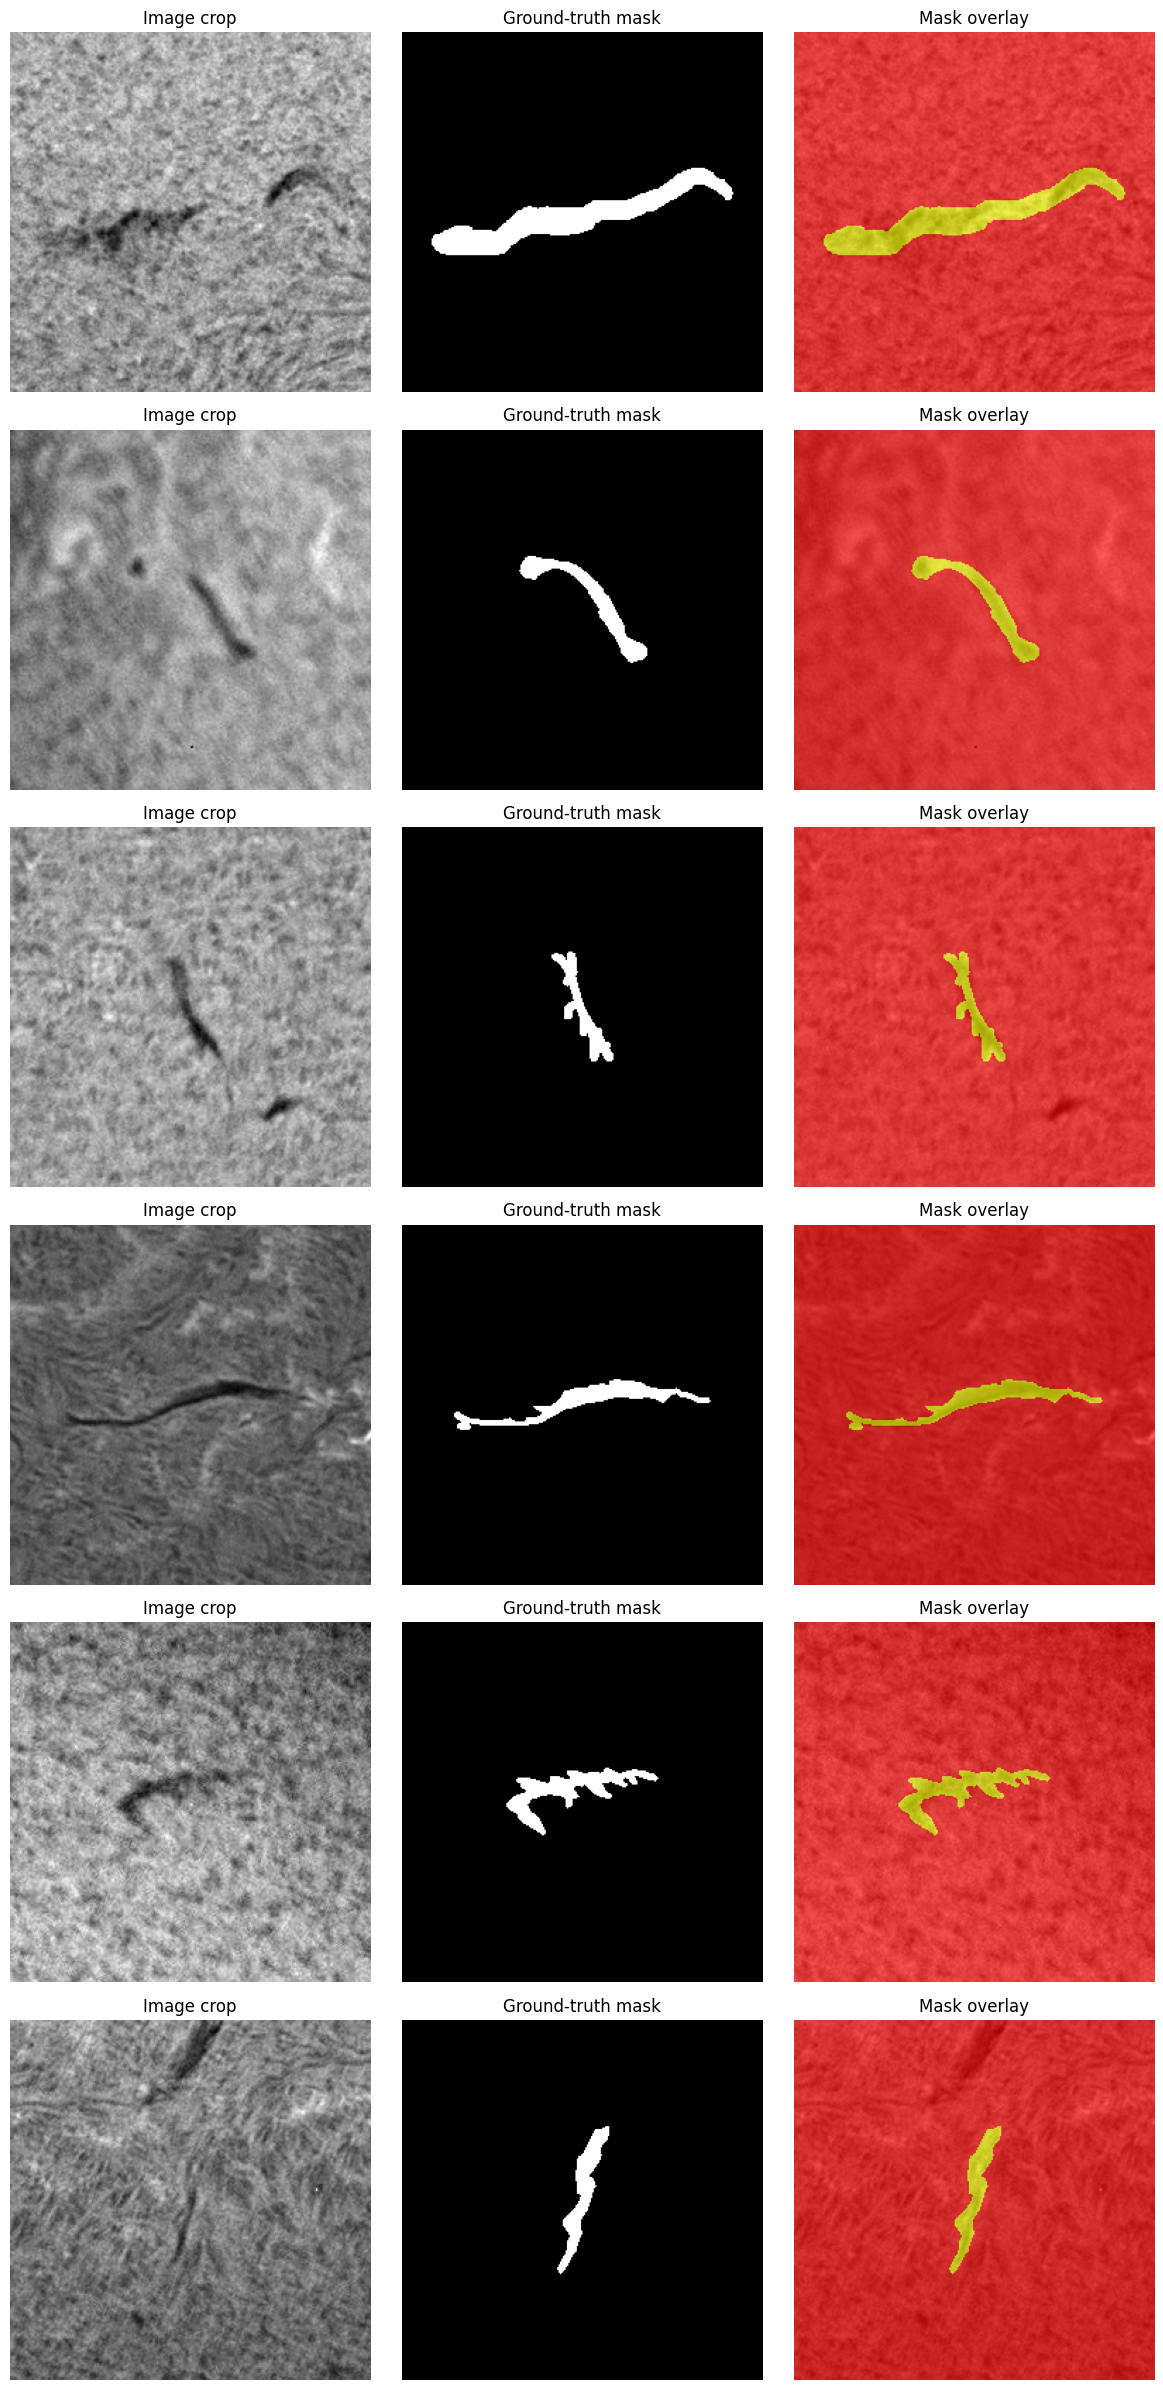

Crop dimensions: (256, 256)


In [13]:
from pathlib import Path
from PIL import Image
import random
import matplotlib.pyplot as plt
import numpy as np

CROP_ROOT = Path("/kaggle/working/filament_crops")

IMAGE_DIR_CROPS = CROP_ROOT / "images" / "train"
MASK_DIR_CROPS = CROP_ROOT / "masks" / "train"

image_files = sorted(IMAGE_DIR_CROPS.glob("*.png"))

print("Training crops found:", len(image_files))

random.seed(42)
samples = random.sample(image_files, min(6, len(image_files)))

fig, axes = plt.subplots(
    len(samples), 3,
    figsize=(12, 4 * len(samples)),
    squeeze=False
)

for row, image_path in enumerate(samples):
    mask_path = MASK_DIR_CROPS / image_path.name

    image = np.array(
        Image.open(image_path).convert("L")
    )

    mask = np.array(
        Image.open(mask_path).convert("L")
    ) > 0

    axes[row, 0].imshow(image, cmap="gray")
    axes[row, 0].set_title("Image crop")

    axes[row, 1].imshow(mask, cmap="gray")
    axes[row, 1].set_title("Ground-truth mask")

    axes[row, 2].imshow(image, cmap="gray")
    axes[row, 2].imshow(mask, cmap="autumn", alpha=0.65)
    axes[row, 2].set_title("Mask overlay")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

print("Crop dimensions:", Image.open(image_files[0]).size)

In [1]:
from pathlib import Path
from PIL import Image
import numpy as np
import random

CROP_ROOT = Path("/kaggle/working/filament_crops")
MASK_DIR = CROP_ROOT / "masks" / "train"

mask_files = sorted(MASK_DIR.glob("*.png"))

areas = []
for path in mask_files:
    mask = np.array(Image.open(path).convert("L")) > 0
    areas.append(int(mask.sum()))

areas = np.array(areas)

print("Total training masks:", len(areas))
print("Empty masks:", int((areas == 0).sum()))
print("Masks with fewer than 20 foreground pixels:", int((areas < 20).sum()))
print("Masks with fewer than 50 foreground pixels:", int((areas < 50).sum()))
print("Masks with fewer than 100 foreground pixels:", int((areas < 100).sum()))
print("Minimum foreground pixels:", int(areas.min()))
print("Median foreground pixels:", int(np.median(areas)))
print("90th percentile foreground pixels:", int(np.percentile(areas, 90)))
print("Maximum foreground pixels:", int(areas.max()))

Total training masks: 0
Empty masks: 0
Masks with fewer than 20 foreground pixels: 0
Masks with fewer than 50 foreground pixels: 0
Masks with fewer than 100 foreground pixels: 0


ValueError: zero-size array to reduction operation minimum which has no identity

In [2]:
from pathlib import Path

CROP_ROOT = Path("/kaggle/working/filament_crops")

print("Crop root exists:", CROP_ROOT.exists())
print("Crop root contents:")

if CROP_ROOT.exists():
    for item in CROP_ROOT.iterdir():
        print(" ", item.name, "| Directory:", item.is_dir())

MASK_DIR = CROP_ROOT / "masks" / "train"

print("\nExpected mask directory:", MASK_DIR)
print("Mask directory exists:", MASK_DIR.exists())

if MASK_DIR.exists():
    print("Files in mask directory:", len(list(MASK_DIR.iterdir())))
    print("PNG masks found:", len(list(MASK_DIR.glob("*.png"))))

Crop root exists: False
Crop root contents:

Expected mask directory: /kaggle/working/filament_crops/masks/train
Mask directory exists: False


In [3]:
from pathlib import Path

paths = {
"Competition input": Path(
"/kaggle/input/competitions/filament-segmentation-2026"
),
"Working directory": Path("/kaggle/working"),
"YOLO dataset": Path("/kaggle/working/filament_yolo"),
"YOLO model weights": Path(
"/kaggle/working/yolo_runs/filament_pilot/weights/best.pt"
),
"Filament crops": Path("/kaggle/working/filament_crops"),
}

for name, path in paths.items():
print(f"\n{name}")
print("  Exists:", path.exists())

```
if path.is_dir():
    print("  Contents:", [item.name for item in list(path.iterdir())[:10]])
```


IndentationError: expected an indented block after 'for' statement on line 15 (2542106118.py, line 16)

In [7]:
from pathlib import Path

paths = {
"Competition input": Path("/kaggle/input/competitions/filament-segmentation-2026"),
"Working directory": Path("/kaggle/working"),
"YOLO dataset": Path("/kaggle/working/filament_yolo"),
"YOLO model weights": Path("/kaggle/working/yolo_runs/filament_pilot/weights/best.pt"),
"Filament crops": Path("/kaggle/working/filament_crops"),
}

for name, path in paths.items():
    print(f"\n{name}")
print("  Exists:", path.exists())

```
if path.is_dir():
    contents = [item.name for item in list(path.iterdir())[:10]]
    print("  Contents:", contents)
```


SyntaxError: invalid syntax (2698203294.py, line 15)

In [8]:
from pathlib import Path

print("Checking Kaggle files...")

p1 = Path("/kaggle/input/competitions/filament-segmentation-2026")
p2 = Path("/kaggle/working")
p3 = Path("/kaggle/working/filament_yolo")
p4 = Path("/kaggle/working/yolo_runs/filament_pilot/weights/best.pt")
p5 = Path("/kaggle/working/filament_crops")

print("Competition input exists:", p1.exists())
print("Working directory exists:", p2.exists())
print("YOLO dataset exists:", p3.exists())
print("YOLO model weights exist:", p4.exists())
print("Filament crops exist:", p5.exists())

print("Working directory contents:", [x.name for x in p2.iterdir()])


Checking Kaggle files...
Competition input exists: True
Working directory exists: True
YOLO dataset exists: False
YOLO model weights exist: False
Filament crops exist: False
Working directory contents: ['.virtual_documents']


In [9]:
import torch
import os

print("PyTorch version:", torch.**version**)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory (GB):", round(
torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
))

print("Competition dataset exists:",
os.path.exists("/kaggle/input/competitions/filament-segmentation-2026"))


SyntaxError: invalid syntax (3935321947.py, line 4)

In [11]:
import torch

print("PyTorch version:", torch.version)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
print("GPU name:", torch.cuda.get_device_name(0))
else:
print("No GPU detected. Check Kaggle notebook accelerator settings.")

print("GPU check completed.")


IndentationError: expected an indented block after 'if' statement on line 6 (3301908639.py, line 7)

In [12]:
import torch
import importlib.metadata
import os

print("PyTorch version:", importlib.metadata.version("torch"))
print("CUDA available:", torch.cuda.is_available())
print("GPU name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU detected")
print("Competition dataset exists:", os.path.exists("/kaggle/input/competitions/filament-segmentation-2026"))

PyTorch version: 2.11.0+cu128
CUDA available: True
GPU name: Tesla T4
Competition dataset exists: True


In [13]:
from pathlib import Path
import json

BASE = Path("/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026")

TRAIN_IMAGES = BASE / "train" / "train_images"
TEST_IMAGES = BASE / "test" / "test_images"
ANNOTATIONS = BASE / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"

print("TRAIN IMAGE DIRECTORY EXISTS:", TRAIN_IMAGES.exists())
print("TEST IMAGE DIRECTORY EXISTS:", TEST_IMAGES.exists())
print("ANNOTATION FILE EXISTS:", ANNOTATIONS.exists())

print("TRAIN IMAGES:", len(list(TRAIN_IMAGES.glob("*"))) if TRAIN_IMAGES.exists() else "NOT FOUND")
print("TEST IMAGES:", len(list(TEST_IMAGES.glob("*"))) if TEST_IMAGES.exists() else "NOT FOUND")

data = json.loads(ANNOTATIONS.read_text()) if ANNOTATIONS.exists() else {}

print("ANNOTATED IMAGE RECORDS:", len(data.get("images", [])))
print("ANNOTATION COUNT:", len(data.get("annotations", [])))
print("CATEGORY COUNT:", len(data.get("categories", [])))

TRAIN IMAGE DIRECTORY EXISTS: True
TEST IMAGE DIRECTORY EXISTS: True
ANNOTATION FILE EXISTS: True
TRAIN IMAGES: 707
TEST IMAGES: 180
ANNOTATED IMAGE RECORDS: 1154
ANNOTATION COUNT: 8199
CATEGORY COUNT: 4


In [14]:
import json
from pathlib import Path
from collections import defaultdict
from sklearn.model_selection import train_test_split

# Dataset paths
BASE = Path(
    "/kaggle/input/competitions/filament-segmentation-2026/"
    "MAGFiLO_1.0_Kaggle_2026"
)

IMAGE_DIR = BASE / "train" / "train_images"
TEST_IMAGE_DIR = BASE / "test" / "test_images"
ANNOTATION_FILE = BASE / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"

# Load the annotation file
with open(ANNOTATION_FILE, "r") as f:
    data = json.load(f)

# Select the first annotation record for each unique filename.
# This avoids counting multiple annotator records as separate images.
selected_records = {}

for record in data["images"]:
    filename = record["file_name"]
    if filename not in selected_records:
        selected_records[filename] = record

# Group annotations by image record ID
annotations_by_id = defaultdict(list)

for ann in data["annotations"]:
    annotations_by_id[ann["image_id"]].append(ann)

# Reproduce a deterministic 85% training / 15% validation split
unique_filenames = sorted(selected_records.keys())

train_filenames, val_filenames = train_test_split(
    unique_filenames,
    test_size=0.15,
    random_state=42
)

# Count instances associated with each selected image record
train_instance_count = sum(
    len(annotations_by_id[selected_records[name]["id"]])
    for name in train_filenames
)

val_instance_count = sum(
    len(annotations_by_id[selected_records[name]["id"]])
    for name in val_filenames
)

# Display verification results
print("DATASET METADATA REBUILT")
print("-" * 35)
print("Unique image filenames:", len(unique_filenames))
print("Training images:", len(train_filenames))
print("Validation images:", len(val_filenames))
print("Training instances:", train_instance_count)
print("Validation instances:", val_instance_count)
print("Test images:", len(list(TEST_IMAGE_DIR.glob("*"))))
print("Annotation records:", len(data["annotations"]))

print(
    "Filename overlap:",
    len(set(train_filenames) & set(val_filenames))
)

print(
    "All training images have files:",
    all((IMAGE_DIR / name).is_file() for name in train_filenames)
)

print(
    "All validation images have files:",
    all((IMAGE_DIR / name).is_file() for name in val_filenames)
)

DATASET METADATA REBUILT
-----------------------------------
Unique image filenames: 707
Training images: 600
Validation images: 107
Training instances: 4336
Validation instances: 873
Test images: 180
Annotation records: 8199
Filename overlap: 0
All training images have files: True
All validation images have files: True


In [15]:
from pathlib import Path
from collections import defaultdict
from sklearn.model_selection import train_test_split
from pycocotools import mask as mask_utils
from PIL import Image
import numpy as np
import json
import csv

# --------------------------------------------------
# 1. CONFIGURATION
# --------------------------------------------------

BASE = Path(
    "/kaggle/input/competitions/filament-segmentation-2026/"
    "MAGFiLO_1.0_Kaggle_2026"
)

IMAGE_DIR = BASE / "train" / "train_images"

ANNOTATION_FILE = (
    BASE / "train" /
    "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
)

OUTPUT_ROOT = Path("/kaggle/working/filament_crops_512")

CROP_SIZE = 512
PADDING = 64

print("Loading annotations...")

# --------------------------------------------------
# 2. LOAD DATASET AND REBUILD THE SAME SPLIT
# --------------------------------------------------

with open(ANNOTATION_FILE, "r") as f:
    data = json.load(f)

selected_records = {}

for record in data["images"]:
    filename = record["file_name"]

    if filename not in selected_records:
        selected_records[filename] = record

annotations_by_id = defaultdict(list)

for ann in data["annotations"]:
    annotations_by_id[ann["image_id"]].append(ann)

unique_filenames = sorted(selected_records.keys())

train_filenames, val_filenames = train_test_split(
    unique_filenames,
    test_size=0.15,
    random_state=42
)

print("Training images:", len(train_filenames))
print("Validation images:", len(val_filenames))

# --------------------------------------------------
# 3. CREATE CROP OUTPUT DIRECTORIES
# --------------------------------------------------

for split in ["train", "val"]:
    (OUTPUT_ROOT / "images" / split).mkdir(
        parents=True, exist_ok=True
    )

    (OUTPUT_ROOT / "masks" / split).mkdir(
        parents=True, exist_ok=True
    )

# --------------------------------------------------
# 4. CROP FUNCTION
# --------------------------------------------------

def create_crop(image, mask):
    height, width = mask.shape

    ys, xs = np.where(mask)

    x_min = int(xs.min())
    x_max = int(xs.max()) + 1
    y_min = int(ys.min())
    y_max = int(ys.max()) + 1

    box_width = x_max - x_min
    box_height = y_max - y_min

    # Ensure the entire annotated mask fits inside the crop.
    # Small and medium structures use a 512-pixel crop.
    # Larger structures receive a larger crop before resizing.
    required_side = max(
        CROP_SIZE,
        box_width + 2 * PADDING,
        box_height + 2 * PADDING
    )

    side = min(required_side, height, width)

    center_x = (x_min + x_max) / 2
    center_y = (y_min + y_max) / 2

    left = int(round(center_x - side / 2))
    top = int(round(center_y - side / 2))

    # Keep the square crop inside the original image.
    left = max(0, min(left, width - side))
    top = max(0, min(top, height - side))

    right = left + side
    bottom = top + side

    image_crop = image[top:bottom, left:right]
    mask_crop = mask[top:bottom, left:right]

    original_area = int(mask.sum())
    cropped_area = int(mask_crop.sum())

    # Resize photographs with bilinear interpolation.
    image_resized = Image.fromarray(image_crop).resize(
        (CROP_SIZE, CROP_SIZE),
        resample=Image.Resampling.BILINEAR
    )

    # Use nearest-neighbor interpolation for binary masks.
    # This avoids introducing intermediate mask labels.
    mask_resized = Image.fromarray(
        (mask_crop > 0).astype(np.uint8) * 255
    ).resize(
        (CROP_SIZE, CROP_SIZE),
        resample=Image.Resampling.NEAREST
    )

    final_mask = np.asarray(mask_resized) > 0
    final_area = int(final_mask.sum())

    return (
        image_resized,
        mask_resized,
        box_width,
        box_height,
        side,
        original_area,
        cropped_area,
        final_area
    )

# --------------------------------------------------
# 5. GENERATE TRAINING AND VALIDATION CROPS
# --------------------------------------------------

manifest = []
empty_masks = 0
clipped_masks = 0
processed = 0
resized_large_crops = 0

splits = [
    ("train", train_filenames),
    ("val", val_filenames)
]

for split, filenames in splits:
    image_output_dir = OUTPUT_ROOT / "images" / split
    mask_output_dir = OUTPUT_ROOT / "masks" / split

    print("\nProcessing", split, "images...")

    for image_number, filename in enumerate(filenames, start=1):
        record = selected_records[filename]
        image_path = IMAGE_DIR / filename

        image = np.asarray(
            Image.open(image_path).convert("RGB")
        )

        image_height, image_width = image.shape[:2]

        instance_annotations = annotations_by_id[record["id"]]

        for ann in instance_annotations:
            polygons = ann.get("segmentation", [])

            if not polygons:
                empty_masks += 1
                continue

            rles = mask_utils.frPyObjects(
                polygons,
                image_height,
                image_width
            )

            decoded_mask = mask_utils.decode(
                mask_utils.merge(rles)
            )

            if decoded_mask.ndim == 3:
                decoded_mask = np.any(decoded_mask > 0, axis=2)
            else:
                decoded_mask = decoded_mask > 0

            if not decoded_mask.any():
                empty_masks += 1
                continue

            result = create_crop(image, decoded_mask)

            (
                image_crop,
                mask_crop,
                box_width,
                box_height,
                crop_side,
                original_area,
                cropped_area,
                final_area
            ) = result

            if cropped_area != original_area:
                clipped_masks += 1

            if crop_side > CROP_SIZE:
                resized_large_crops += 1

            crop_name = (
                f"{Path(filename).stem}_ann{ann['id']}.png"
            )

            image_crop.save(image_output_dir / crop_name)
            mask_crop.save(mask_output_dir / crop_name)

            manifest.append({
                "split": split,
                "crop_filename": crop_name,
                "source_filename": filename,
                "annotation_id": ann["id"],
                "bbox_width": box_width,
                "bbox_height": box_height,
                "original_crop_side": crop_side,
                "original_mask_pixels": original_area,
                "cropped_mask_pixels": cropped_area,
                "resized_mask_pixels": final_area
            })

            processed += 1

        if image_number % 100 == 0:
            print(
                "  Processed",
                image_number,
                "of",
                len(filenames),
                "images"
            )

# --------------------------------------------------
# 6. SAVE MANIFEST AND VERIFY RESULTS
# --------------------------------------------------

manifest_path = OUTPUT_ROOT / "crop_manifest.csv"

with open(manifest_path, "w", newline="") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=list(manifest[0].keys())
    )
    writer.writeheader()
    writer.writerows(manifest)

train_count = sum(
    item["split"] == "train" for item in manifest
)

val_count = sum(
    item["split"] == "val" for item in manifest
)

print("\n" + "=" * 45)
print("CROP GENERATION COMPLETE")
print("=" * 45)

print("Training crops:", train_count)
print("Validation crops:", val_count)
print("Total crops:", processed)
print("Empty masks skipped:", empty_masks)
print("Masks losing pixels before resizing:", clipped_masks)
print("Crops larger than 512 before resizing:", resized_large_crops)
print("Crop dimensions:", CROP_SIZE, "x", CROP_SIZE)
print("Manifest:", manifest_path)
print("Output directory:", OUTPUT_ROOT)

print("\nChecking image-mask pairs...")

train_images = list(
    (OUTPUT_ROOT / "images" / "train").glob("*.png")
)

train_masks = list(
    (OUTPUT_ROOT / "masks" / "train").glob("*.png")
)

val_images = list(
    (OUTPUT_ROOT / "images" / "val").glob("*.png")
)

val_masks = list(
    (OUTPUT_ROOT / "masks" / "val").glob("*.png")
)

print("Training images:", len(train_images))
print("Training masks:", len(train_masks))
print("Validation images:", len(val_images))
print("Validation masks:", len(val_masks))

print(
    "Training filename pairs match:",
    {p.name for p in train_images} == {p.name for p in train_masks}
)

print(
    "Validation filename pairs match:",
    {p.name for p in val_images} == {p.name for p in val_masks}
)

Loading annotations...
Training images: 600
Validation images: 107

Processing train images...
  Processed 100 of 600 images
  Processed 200 of 600 images
  Processed 300 of 600 images
  Processed 400 of 600 images
  Processed 500 of 600 images
  Processed 600 of 600 images

Processing val images...
  Processed 100 of 107 images

CROP GENERATION COMPLETE
Training crops: 4336
Validation crops: 873
Total crops: 5209
Empty masks skipped: 0
Masks losing pixels before resizing: 0
Crops larger than 512 before resizing: 158
Crop dimensions: 512 x 512
Manifest: /kaggle/working/filament_crops_512/crop_manifest.csv
Output directory: /kaggle/working/filament_crops_512

Checking image-mask pairs...
Training images: 4336
Training masks: 4336
Validation images: 873
Validation masks: 873
Training filename pairs match: True
Validation filename pairs match: True


Training crops available: 4336
Crop dimensions: (512, 512)
20150130084914Th_ann86d002ce-ea25-4cd9-8ee8-1b2ea74860f5.png | Original crop side: 512 | Original mask pixels: 367 | Resized mask pixels: 367
20131207084214Th_ann67f65785-ecc3-4794-a580-77bafe7426c6.png | Original crop side: 512 | Original mask pixels: 1127 | Resized mask pixels: 1127
20110914063134Lh_ann7b3a147e-f896-4441-b75f-10d7fb82f22f.png | Original crop side: 512 | Original mask pixels: 860 | Resized mask pixels: 860
20111107063154Uh_anna413d118-cfce-4745-a5dd-6b3ec2a8d58c.png | Original crop side: 512 | Original mask pixels: 296 | Resized mask pixels: 296
20130611063154Uh_ann28410dc4-68e5-41b1-854c-5c1f007e3799.png | Original crop side: 929 | Original mask pixels: 12997 | Resized mask pixels: 3974
20150527161214Mh_ann2e6ec9af-108a-4911-820c-b504259d9bcf.png | Original crop side: 923 | Original mask pixels: 11802 | Resized mask pixels: 3643


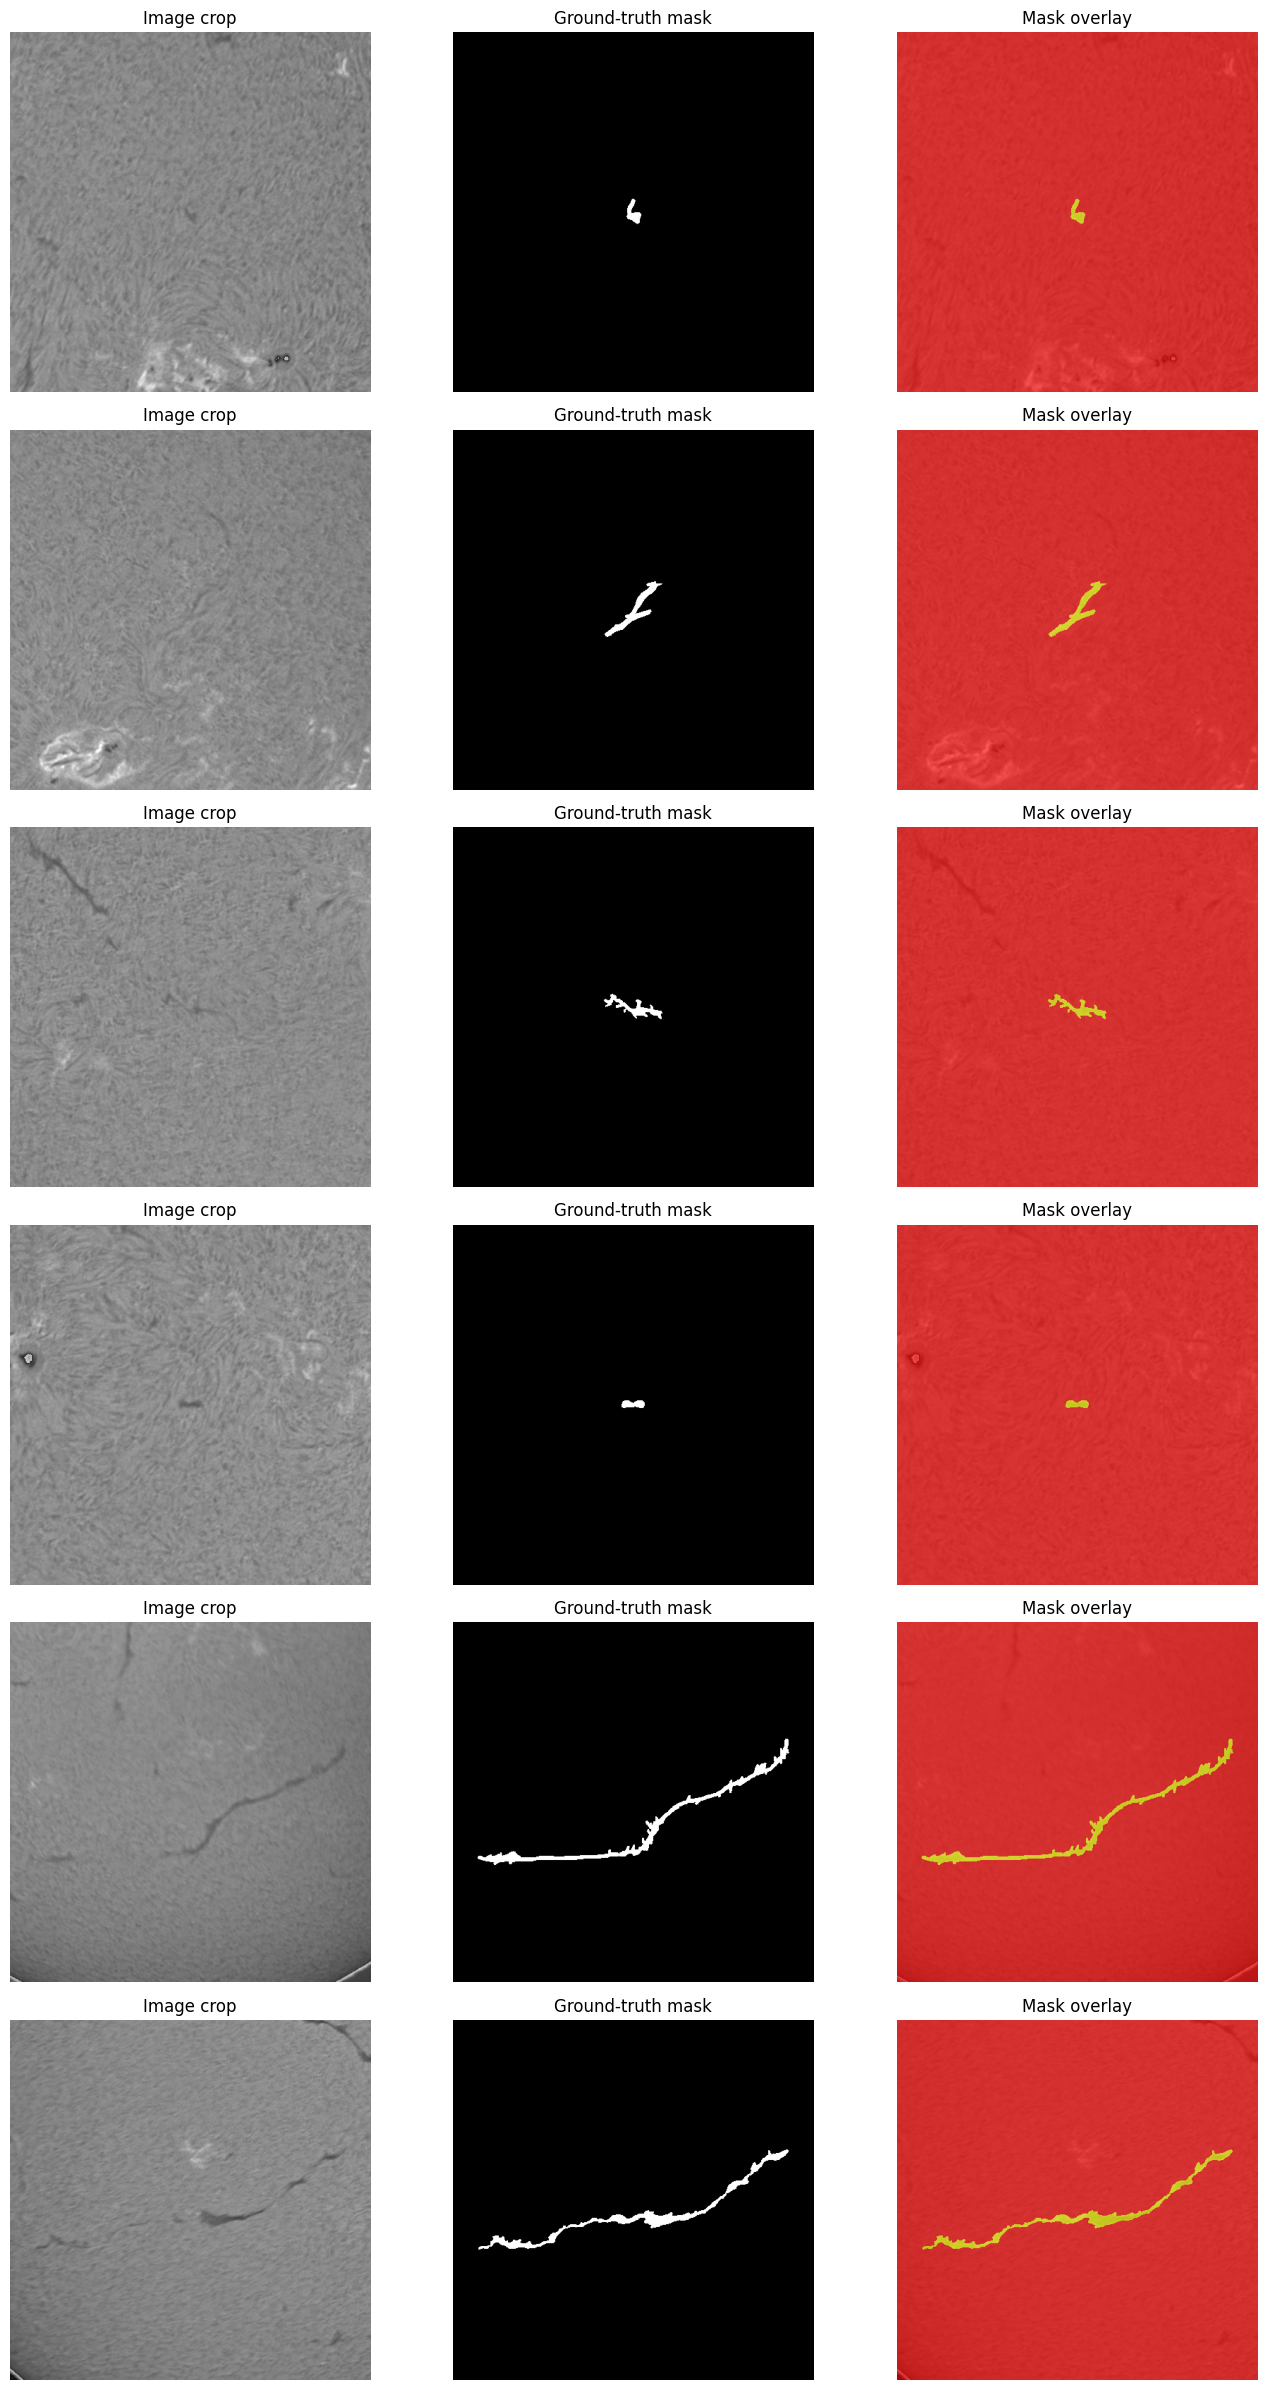

In [17]:
from pathlib import Path
from PIL import Image
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path("/kaggle/working/filament_crops_512")

IMAGE_DIR = ROOT / "images" / "train"
MASK_DIR = ROOT / "masks" / "train"
MANIFEST = ROOT / "crop_manifest.csv"

# Load crop information
df = pd.read_csv(MANIFEST)
train_df = df[df["split"] == "train"].copy()

print("Training crops available:", len(train_df))
print("Crop dimensions:", Image.open(
    IMAGE_DIR / train_df.iloc[0]["crop_filename"]
).size)

# Four random crops
random_samples = train_df.sample(
    n=min(4, len(train_df)),
    random_state=42
)

# Two crops requiring the largest original fields of view
largest_samples = train_df.nlargest(
    min(2, len(train_df)),
    "original_crop_side"
)

# Combine and remove duplicates
samples = pd.concat([random_samples, largest_samples])
samples = samples.drop_duplicates(subset="crop_filename")

fig, axes = plt.subplots(
    len(samples), 3,
    figsize=(14, 4 * len(samples)),
    squeeze=False
)

for row, (_, record) in enumerate(samples.iterrows()):
    filename = record["crop_filename"]

    image = np.array(
        Image.open(IMAGE_DIR / filename).convert("RGB")
    )

    mask = np.array(
        Image.open(MASK_DIR / filename).convert("L")
    ) > 0

    axes[row, 0].imshow(image)
    axes[row, 0].set_title("Image crop")

    axes[row, 1].imshow(mask, cmap="gray")
    axes[row, 1].set_title("Ground-truth mask")

    axes[row, 2].imshow(image)
    axes[row, 2].imshow(mask, cmap="autumn", alpha=0.65)
    axes[row, 2].set_title("Mask overlay")

    for ax in axes[row]:
        ax.axis("off")

    print(
        filename,
        "| Original crop side:", int(record["original_crop_side"]),
        "| Original mask pixels:", int(record["original_mask_pixels"]),
        "| Resized mask pixels:", int(record["resized_mask_pixels"])
    )

plt.tight_layout()
plt.show()

In [18]:
import os
import random
from pathlib import Path

import numpy as np
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader


# ============================================================
# 1. CONFIGURATION
# ============================================================

ROOT = Path("/kaggle/working/filament_crops_512")

TRAIN_IMAGES = ROOT / "images" / "train"
TRAIN_MASKS = ROOT / "masks" / "train"

VAL_IMAGES = ROOT / "images" / "val"
VAL_MASKS = ROOT / "masks" / "val"

CHECKPOINT_PATH = "/kaggle/working/filament_unet_best.pt"

BATCH_SIZE = 4
EPOCHS = 5
LEARNING_RATE = 0.001

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Training images directory exists:", TRAIN_IMAGES.exists())
print("Training masks directory exists:", TRAIN_MASKS.exists())
print("Validation images directory exists:", VAL_IMAGES.exists())
print("Validation masks directory exists:", VAL_MASKS.exists())


# ============================================================
# 2. DATASET
# ============================================================

class FilamentDataset(Dataset):

    def __init__(self, image_dir, mask_dir, augment=False):
        self.image_dir = Path(image_dir)
        self.mask_dir = Path(mask_dir)
        self.augment = augment

        self.image_files = sorted(self.image_dir.glob("*.png"))

        self.image_files = [
            path for path in self.image_files
            if (self.mask_dir / path.name).is_file()
        ]

        if len(self.image_files) == 0:
            raise RuntimeError(
                "No matching image-mask pairs found. Check dataset paths."
            )

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        image_path = self.image_files[idx]
        mask_path = self.mask_dir / image_path.name

        image = np.asarray(
            Image.open(image_path).convert("RGB"),
            dtype=np.float32
        ) / 255.0

        mask = np.asarray(
            Image.open(mask_path).convert("L"),
            dtype=np.uint8
        )

        mask = (mask > 0).astype(np.float32)

        # Apply matching spatial augmentation to image and mask.
        if self.augment:
            if random.random() < 0.5:
                image = np.fliplr(image).copy()
                mask = np.fliplr(mask).copy()

            if random.random() < 0.5:
                image = np.flipud(image).copy()
                mask = np.flipud(mask).copy()

        image = torch.from_numpy(image.transpose(2, 0, 1))
        mask = torch.from_numpy(mask).unsqueeze(0)

        return image, mask


train_dataset = FilamentDataset(
    TRAIN_IMAGES,
    TRAIN_MASKS,
    augment=True
)

val_dataset = FilamentDataset(
    VAL_IMAGES,
    VAL_MASKS,
    augment=False
)

print("\nTraining crops:", len(train_dataset))
print("Validation crops:", len(val_dataset))

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)


# ============================================================
# 3. LIGHTWEIGHT U-NET
# ============================================================

class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Conv2d(
                in_channels, out_channels,
                kernel_size=3, padding=1, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels, out_channels,
                kernel_size=3, padding=1, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.layers(x)


class UNet(nn.Module):

    def __init__(self):
        super().__init__()

        self.pool = nn.MaxPool2d(2)

        self.enc1 = DoubleConv(3, 16)
        self.enc2 = DoubleConv(16, 32)
        self.enc3 = DoubleConv(32, 64)
        self.enc4 = DoubleConv(64, 128)

        self.bottleneck = DoubleConv(128, 256)

        self.dec4 = DoubleConv(256 + 128, 128)
        self.dec3 = DoubleConv(128 + 64, 64)
        self.dec2 = DoubleConv(64 + 32, 32)
        self.dec1 = DoubleConv(32 + 16, 16)

        self.output_layer = nn.Conv2d(16, 1, kernel_size=1)

    def forward(self, x):

        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = F.interpolate(
            b, size=e4.shape[2:],
            mode="bilinear", align_corners=False
        )
        d4 = self.dec4(torch.cat([d4, e4], dim=1))

        d3 = F.interpolate(
            d4, size=e3.shape[2:],
            mode="bilinear", align_corners=False
        )
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = F.interpolate(
            d3, size=e2.shape[2:],
            mode="bilinear", align_corners=False
        )
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = F.interpolate(
            d2, size=e1.shape[2:],
            mode="bilinear", align_corners=False
        )
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.output_layer(d1)


model = UNet().to(device)

print("\nU-Net parameters:", sum(
    parameter.numel() for parameter in model.parameters()
))


# ============================================================
# 4. LOSS FUNCTION
# ============================================================

bce_loss = nn.BCEWithLogitsLoss()


def segmentation_loss(logits, targets):

    logits = logits.float()
    targets = targets.float()

    bce = bce_loss(logits, targets)

    probabilities = torch.sigmoid(logits)

    intersection = (probabilities * targets).sum(
        dim=(1, 2, 3)
    )

    denominator = probabilities.sum(
        dim=(1, 2, 3)
    ) + targets.sum(dim=(1, 2, 3))

    dice = (2.0 * intersection + 1.0) / (
        denominator + 1.0
    )

    dice_loss = 1.0 - dice.mean()

    return bce + dice_loss


optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)


# ============================================================
# 5. TRAINING AND VALIDATION
# ============================================================

best_val_dice = -1.0

print("\nStarting training...")

for epoch in range(EPOCHS):

    model.train()

    train_loss_total = 0.0

    for batch_index, (images, masks) in enumerate(
        train_loader, start=1
    ):

        images = images.to(
            device, non_blocking=True
        )

        masks = masks.to(
            device, non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=torch.cuda.is_available()
        ):
            logits = model(images)
            loss = segmentation_loss(logits, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss_total += loss.item()

        if batch_index % 200 == 0:
            print(
                "Epoch", epoch + 1,
                "| Batch", batch_index,
                "| Current loss:", round(loss.item(), 4)
            )

    avg_train_loss = train_loss_total / len(train_loader)

    # Evaluate on validation crops without augmentation.
    model.eval()

    val_loss_total = 0.0
    dice_total = 0.0
    image_count = 0

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(
                device, non_blocking=True
            )

            masks = masks.to(
                device, non_blocking=True
            )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=torch.cuda.is_available()
            ):
                logits = model(images)
                loss = segmentation_loss(logits, masks)

            val_loss_total += loss.item()

            probabilities = torch.sigmoid(logits.float())
            predictions = probabilities >= 0.5

            intersection = (predictions * masks.bool()).sum(
                dim=(1, 2, 3)
            ).float()

            denominator = predictions.sum(
                dim=(1, 2, 3)
            ).float() + masks.sum(dim=(1, 2, 3))

            dice_scores = (
                2.0 * intersection + 1.0
            ) / (denominator + 1.0)

            dice_total += dice_scores.sum().item()
            image_count += images.size(0)

    avg_val_loss = val_loss_total / len(val_loader)
    avg_val_dice = dice_total / image_count

    print("\nEPOCH", epoch + 1, "OF", EPOCHS)
    print("Training loss:", round(avg_train_loss, 4))
    print("Validation loss:", round(avg_val_loss, 4))
    print("Validation crop Dice:", round(avg_val_dice, 4))

    if avg_val_dice > best_val_dice:

        best_val_dice = avg_val_dice

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "epoch": epoch + 1,
                "val_dice": best_val_dice
            },
            CHECKPOINT_PATH
        )

        print("Best model checkpoint saved.")

    print("-" * 45)


# ============================================================
# 6. FINAL STATUS
# ============================================================

print("\nTRAINING FINISHED")
print("Best validation crop Dice:", round(best_val_dice, 4))
print("Checkpoint exists:", os.path.exists(CHECKPOINT_PATH))
print("Checkpoint path:", CHECKPOINT_PATH)

Device: cuda
GPU: Tesla T4
Training images directory exists: True
Training masks directory exists: True
Validation images directory exists: True
Validation masks directory exists: True

Training crops: 4336
Validation crops: 873

U-Net parameters: 1964097

Starting training...
Epoch 1 | Batch 200 | Current loss: 1.0573
Epoch 1 | Batch 400 | Current loss: 0.8759
Epoch 1 | Batch 600 | Current loss: 0.5949
Epoch 1 | Batch 800 | Current loss: 0.6843
Epoch 1 | Batch 1000 | Current loss: 0.65

EPOCH 1 OF 5
Training loss: 0.7637
Validation loss: 0.6501
Validation crop Dice: 0.3962
Best model checkpoint saved.
---------------------------------------------
Epoch 2 | Batch 200 | Current loss: 0.5169
Epoch 2 | Batch 400 | Current loss: 0.5315
Epoch 2 | Batch 600 | Current loss: 0.4472
Epoch 2 | Batch 800 | Current loss: 0.3912
Epoch 2 | Batch 1000 | Current loss: 0.5019

EPOCH 2 OF 5
Training loss: 0.511
Validation loss: 0.5918
Validation crop Dice: 0.4532
Best model checkpoint saved.
-----------

Best checkpoint loaded successfully.
Best epoch: 3
Saved validation Dice: 0.4857
Validation crops: 873

VALIDATION THRESHOLD RESULTS
-------------------------------------------------------
Threshold | Mean crop Dice | Overall pixel Dice
     0.30 |         0.4915 |             0.5320
     0.40 |         0.4886 |             0.5291
     0.50 |         0.4857 |             0.5262
     0.60 |         0.4828 |             0.5231
     0.70 |         0.4792 |             0.5196

Best validation threshold: 0.3
Best mean crop Dice: 0.4915


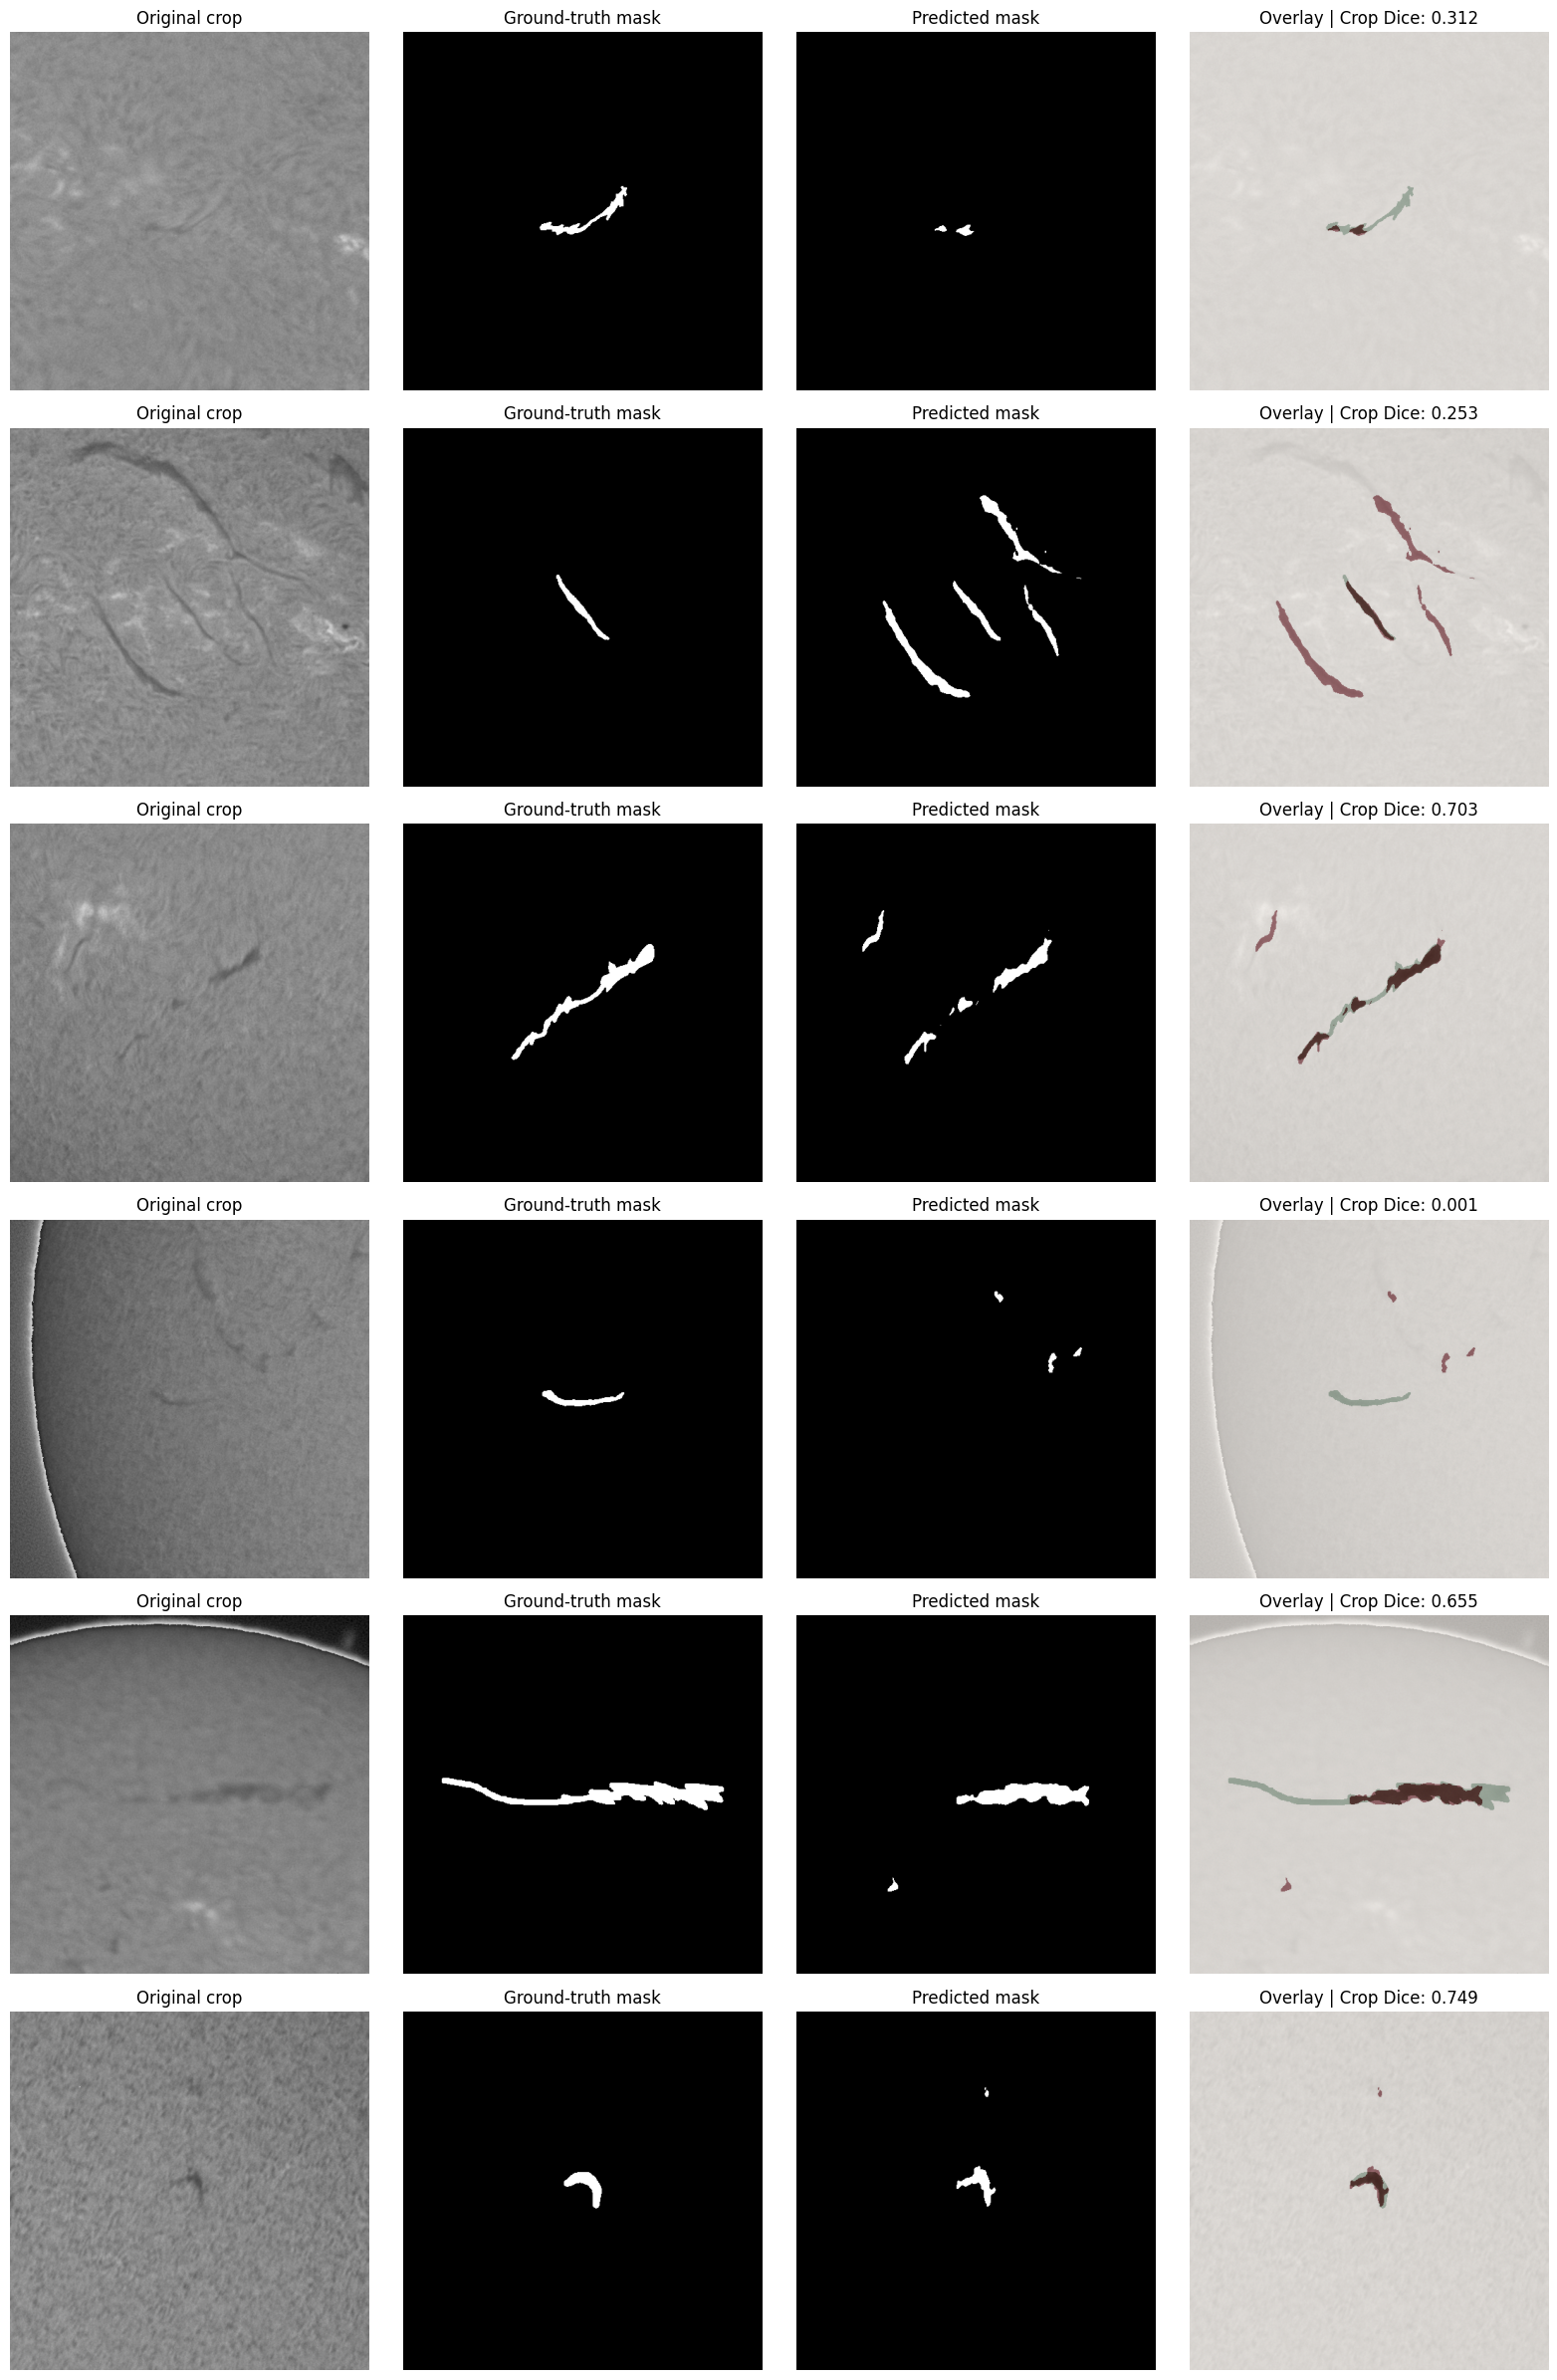

In [19]:
import torch
import numpy as np
import random
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. LOAD THE BEST SAVED MODEL
# --------------------------------------------------

CHECKPOINT_PATH = "/kaggle/working/filament_unet_best.pt"

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Best checkpoint loaded successfully.")
print("Best epoch:", checkpoint["epoch"])
print("Saved validation Dice:", round(checkpoint["val_dice"], 4))
print("Validation crops:", len(val_dataset))


# --------------------------------------------------
# 2. EVALUATE MULTIPLE THRESHOLDS
# --------------------------------------------------

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

results = {}

for threshold in thresholds:
    results[threshold] = {
        "dice_sum": 0.0,
        "samples": 0,
        "intersection": 0.0,
        "predicted_pixels": 0.0,
        "true_pixels": 0.0
    }

with torch.no_grad():
    for images, masks in val_loader:

        images = images.to(device)
        masks = masks.to(device) >= 0.5

        probabilities = torch.sigmoid(model(images).float())
        targets = masks.bool()

        for threshold in thresholds:

            predictions = probabilities >= threshold

            intersection = (
                predictions & targets
            ).sum(dim=(1, 2, 3)).float()

            predicted_pixels = predictions.sum(
                dim=(1, 2, 3)
            ).float()

            true_pixels = targets.sum(
                dim=(1, 2, 3)
            ).float()

            dice = (
                2 * intersection + 1
            ) / (
                predicted_pixels + true_pixels + 1
            )

            results[threshold]["dice_sum"] += dice.sum().item()
            results[threshold]["samples"] += images.size(0)

            results[threshold]["intersection"] += intersection.sum().item()
            results[threshold]["predicted_pixels"] += predicted_pixels.sum().item()
            results[threshold]["true_pixels"] += true_pixels.sum().item()


print("\nVALIDATION THRESHOLD RESULTS")
print("-" * 55)
print("Threshold | Mean crop Dice | Overall pixel Dice")

for threshold in thresholds:

    item = results[threshold]

    mean_dice = item["dice_sum"] / item["samples"]

    overall_dice = (
        2 * item["intersection"] + 1
    ) / (
        item["predicted_pixels"] + item["true_pixels"] + 1
    )

    print(
        f"{threshold:9.2f} | "
        f"{mean_dice:14.4f} | "
        f"{overall_dice:18.4f}"
    )

best_threshold = max(
    thresholds,
    key=lambda t: results[t]["dice_sum"] / results[t]["samples"]
)

print("\nBest validation threshold:", best_threshold)
print(
    "Best mean crop Dice:",
    round(
        results[best_threshold]["dice_sum"]
        / results[best_threshold]["samples"],
        4
    )
)


# --------------------------------------------------
# 3. VISUALIZE SIX VALIDATION PREDICTIONS
# --------------------------------------------------

random.seed(42)

sample_indices = random.sample(
    range(len(val_dataset)),
    min(6, len(val_dataset))
)

fig, axes = plt.subplots(
    len(sample_indices),
    4,
    figsize=(16, 4 * len(sample_indices)),
    squeeze=False
)

with torch.no_grad():

    for row, index in enumerate(sample_indices):

        image_tensor, mask_tensor = val_dataset[index]

        image = image_tensor.permute(1, 2, 0).numpy()
        ground_truth = mask_tensor[0].numpy() > 0.5

        logits = model(
            image_tensor.unsqueeze(0).to(device)
        )

        probability = torch.sigmoid(
            logits.float()
        )[0, 0].cpu().numpy()

        prediction = probability >= best_threshold

        intersection = np.logical_and(
            prediction, ground_truth
        ).sum()

        dice = (
            2 * intersection + 1
        ) / (
            prediction.sum() + ground_truth.sum() + 1
        )

        axes[row, 0].imshow(image)
        axes[row, 0].set_title("Original crop")

        axes[row, 1].imshow(
            ground_truth,
            cmap="gray",
            vmin=0,
            vmax=1
        )
        axes[row, 1].set_title("Ground-truth mask")

        axes[row, 2].imshow(
            prediction,
            cmap="gray",
            vmin=0,
            vmax=1
        )
        axes[row, 2].set_title("Predicted mask")

        axes[row, 3].imshow(image)
        axes[row, 3].imshow(
            ground_truth,
            cmap="Greens",
            alpha=0.45
        )
        axes[row, 3].imshow(
            prediction,
            cmap="Reds",
            alpha=0.45
        )
        axes[row, 3].set_title(
            f"Overlay | Crop Dice: {dice:.3f}"
        )

        for ax in axes[row]:
            ax.axis("off")

plt.tight_layout()
plt.show()

In [20]:
import json
import os
import shutil
import importlib.util
from pathlib import Path
from collections import defaultdict
from sklearn.model_selection import train_test_split

# --------------------------------------------------
# 1. PATHS
# --------------------------------------------------

BASE = Path(
    "/kaggle/input/competitions/filament-segmentation-2026/"
    "MAGFiLO_1.0_Kaggle_2026"
)

IMAGE_DIR = BASE / "train" / "train_images"

ANNOTATION_FILE = (
    BASE / "train" /
    "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
)

YOLO_ROOT = Path("/kaggle/working/filament_yolo")

# --------------------------------------------------
# 2. LOAD ANNOTATIONS
# --------------------------------------------------

with open(ANNOTATION_FILE, "r") as f:
    data = json.load(f)

selected_records = {}

for record in data["images"]:
    filename = record["file_name"]

    if filename not in selected_records:
        selected_records[filename] = record

annotations_by_id = defaultdict(list)

for ann in data["annotations"]:
    annotations_by_id[ann["image_id"]].append(ann)

# Reproduce the previous split exactly.
unique_filenames = sorted(selected_records.keys())

train_filenames, val_filenames = train_test_split(
    unique_filenames,
    test_size=0.15,
    random_state=42
)

print("Training images:", len(train_filenames))
print("Validation images:", len(val_filenames))

# --------------------------------------------------
# 3. CREATE DIRECTORIES
# --------------------------------------------------

if YOLO_ROOT.exists():
    shutil.rmtree(YOLO_ROOT)

for split in ["train", "val"]:
    (YOLO_ROOT / "images" / split).mkdir(
        parents=True,
        exist_ok=True
    )

    (YOLO_ROOT / "labels" / split).mkdir(
        parents=True,
        exist_ok=True
    )

# --------------------------------------------------
# 4. CREATE YOLO LABELS AND IMAGE LINKS
# --------------------------------------------------

train_box_count = 0
val_box_count = 0
missing_images = 0
invalid_boxes = 0

for split, filenames in [
    ("train", train_filenames),
    ("val", val_filenames)
]:
    image_output_dir = YOLO_ROOT / "images" / split
    label_output_dir = YOLO_ROOT / "labels" / split

    for filename in filenames:
        source_image = IMAGE_DIR / filename
        destination_image = image_output_dir / filename

        record = selected_records[filename]

        if not source_image.is_file():
            missing_images += 1
            continue

        # Link the original image instead of duplicating it.
        os.symlink(
            str(source_image),
            str(destination_image)
        )

        image_width = record["width"]
        image_height = record["height"]

        label_lines = []

        for ann in annotations_by_id[record["id"]]:
            bbox = ann.get("bbox", [])

            if len(bbox) != 4:
                invalid_boxes += 1
                continue

            x, y, width, height = bbox

            if width <= 0 or height <= 0:
                invalid_boxes += 1
                continue

            # Convert COCO [x, y, width, height] to
            # YOLO [class, center_x, center_y, width, height].
            center_x = (x + width / 2) / image_width
            center_y = (y + height / 2) / image_height

            normalized_width = width / image_width
            normalized_height = height / image_height

            # One class: filament.
            label_lines.append(
                f"0 {center_x:.6f} {center_y:.6f} "
                f"{normalized_width:.6f} "
                f"{normalized_height:.6f}"
            )

        label_path = label_output_dir / (
            Path(filename).stem + ".txt"
        )

        label_path.write_text(
            "\n".join(label_lines)
            + ("\n" if label_lines else "")
        )

        if split == "train":
            train_box_count += len(label_lines)
        else:
            val_box_count += len(label_lines)

# --------------------------------------------------
# 5. CREATE YOLO CONFIGURATION
# --------------------------------------------------

yaml_text = (
    f"path: {YOLO_ROOT}\n"
    "train: images/train\n"
    "val: images/val\n"
    "names:\n"
    "  0: filament\n"
)

(YOLO_ROOT / "data.yaml").write_text(yaml_text)

# --------------------------------------------------
# 6. VERIFY THE DATASET
# --------------------------------------------------

train_image_count = len(
    list((YOLO_ROOT / "images" / "train").iterdir())
)

val_image_count = len(
    list((YOLO_ROOT / "images" / "val").iterdir())
)

train_label_count = len(
    list((YOLO_ROOT / "labels" / "train").glob("*.txt"))
)

val_label_count = len(
    list((YOLO_ROOT / "labels" / "val").glob("*.txt"))
)

print("\nDETECTOR DATASET REBUILT")
print("-" * 40)
print("Training images:", train_image_count)
print("Training label files:", train_label_count)
print("Training bounding boxes:", train_box_count)
print("Validation images:", val_image_count)
print("Validation label files:", val_label_count)
print("Validation bounding boxes:", val_box_count)
print("Missing source images:", missing_images)
print("Invalid boxes skipped:", invalid_boxes)
print("YOLO configuration:", YOLO_ROOT / "data.yaml")
print(
    "Ultralytics installed:",
    importlib.util.find_spec("ultralytics") is not None
)

Training images: 600
Validation images: 107

DETECTOR DATASET REBUILT
----------------------------------------
Training images: 600
Training label files: 600
Training bounding boxes: 4336
Validation images: 107
Validation label files: 107
Validation bounding boxes: 873
Missing source images: 0
Invalid boxes skipped: 0
YOLO configuration: /kaggle/working/filament_yolo/data.yaml
Ultralytics installed: False


In [21]:
%pip install -q ultralytics==8.4.183

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 20.0 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 2.7 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [22]:
import torch
import ultralytics
from ultralytics import YOLO

print("Ultralytics version:", ultralytics.__version__)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")
print("YOLO import successful")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics version: 8.4.183
PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
YOLO import successful


In [23]:
from pathlib import Path
import torch
from ultralytics import YOLO

# --------------------------------------------------
# 1. Verify the detector dataset
# --------------------------------------------------

DATA_YAML = Path("/kaggle/working/filament_yolo/data.yaml")

assert DATA_YAML.is_file(), (
    "YOLO data.yaml is missing. Rebuild the detector dataset first."
)

print("Dataset configuration:", DATA_YAML)
print("CUDA available:", torch.cuda.is_available())

assert torch.cuda.is_available(), (
    "GPU is unavailable. Enable the GPU accelerator in Kaggle."
)

print("GPU:", torch.cuda.get_device_name(0))

# --------------------------------------------------
# 2. Load the pretrained detector
# --------------------------------------------------

model = YOLO("yolo11n.pt")

# --------------------------------------------------
# 3. Train
# --------------------------------------------------

results = model.train(
    data=str(DATA_YAML),
    epochs=25,
    imgsz=1024,
    batch=4,
    device=0,
    workers=2,
    patience=7,
    seed=42,
    project="/kaggle/working/yolo_runs",
    name="filament_detector",
    exist_ok=True,
    save=True,
    save_period=5,
    plots=True,
    close_mosaic=5
)

# --------------------------------------------------
# 4. Verify saved weights
# --------------------------------------------------

BEST_WEIGHTS = Path(
    "/kaggle/working/yolo_runs/"
    "filament_detector/weights/best.pt"
)

LAST_WEIGHTS = Path(
    "/kaggle/working/yolo_runs/"
    "filament_detector/weights/last.pt"
)

print("\nDETECTOR TRAINING FINISHED")
print("Best weights exist:", BEST_WEIGHTS.is_file())
print("Last weights exist:", LAST_WEIGHTS.is_file())

if BEST_WEIGHTS.is_file():
    print("Best model:", BEST_WEIGHTS)

if LAST_WEIGHTS.is_file():
    print("Last model:", LAST_WEIGHTS)

Dataset configuration: /kaggle/working/filament_yolo/data.yaml
CUDA available: True
GPU: Tesla T4
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/filament_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, mom

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/25      1.53G      1.879      1.843      1.256         17       1024: 100% ━━━━━━━━━━━━ 150/150 8.5it/s 17.7s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 5.6it/s 2.5s0.2s
                   all        107        873      0.475      0.479       0.44      0.203

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/25      1.53G      1.886      1.754       1.29         44       1024: 100% ━━━━━━━━━━━━ 150/150 8.4it/s 17.9s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 6.6it/s 2.1s0.2s
                   all        107        873       0.48      0.464      0.439      0.199

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/25      1.53G      1.886      1.753      1.305         35       1024: 100% ━━━━━━━━━━━━ 150/150 8.4it/s 17.9s0.1s
                 Class     Images

In [1]:
from pathlib import Path
from collections import defaultdict

import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from matplotlib.patches import Rectangle
from sklearn.model_selection import train_test_split
from pycocotools import mask as mask_utils

import torch
import torch.nn as nn
import torch.nn.functional as F

from ultralytics import YOLO


# ============================================================
# 1. PATHS AND CONFIGURATION
# ============================================================

BASE = Path(
    "/kaggle/input/competitions/filament-segmentation-2026/"
    "MAGFiLO_1.0_Kaggle_2026"
)

IMAGE_DIR = BASE / "train" / "train_images"

ANNOTATION_FILE = (
    BASE / "train" /
    "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
)

YOLO_WEIGHTS = Path(
    "/kaggle/working/yolo_runs/"
    "filament_detector/weights/best.pt"
)

UNET_WEIGHTS = Path(
    "/kaggle/working/filament_unet_best.pt"
)

CROP_SIZE = 512
MASK_THRESHOLD = 0.30
DETECTION_CONFIDENCE = 0.10
PADDING = 64

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert YOLO_WEIGHTS.is_file(), "YOLO weights not found."
assert UNET_WEIGHTS.is_file(), "U-Net checkpoint not found."

print("Device:", DEVICE)
print("YOLO weights found:", YOLO_WEIGHTS.is_file())
print("U-Net checkpoint found:", UNET_WEIGHTS.is_file())


# ============================================================
# 2. RECREATE THE U-NET ARCHITECTURE
# ============================================================

class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Conv2d(
                in_channels, out_channels,
                kernel_size=3, padding=1, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels, out_channels,
                kernel_size=3, padding=1, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.layers(x)


class UNet(nn.Module):

    def __init__(self):
        super().__init__()

        self.pool = nn.MaxPool2d(2)

        self.enc1 = DoubleConv(3, 16)
        self.enc2 = DoubleConv(16, 32)
        self.enc3 = DoubleConv(32, 64)
        self.enc4 = DoubleConv(64, 128)

        self.bottleneck = DoubleConv(128, 256)

        self.dec4 = DoubleConv(256 + 128, 128)
        self.dec3 = DoubleConv(128 + 64, 64)
        self.dec2 = DoubleConv(64 + 32, 32)
        self.dec1 = DoubleConv(32 + 16, 16)

        self.output_layer = nn.Conv2d(16, 1, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = F.interpolate(
            b, size=e4.shape[2:],
            mode="bilinear", align_corners=False
        )
        d4 = self.dec4(torch.cat([d4, e4], dim=1))

        d3 = F.interpolate(
            d4, size=e3.shape[2:],
            mode="bilinear", align_corners=False
        )
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = F.interpolate(
            d3, size=e2.shape[2:],
            mode="bilinear", align_corners=False
        )
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = F.interpolate(
            d2, size=e1.shape[2:],
            mode="bilinear", align_corners=False
        )
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.output_layer(d1)


# Load both trained models
detector = YOLO(str(YOLO_WEIGHTS))

segmenter = UNet().to(DEVICE)

checkpoint = torch.load(
    UNET_WEIGHTS,
    map_location=DEVICE,
    weights_only=True
)

segmenter.load_state_dict(checkpoint["model_state_dict"])
segmenter.eval()

print("Both models loaded successfully.")
print("U-Net best epoch:", checkpoint["epoch"])
print("U-Net saved validation Dice:", round(checkpoint["val_dice"], 4))


# ============================================================
# 3. REBUILD THE VALIDATION IMAGE LIST
# ============================================================

with open(ANNOTATION_FILE, "r") as f:
    data = json.load(f)

selected_records = {}

for record in data["images"]:
    filename = record["file_name"]

    if filename not in selected_records:
        selected_records[filename] = record

annotations_by_id = defaultdict(list)

for ann in data["annotations"]:
    annotations_by_id[ann["image_id"]].append(ann)

unique_filenames = sorted(selected_records.keys())

train_filenames, val_filenames = train_test_split(
    unique_filenames,
    test_size=0.15,
    random_state=42
)

print("Validation images available:", len(val_filenames))


# ============================================================
# 4. DETECT AND SEGMENT ONE FULL IMAGE
# ============================================================

def predict_full_image(image_path):

    image = np.asarray(
        Image.open(image_path).convert("RGB")
    )

    height, width = image.shape[:2]

    detection_result = detector.predict(
        source=image,
        imgsz=1024,
        conf=DETECTION_CONFIDENCE,
        iou=0.5,
        max_det=150,
        device=0 if torch.cuda.is_available() else "cpu",
        verbose=False
    )[0]

    pred_union = np.zeros(
        (height, width),
        dtype=bool
    )

    predicted_instances = []

    if detection_result.boxes is not None:
        boxes = detection_result.boxes.xyxy.cpu().numpy()
        confidences = detection_result.boxes.conf.cpu().numpy()
    else:
        boxes = np.empty((0, 4))
        confidences = np.empty((0,))

    for box, confidence in zip(boxes, confidences):

        x1, y1, x2, y2 = box

        box_width = max(1, x2 - x1)
        box_height = max(1, y2 - y1)

        center_x = (x1 + x2) / 2
        center_y = (y1 + y2) / 2

        required_side = int(
            np.ceil(
                max(
                    CROP_SIZE,
                    box_width + 2 * PADDING,
                    box_height + 2 * PADDING
                )
            )
        )

        side = min(
            required_side,
            height,
            width
        )

        left = int(round(center_x - side / 2))
        top = int(round(center_y - side / 2))

        left = max(0, min(left, width - side))
        top = max(0, min(top, height - side))

        right = left + side
        bottom = top + side

        image_crop = image[top:bottom, left:right]

        resized_crop = Image.fromarray(image_crop).resize(
            (CROP_SIZE, CROP_SIZE),
            resample=Image.Resampling.BILINEAR
        )

        crop_array = np.asarray(
            resized_crop,
            dtype=np.float32
        ) / 255.0

        crop_tensor = torch.from_numpy(
            crop_array.transpose(2, 0, 1).copy()
        ).unsqueeze(0).to(DEVICE)

        with torch.no_grad():
            logits = segmenter(crop_tensor)
            probabilities = torch.sigmoid(logits.float())

            # Map predicted probabilities back to the crop's
            # original spatial dimensions.
            upsampled = F.interpolate(
                probabilities,
                size=(side, side),
                mode="bilinear",
                align_corners=False
            )[0, 0].cpu().numpy()

        local_mask = upsampled >= MASK_THRESHOLD

        if not local_mask.any():
            continue

        pred_union[top:bottom, left:right] |= local_mask

        predicted_instances.append({
            "mask": local_mask,
            "box": [float(x1), float(y1), float(x2), float(y2)],
            "confidence": float(confidence),
            "crop_bounds": [left, top, right, bottom]
        })

    return image, pred_union, predicted_instances, boxes, confidences


# ============================================================
# 5. BUILD THE GROUND-TRUTH UNION MASK
# ============================================================

def get_ground_truth(filename):

    record = selected_records[filename]

    height = record["height"]
    width = record["width"]

    union_mask = np.zeros(
        (height, width),
        dtype=bool
    )

    instance_count = 0

    for ann in annotations_by_id[record["id"]]:

        polygons = ann.get("segmentation", [])

        if not polygons:
            continue

        rles = mask_utils.frPyObjects(
            polygons,
            height,
            width
        )

        decoded = mask_utils.decode(
            mask_utils.merge(rles)
        )

        if decoded.ndim == 3:
            decoded = np.any(decoded > 0, axis=2)
        else:
            decoded = decoded > 0

        if decoded.any():
            union_mask |= decoded
            instance_count += 1

    return union_mask, instance_count


# ============================================================
# 6. TEST THREE VALIDATION IMAGES
# ============================================================

random_generator = random.Random(42)

sample_filenames = random_generator.sample(
    list(val_filenames),
    3
)

fig, axes = plt.subplots(
    len(sample_filenames),
    3,
    figsize=(18, 6 * len(sample_filenames)),
    squeeze=False
)

summary = []

for row, filename in enumerate(sample_filenames):

    image_path = IMAGE_DIR / filename

    image, predicted_mask, instances, boxes, confidences = (
        predict_full_image(image_path)
    )

    gt_mask, gt_count = get_ground_truth(filename)

    intersection = np.logical_and(
        predicted_mask,
        gt_mask
    ).sum()

    denominator = predicted_mask.sum() + gt_mask.sum()

    union_dice = (
        2 * intersection + 1
    ) / (
        denominator + 1
    )

    # Original image
    axes[row, 0].imshow(image)
    axes[row, 0].set_title(
        f"Original solar image\n{filename}"
    )

    # Ground-truth union mask
    axes[row, 1].imshow(image)
    axes[row, 1].imshow(
        gt_mask,
        cmap="Greens",
        alpha=0.6
    )
    axes[row, 1].set_title(
        f"Ground truth: {gt_count} instances"
    )

    # Prediction union mask and detected boxes
    axes[row, 2].imshow(image)
    axes[row, 2].imshow(
        predicted_mask,
        cmap="Reds",
        alpha=0.55
    )

    for box, confidence in zip(boxes, confidences):

        x1, y1, x2, y2 = box

        axes[row, 2].add_patch(
            Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                linewidth=1,
                edgecolor="cyan",
                facecolor="none"
            )
        )

    axes[row, 2].set_title(
        f"Prediction: {len(instances)} masks\n"
        f"Union Dice: {union_dice:.3f}"
    )

    for ax in axes[row]:
        ax.axis("off")

    summary.append({
        "image": filename,
        "ground_truth_instances": gt_count,
        "detected_boxes": len(boxes),
        "nonempty_predicted_masks": len(instances),
        "ground_truth_foreground_pixels": int(gt_mask.sum()),
        "predicted_foreground_pixels": int(predicted_mask.sum()),
        "union_dice": round(float(union_dice), 4)
    })

plt.tight_layout()
plt.show()

print("\nINTEGRATION TEST SUMMARY")
print(pd.DataFrame(summary).to_string(index=False))

ModuleNotFoundError: No module named 'ultralytics'

In [2]:
%pip install -q ultralytics==8.4.183

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 20.0 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 4.3 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [3]:
import torch
import ultralytics
from pathlib import Path

print("Ultralytics version:", ultralytics.__version__)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

print(
    "YOLO detector weights:",
    Path("/kaggle/working/yolo_runs/filament_detector/weights/best.pt").is_file()
)

print(
    "U-Net checkpoint:",
    Path("/kaggle/working/filament_unet_best.pt").is_file()
)

print(
    "Segmentation crops:",
    Path("/kaggle/working/filament_crops_512").is_dir()
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics version: 8.4.183
PyTorch version: 2.11.0+cu128
CUDA available: True
YOLO detector weights: False
U-Net checkpoint: False
Segmentation crops: False


In [ ]:
import json
import os
import shutil
import numpy as np

from pathlib import Path
from collections import defaultdict
from sklearn.model_selection import train_test_split

# --------------------------------------------------
# 1. ORIGINAL DATASET PATHS
# --------------------------------------------------

BASE = Path(
    "/kaggle/input/competitions/"
    "filament-segmentation-2026/"
    "MAGFiLO_1.0_Kaggle_2026"
)

IMAGE_DIR = BASE / "train" / "train_images"

ANNOTATION_FILE = (
    BASE / "train" /
    "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
)

OUTPUT_ROOT = Path(
    "/kaggle/working/filament_yolo_seg"
)

assert IMAGE_DIR.is_dir(), "Original training images not found."
assert ANNOTATION_FILE.is_file(), "Annotation JSON not found."

# --------------------------------------------------
# 2. LOAD ANNOTATIONS
# --------------------------------------------------

with open(ANNOTATION_FILE, "r") as f:
    data = json.load(f)

selected_records = {}

for record in data["images"]:
    filename = record["file_name"]

    if filename not in selected_records:
        selected_records[filename] = record

annotations_by_id = defaultdict(list)

for ann in data["annotations"]:
    annotations_by_id[ann["image_id"]].append(ann)

# Reproduce the same split as earlier experiments.
unique_filenames = sorted(selected_records.keys())

train_filenames, val_filenames = train_test_split(
    unique_filenames,
    test_size=0.15,
    random_state=42
)

print("Training images:", len(train_filenames))
print("Validation images:", len(val_filenames))

# --------------------------------------------------
# 3. CREATE OUTPUT DIRECTORIES
# --------------------------------------------------

if OUTPUT_ROOT.exists():
    shutil.rmtree(OUTPUT_ROOT)

for split in ["train", "val"]:
    (OUTPUT_ROOT / "images" / split).mkdir(
        parents=True,
        exist_ok=True
    )

    (OUTPUT_ROOT / "labels" / split).mkdir(
        parents=True,
        exist_ok=True
    )

# --------------------------------------------------
# 4. CONVERT ANNOTATIONS TO YOLO SEGMENTATION LABELS
# --------------------------------------------------

label_counts = {"train": 0, "val": 0}
multi_polygon_count = 0
invalid_annotations = 0
missing_images = 0

for split, filenames in [
    ("train", train_filenames),
    ("val", val_filenames)
]:
    for filename in filenames:

        record = selected_records[filename]
        source_image = IMAGE_DIR / filename

        if not source_image.is_file():
            missing_images += 1
            continue

        image_width = record["width"]
        image_height = record["height"]

        destination_image = (
            OUTPUT_ROOT / "images" / split / filename
        )

        os.symlink(
            str(source_image),
            str(destination_image)
        )

        label_lines = []

        for ann in annotations_by_id[record["id"]]:

            segmentation = ann.get("segmentation", [])

            if not segmentation:
                invalid_annotations += 1
                continue

            valid_polygons = []

            for polygon in segmentation:

                coords = np.asarray(
                    polygon,
                    dtype=np.float64
                )

                if coords.size < 6 or coords.size % 2 != 0:
                    continue

                coords = coords.reshape(-1, 2)

                # Remove consecutive duplicate vertices.
                keep = np.ones(len(coords), dtype=bool)

                if len(coords) > 1:
                    keep[1:] = np.any(
                        coords[1:] != coords[:-1],
                        axis=1
                    )

                coords = coords[keep]

                if len(coords) < 3:
                    continue

                x = coords[:, 0]
                y = coords[:, 1]

                polygon_area = abs(
                    np.sum(
                        x * np.roll(y, -1)
                        - y * np.roll(x, -1)
                    )
                ) / 2.0

                valid_polygons.append(
                    (polygon_area, coords)
                )

            if not valid_polygons:
                invalid_annotations += 1
                continue

            # YOLO segmentation labels use one polygon per row.
            # If an annotation has multiple disconnected polygons,
            # retain the largest component for this baseline.
            if len(valid_polygons) > 1:
                multi_polygon_count += 1

            polygon = max(
                valid_polygons,
                key=lambda item: item[0]
            )[1]

            # Normalize polygon coordinates to [0, 1].
            polygon[:, 0] = np.clip(
                polygon[:, 0] / image_width, 0.0, 1.0
            )

            polygon[:, 1] = np.clip(
                polygon[:, 1] / image_height, 0.0, 1.0
            )

            values = polygon.reshape(-1)

            coordinates_text = " ".join(
                f"{value:.6f}" for value in values
            )

            # Single class: filament.
            label_lines.append(
                "0 " + coordinates_text
            )

        label_path = (
            OUTPUT_ROOT / "labels" / split /
            f"{Path(filename).stem}.txt"
        )

        label_path.write_text(
            "\n".join(label_lines)
            + ("\n" if label_lines else "")
        )

        label_counts[split] += len(label_lines)

# --------------------------------------------------
# 5. CREATE YOLO CONFIGURATION
# --------------------------------------------------

yaml_text = (
    f"path: {OUTPUT_ROOT}\n"
    "train: images/train\n"
    "val: images/val\n"
    "names:\n"
    "  0: filament\n"
)

(OUTPUT_ROOT / "data.yaml").write_text(yaml_text)

# --------------------------------------------------
# 6. VERIFY THE RESULT
# --------------------------------------------------

train_images = list(
    (OUTPUT_ROOT / "images" / "train").iterdir()
)

val_images = list(
    (OUTPUT_ROOT / "images" / "val").iterdir()
)

train_labels = list(
    (OUTPUT_ROOT / "labels" / "train").glob("*.txt")
)

val_labels = list(
    (OUTPUT_ROOT / "labels" / "val").glob("*.txt")
)

print("\nSEGMENTATION DATASET PREPARED")
print("-" * 40)
print("Training images:", len(train_images))
print("Training label files:", len(train_labels))
print("Training instances:", label_counts["train"])
print("Validation images:", len(val_images))
print("Validation label files:", len(val_labels))
print("Validation instances:", label_counts["val"])
print("Annotations with multiple polygons:", multi_polygon_count)
print("Invalid annotations skipped:", invalid_annotations)
print("Missing source images:", missing_images)
print("Configuration:", OUTPUT_ROOT / "data.yaml")

In [1]:
import json
import os
import shutil
import numpy as np

from pathlib import Path
from collections import defaultdict
from sklearn.model_selection import train_test_split

# --------------------------------------------------
# 1. ORIGINAL DATASET PATHS
# --------------------------------------------------

BASE = Path(
    "/kaggle/input/competitions/"
    "filament-segmentation-2026/"
    "MAGFiLO_1.0_Kaggle_2026"
)

IMAGE_DIR = BASE / "train" / "train_images"

ANNOTATION_FILE = (
    BASE / "train" /
    "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
)

OUTPUT_ROOT = Path(
    "/kaggle/working/filament_yolo_seg"
)

assert IMAGE_DIR.is_dir(), "Original training images not found."
assert ANNOTATION_FILE.is_file(), "Annotation JSON not found."

# --------------------------------------------------
# 2. LOAD ANNOTATIONS
# --------------------------------------------------

with open(ANNOTATION_FILE, "r") as f:
    data = json.load(f)

selected_records = {}

for record in data["images"]:
    filename = record["file_name"]

    if filename not in selected_records:
        selected_records[filename] = record

annotations_by_id = defaultdict(list)

for ann in data["annotations"]:
    annotations_by_id[ann["image_id"]].append(ann)

# Reproduce the same split as earlier experiments.
unique_filenames = sorted(selected_records.keys())

train_filenames, val_filenames = train_test_split(
    unique_filenames,
    test_size=0.15,
    random_state=42
)

print("Training images:", len(train_filenames))
print("Validation images:", len(val_filenames))

# --------------------------------------------------
# 3. CREATE OUTPUT DIRECTORIES
# --------------------------------------------------

if OUTPUT_ROOT.exists():
    shutil.rmtree(OUTPUT_ROOT)

for split in ["train", "val"]:
    (OUTPUT_ROOT / "images" / split).mkdir(
        parents=True,
        exist_ok=True
    )

    (OUTPUT_ROOT / "labels" / split).mkdir(
        parents=True,
        exist_ok=True
    )

# --------------------------------------------------
# 4. CONVERT ANNOTATIONS TO YOLO SEGMENTATION LABELS
# --------------------------------------------------

label_counts = {"train": 0, "val": 0}
multi_polygon_count = 0
invalid_annotations = 0
missing_images = 0

for split, filenames in [
    ("train", train_filenames),
    ("val", val_filenames)
]:
    for filename in filenames:

        record = selected_records[filename]
        source_image = IMAGE_DIR / filename

        if not source_image.is_file():
            missing_images += 1
            continue

        image_width = record["width"]
        image_height = record["height"]

        destination_image = (
            OUTPUT_ROOT / "images" / split / filename
        )

        os.symlink(
            str(source_image),
            str(destination_image)
        )

        label_lines = []

        for ann in annotations_by_id[record["id"]]:

            segmentation = ann.get("segmentation", [])

            if not segmentation:
                invalid_annotations += 1
                continue

            valid_polygons = []

            for polygon in segmentation:

                coords = np.asarray(
                    polygon,
                    dtype=np.float64
                )

                if coords.size < 6 or coords.size % 2 != 0:
                    continue

                coords = coords.reshape(-1, 2)

                # Remove consecutive duplicate vertices.
                keep = np.ones(len(coords), dtype=bool)

                if len(coords) > 1:
                    keep[1:] = np.any(
                        coords[1:] != coords[:-1],
                        axis=1
                    )

                coords = coords[keep]

                if len(coords) < 3:
                    continue

                x = coords[:, 0]
                y = coords[:, 1]

                polygon_area = abs(
                    np.sum(
                        x * np.roll(y, -1)
                        - y * np.roll(x, -1)
                    )
                ) / 2.0

                valid_polygons.append(
                    (polygon_area, coords)
                )

            if not valid_polygons:
                invalid_annotations += 1
                continue

            # YOLO segmentation labels use one polygon per row.
            # If an annotation has multiple disconnected polygons,
            # retain the largest component for this baseline.
            if len(valid_polygons) > 1:
                multi_polygon_count += 1

            polygon = max(
                valid_polygons,
                key=lambda item: item[0]
            )[1]

            # Normalize polygon coordinates to [0, 1].
            polygon[:, 0] = np.clip(
                polygon[:, 0] / image_width, 0.0, 1.0
            )

            polygon[:, 1] = np.clip(
                polygon[:, 1] / image_height, 0.0, 1.0
            )

            values = polygon.reshape(-1)

            coordinates_text = " ".join(
                f"{value:.6f}" for value in values
            )

            # Single class: filament.
            label_lines.append(
                "0 " + coordinates_text
            )

        label_path = (
            OUTPUT_ROOT / "labels" / split /
            f"{Path(filename).stem}.txt"
        )

        label_path.write_text(
            "\n".join(label_lines)
            + ("\n" if label_lines else "")
        )

        label_counts[split] += len(label_lines)

# --------------------------------------------------
# 5. CREATE YOLO CONFIGURATION
# --------------------------------------------------

yaml_text = (
    f"path: {OUTPUT_ROOT}\n"
    "train: images/train\n"
    "val: images/val\n"
    "names:\n"
    "  0: filament\n"
)

(OUTPUT_ROOT / "data.yaml").write_text(yaml_text)

# --------------------------------------------------
# 6. VERIFY THE RESULT
# --------------------------------------------------

train_images = list(
    (OUTPUT_ROOT / "images" / "train").iterdir()
)

val_images = list(
    (OUTPUT_ROOT / "images" / "val").iterdir()
)

train_labels = list(
    (OUTPUT_ROOT / "labels" / "train").glob("*.txt")
)

val_labels = list(
    (OUTPUT_ROOT / "labels" / "val").glob("*.txt")
)

print("\nSEGMENTATION DATASET PREPARED")
print("-" * 40)
print("Training images:", len(train_images))
print("Training label files:", len(train_labels))
print("Training instances:", label_counts["train"])
print("Validation images:", len(val_images))
print("Validation label files:", len(val_labels))
print("Validation instances:", label_counts["val"])
print("Annotations with multiple polygons:", multi_polygon_count)
print("Invalid annotations skipped:", invalid_annotations)
print("Missing source images:", missing_images)
print("Configuration:", OUTPUT_ROOT / "data.yaml")

Training images: 600
Validation images: 107

SEGMENTATION DATASET PREPARED
----------------------------------------
Training images: 600
Training label files: 600
Training instances: 4336
Validation images: 107
Validation label files: 107
Validation instances: 873
Annotations with multiple polygons: 0
Invalid annotations skipped: 0
Missing source images: 0
Configuration: /kaggle/working/filament_yolo_seg/data.yaml


In [2]:
from pathlib import Path
from ultralytics import YOLO
from IPython.display import FileLink, display
import torch
import shutil
import zipfile

# --------------------------------------------------
# 1. CHECK THE ENVIRONMENT
# --------------------------------------------------

DATA_YAML = Path(
    "/kaggle/working/filament_yolo_seg/data.yaml"
)

assert DATA_YAML.is_file(), (
    "Segmentation dataset configuration is missing."
)

assert torch.cuda.is_available(), (
    "GPU unavailable. Enable the GPU accelerator."
)

print("GPU:", torch.cuda.get_device_name(0))
print("Dataset configuration:", DATA_YAML)
print("Loading pretrained YOLO11n segmentation model...")

# --------------------------------------------------
# 2. LOAD THE PRETRAINED SEGMENTATION MODEL
# --------------------------------------------------

model = YOLO("yolo11n-seg.pt")

# --------------------------------------------------
# 3. TRAIN THE MODEL
# --------------------------------------------------

model.train(
    data=str(DATA_YAML),
    epochs=25,
    imgsz=1024,
    batch=4,
    device=0,
    workers=2,
    patience=7,
    seed=42,
    project="/kaggle/working/yolo_seg_runs",
    name="solar_filament_seg",
    exist_ok=True,
    save=True,
    save_period=5,
    plots=True,
    close_mosaic=5
)

# --------------------------------------------------
# 4. FIND THE BEST CHECKPOINT
# --------------------------------------------------

RUN_DIR = Path(
    "/kaggle/working/yolo_seg_runs/solar_filament_seg"
)

BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"
RESULTS_CSV = RUN_DIR / "results.csv"

assert BEST_WEIGHTS.is_file(), (
    "Training finished, but best.pt was not found."
)

print("\nTRAINING COMPLETED")
print("Best model weights:", BEST_WEIGHTS)
print("Best model size (MB):", round(
    BEST_WEIGHTS.stat().st_size / (1024 * 1024), 2
))

# --------------------------------------------------
# 5. CREATE A DURABLE DOWNLOADABLE BACKUP
# --------------------------------------------------

BACKUP_WEIGHTS = Path(
    "/kaggle/working/solar_filament_yolo11n_seg_best.pt"
)

BACKUP_ZIP = Path(
    "/kaggle/working/solar_filament_model_backup.zip"
)

shutil.copy2(BEST_WEIGHTS, BACKUP_WEIGHTS)

with zipfile.ZipFile(
    BACKUP_ZIP,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as backup:

    backup.write(
        BACKUP_WEIGHTS,
        arcname="solar_filament_yolo11n_seg_best.pt"
    )

    if RESULTS_CSV.is_file():
        backup.write(
            RESULTS_CSV,
            arcname="results.csv"
        )

    args_file = RUN_DIR / "args.yaml"

    if args_file.is_file():
        backup.write(
            args_file,
            arcname="args.yaml"
        )

print("\nBACKUP CREATED")
print("Model file exists:", BACKUP_WEIGHTS.is_file())
print("Backup archive exists:", BACKUP_ZIP.is_file())

print("\nClick a link below to download your model:")

display(FileLink(str(BACKUP_WEIGHTS)))
display(FileLink(str(BACKUP_ZIP)))

ModuleNotFoundError: No module named 'ultralytics'

In [3]:
%pip install -q ultralytics==8.4.183

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 23.9 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 4.2 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [4]:
import torch
import ultralytics
from pathlib import Path

print("Ultralytics version:", ultralytics.__version__)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

print(
    "Segmentation dataset exists:",
    Path("/kaggle/working/filament_yolo_seg/data.yaml").is_file()
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics version: 8.4.183
PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
Segmentation dataset exists: True


In [5]:
%pip install -q ultralytics==8.4.183

from pathlib import Path
from IPython.display import FileLink, display
from ultralytics import YOLO
import torch
import shutil
import zipfile

# ==================================================
# 1. VERIFY THE ENVIRONMENT AND DATASET
# ==================================================

DATA_YAML = Path(
    "/kaggle/working/filament_yolo_seg/data.yaml"
)

assert DATA_YAML.is_file(), (
    "Dataset configuration is missing."
)

assert torch.cuda.is_available(), (
    "GPU unavailable. Enable GPU in Kaggle settings."
)

print("Ultralytics imported successfully.")
print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print("Dataset:", DATA_YAML)

# ==================================================
# 2. LOAD PRETRAINED SEGMENTATION MODEL
# ==================================================

print("\nLoading YOLO11n segmentation model...")

model = YOLO("yolo11n-seg.pt")

# ==================================================
# 3. TRAIN
# ==================================================

print("\nStarting segmentation training...")

model.train(
    data=str(DATA_YAML),
    epochs=25,
    imgsz=1024,
    batch=4,
    device=0,
    workers=2,
    patience=7,
    seed=42,
    project="/kaggle/working/yolo_seg_runs",
    name="solar_filament_seg",
    exist_ok=True,
    save=True,
    save_period=5,
    plots=True,
    close_mosaic=5
)

# ==================================================
# 4. VERIFY THE BEST CHECKPOINT
# ==================================================

RUN_DIR = Path(
    "/kaggle/working/yolo_seg_runs/"
    "solar_filament_seg"
)

BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"
RESULTS_CSV = RUN_DIR / "results.csv"
ARGS_FILE = RUN_DIR / "args.yaml"

assert BEST_WEIGHTS.is_file(), (
    "Training finished, but best.pt was not found."
)

print("\nTRAINING COMPLETE")
print("Best weights:", BEST_WEIGHTS)
print(
    "Best model size (MB):",
    round(BEST_WEIGHTS.stat().st_size / (1024 * 1024), 2)
)

# ==================================================
# 5. BACK UP THE MODEL IMMEDIATELY
# ==================================================

BACKUP_DIR = Path("/kaggle/working/solar_filament_backup")
BACKUP_DIR.mkdir(parents=True, exist_ok=True)

BACKUP_WEIGHTS = (
    BACKUP_DIR / "solar_filament_yolo11n_seg_best.pt"
)

BACKUP_ZIP = Path(
    "/kaggle/working/solar_filament_model_backup.zip"
)

shutil.copy2(BEST_WEIGHTS, BACKUP_WEIGHTS)

with zipfile.ZipFile(
    BACKUP_ZIP,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    archive.write(
        BACKUP_WEIGHTS,
        arcname=BACKUP_WEIGHTS.name
    )

    if RESULTS_CSV.is_file():
        archive.write(
            RESULTS_CSV,
            arcname="results.csv"
        )

    if ARGS_FILE.is_file():
        archive.write(
            ARGS_FILE,
            arcname="args.yaml"
        )

print("\nBACKUP VERIFIED")
print("Model exists:", BACKUP_WEIGHTS.is_file())
print("Archive exists:", BACKUP_ZIP.is_file())
print("Archive size (MB):", round(
    BACKUP_ZIP.stat().st_size / (1024 * 1024), 2
))

print("\nDOWNLOAD YOUR MODEL BACKUP:")
display(FileLink(str(BACKUP_ZIP)))

print("\nDOWNLOAD THE MODEL WEIGHTS SEPARATELY:")
display(FileLink(str(BACKUP_WEIGHTS)))

Note: you may need to restart the kernel to use updated packages.
Ultralytics imported successfully.
PyTorch: 2.11.0+cu128
GPU: Tesla T4
Dataset: /kaggle/working/filament_yolo_seg/data.yaml

Loading YOLO11n segmentation model...

Starting segmentation training...
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/filament_yolo_seg/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/25      3.19G      1.861      1.998      1.678      1.204          0         17       1024: 100% ━━━━━━━━━━━━ 150/150 6.2it/s 24.1s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 4.8it/s 2.9s0.2s
                   all        107        873      0.442      0.411      0.394      0.187      0.432      0.422      0.385      0.119

      Epoch    GPU_mem   box_loss   seg_loss   cls_loss   dfl_loss   sem_loss  Instances       Size
       3/25      3.44G      1.847      2.019      1.614      1.227          0         44       1024: 100% ━━━━━━━━━━━━ 150/150 6.2it/s 24.3s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 5.2it/s 2.7s0.2s
                   all        107        873      0.436      0.486      0.445      0.206      0.496      0.423      0.426     

/kaggle/working/solar_filament_model_backup.zip


DOWNLOAD THE MODEL WEIGHTS SEPARATELY:


/kaggle/working/solar_filament_backup/solar_filament_yolo11n_seg_best.pt

Model loaded successfully.
Weights: /kaggle/working/yolo_seg_runs/solar_filament_seg/weights/best.pt
Validation images available: 107


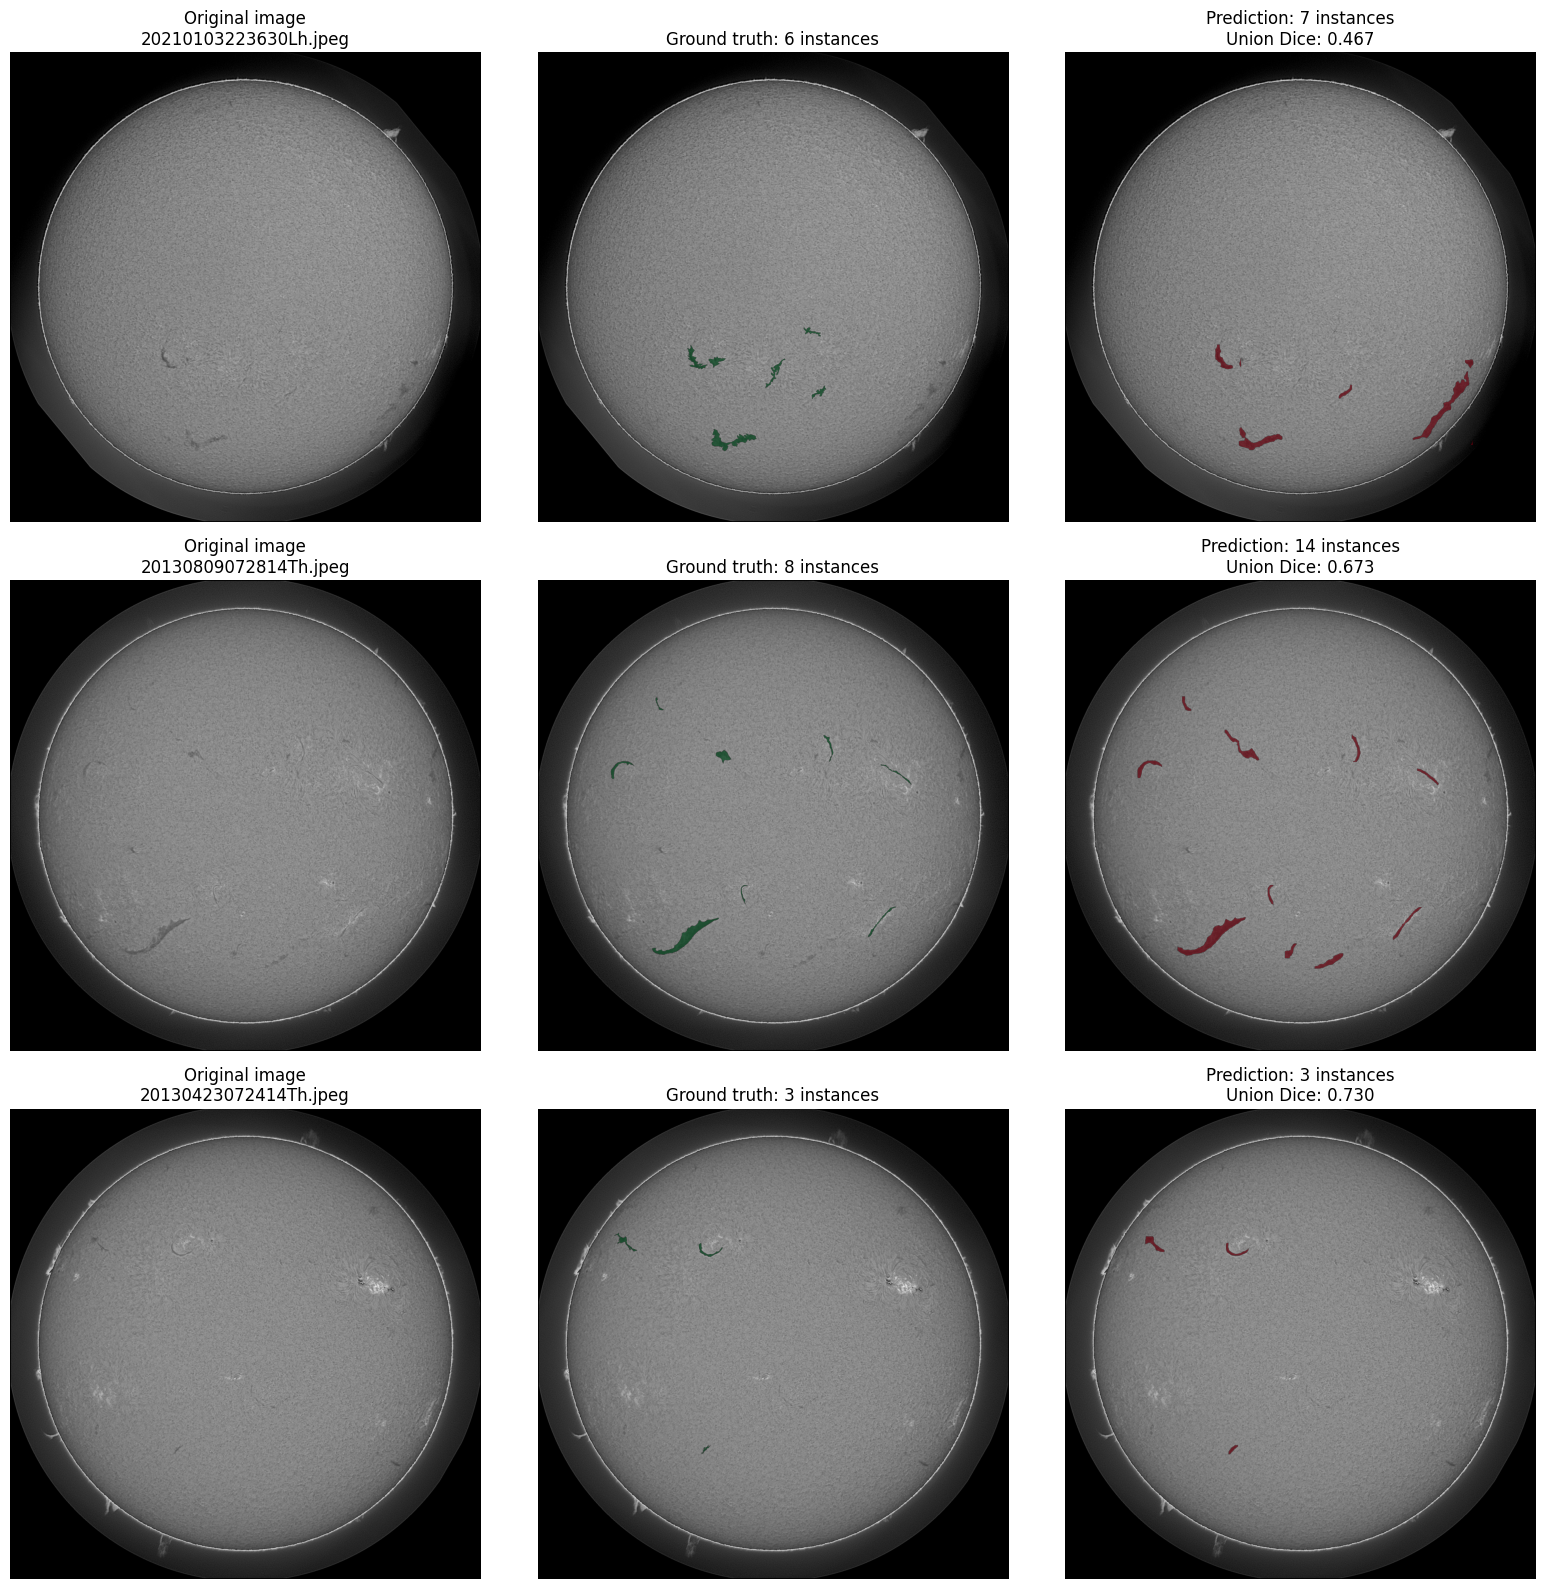


VALIDATION VISUALIZATION SUMMARY
-----------------------------------------------------------------
{'image': '20210103223630Lh.jpeg', 'ground_truth_instances': 6, 'predicted_instances': 7, 'ground_truth_pixels': 14283, 'predicted_pixels': 21147, 'union_dice': 0.4666}
{'image': '20130809072814Th.jpeg', 'ground_truth_instances': 8, 'predicted_instances': 14, 'ground_truth_pixels': 15269, 'predicted_pixels': 27091, 'union_dice': 0.6729}
{'image': '20130423072414Th.jpeg', 'ground_truth_instances': 3, 'predicted_instances': 3, 'ground_truth_pixels': 2899, 'predicted_pixels': 4050, 'union_dice': 0.7302}


In [6]:
from pathlib import Path
from collections import defaultdict
from sklearn.model_selection import train_test_split
from pycocotools import mask as mask_utils
from ultralytics import YOLO
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import random
import json

# ==================================================
# 1. DEFINE PATHS AND LOAD THE TRAINED MODEL
# ==================================================

BASE = Path(
    "/kaggle/input/competitions/filament-segmentation-2026/"
    "MAGFiLO_1.0_Kaggle_2026"
)

IMAGE_DIR = BASE / "train" / "train_images"

ANNOTATION_FILE = (
    BASE / "train" /
    "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
)

WEIGHTS = Path(
    "/kaggle/working/yolo_seg_runs/"
    "solar_filament_seg/weights/best.pt"
)

assert WEIGHTS.is_file(), "Trained model weights not found."
assert ANNOTATION_FILE.is_file(), "Annotation file not found."

model = YOLO(str(WEIGHTS))

print("Model loaded successfully.")
print("Weights:", WEIGHTS)

# ==================================================
# 2. REBUILD THE ORIGINAL VALIDATION SPLIT
# ==================================================

with open(ANNOTATION_FILE, "r") as f:
    data = json.load(f)

selected_records = {}

for record in data["images"]:
    filename = record["file_name"]

    if filename not in selected_records:
        selected_records[filename] = record

annotations_by_id = defaultdict(list)

for ann in data["annotations"]:
    annotations_by_id[ann["image_id"]].append(ann)

unique_filenames = sorted(selected_records.keys())

train_filenames, val_filenames = train_test_split(
    unique_filenames,
    test_size=0.15,
    random_state=42
)

print("Validation images available:", len(val_filenames))

# ==================================================
# 3. SELECT THREE VALIDATION IMAGES
# ==================================================

random_generator = random.Random(42)

sample_filenames = random_generator.sample(
    list(val_filenames),
    3
)

# ==================================================
# 4. PROCESS EACH IMAGE
# ==================================================

fig, axes = plt.subplots(
    3, 3,
    figsize=(16, 16),
    squeeze=False
)

summary = []

for row, filename in enumerate(sample_filenames):

    image_path = IMAGE_DIR / filename

    image = np.asarray(
        Image.open(image_path).convert("RGB")
    )

    height, width = image.shape[:2]

    # ----------------------------------------------
    # Ground-truth masks
    # ----------------------------------------------

    record = selected_records[filename]

    gt_union = np.zeros(
        (height, width),
        dtype=bool
    )

    gt_instance_count = 0

    for ann in annotations_by_id[record["id"]]:

        polygons = ann.get("segmentation", [])

        if not polygons:
            continue

        rles = mask_utils.frPyObjects(
            polygons,
            height,
            width
        )

        decoded = mask_utils.decode(
            mask_utils.merge(rles)
        )

        if decoded.ndim == 3:
            gt_mask = np.any(decoded > 0, axis=2)
        else:
            gt_mask = decoded > 0

        if gt_mask.any():
            gt_union |= gt_mask
            gt_instance_count += 1

    # ----------------------------------------------
    # Model predictions
    # ----------------------------------------------

    result = model.predict(
        source=str(image_path),
        imgsz=1024,
        conf=0.25,
        iou=0.70,
        max_det=150,
        retina_masks=True,
        verbose=False
    )[0]

    pred_union = np.zeros(
        (height, width),
        dtype=bool
    )

    predicted_instance_count = 0

    if result.masks is not None:

        predicted_masks = (
            result.masks.data.detach().cpu().numpy()
        )

        for predicted_mask in predicted_masks:

            predicted_mask = predicted_mask > 0.5

            # Ensure mask dimensions match the original image.
            if predicted_mask.shape != (height, width):

                resized_mask = Image.fromarray(
                    predicted_mask.astype(np.uint8)
                ).resize(
                    (width, height),
                    resample=Image.Resampling.NEAREST
                )

                predicted_mask = (
                    np.asarray(resized_mask) > 0
                )

            if predicted_mask.any():
                pred_union |= predicted_mask
                predicted_instance_count += 1

    # ----------------------------------------------
    # Preliminary union Dice
    # ----------------------------------------------

    intersection = np.logical_and(
        gt_union,
        pred_union
    ).sum()

    denominator = gt_union.sum() + pred_union.sum()

    union_dice = (
        2.0 * intersection + 1.0
    ) / (
        denominator + 1.0
    )

    # ----------------------------------------------
    # Visualize results
    # ----------------------------------------------

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(
        f"Original image\n{filename}"
    )

    axes[row, 1].imshow(image)

    axes[row, 1].imshow(
        np.ma.masked_where(
            ~gt_union,
            gt_union
        ),
        cmap="Greens",
        alpha=0.70,
        vmin=0,
        vmax=1
    )

    axes[row, 1].set_title(
        f"Ground truth: {gt_instance_count} instances"
    )

    axes[row, 2].imshow(image)

    axes[row, 2].imshow(
        np.ma.masked_where(
            ~pred_union,
            pred_union
        ),
        cmap="Reds",
        alpha=0.70,
        vmin=0,
        vmax=1
    )

    axes[row, 2].set_title(
        f"Prediction: {predicted_instance_count} instances"
        f"\nUnion Dice: {union_dice:.3f}"
    )

    for ax in axes[row]:
        ax.axis("off")

    summary.append({
        "image": filename,
        "ground_truth_instances": gt_instance_count,
        "predicted_instances": predicted_instance_count,
        "ground_truth_pixels": int(gt_union.sum()),
        "predicted_pixels": int(pred_union.sum()),
        "union_dice": round(float(union_dice), 4)
    })

plt.tight_layout()
plt.show()

# ==================================================
# 5. PRINT RESULTS
# ==================================================

print("\nVALIDATION VISUALIZATION SUMMARY")
print("-" * 65)

for item in summary:
    print(item)

In [7]:
from pathlib import Path
from collections import defaultdict

import json
import numpy as np
import pandas as pd

from PIL import Image
from sklearn.model_selection import train_test_split
from scipy.optimize import linear_sum_assignment
from pycocotools import mask as mask_utils
from ultralytics import YOLO

# ============================================================
# 1. CONFIGURATION
# ============================================================

BASE = Path(
    "/kaggle/input/competitions/filament-segmentation-2026/"
    "MAGFiLO_1.0_Kaggle_2026"
)

IMAGE_DIR = BASE / "train" / "train_images"

ANNOTATION_FILE = (
    BASE / "train" /
    "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
)

WEIGHTS = Path(
    "/kaggle/working/yolo_seg_runs/"
    "solar_filament_seg/weights/best.pt"
)

THRESHOLDS = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40]

IOU_MATCH_THRESHOLD = 0.50

assert WEIGHTS.is_file(), "Trained model weights not found."
assert ANNOTATION_FILE.is_file(), "Annotation file not found."

model = YOLO(str(WEIGHTS))

print("Model loaded successfully.")

# ============================================================
# 2. REBUILD THE SAME VALIDATION SPLIT
# ============================================================

with open(ANNOTATION_FILE, "r") as f:
    data = json.load(f)

selected_records = {}

for record in data["images"]:
    filename = record["file_name"]

    if filename not in selected_records:
        selected_records[filename] = record

annotations_by_id = defaultdict(list)

for ann in data["annotations"]:
    annotations_by_id[ann["image_id"]].append(ann)

unique_filenames = sorted(selected_records.keys())

train_filenames, val_filenames = train_test_split(
    unique_filenames,
    test_size=0.15,
    random_state=42
)

print("Validation images:", len(val_filenames))

# ============================================================
# 3. PREPARE GROUND-TRUTH INSTANCE MASKS
# ============================================================

def get_ground_truth_rles(filename):

    record = selected_records[filename]

    height = record["height"]
    width = record["width"]

    ground_truth_rles = []

    for ann in annotations_by_id[record["id"]]:

        polygons = ann.get("segmentation", [])

        if not polygons:
            continue

        polygon_rles = mask_utils.frPyObjects(
            polygons,
            height,
            width
        )

        merged_rle = mask_utils.merge(polygon_rles)

        if float(mask_utils.area(merged_rle)) > 0:
            ground_truth_rles.append(merged_rle)

    return ground_truth_rles, height, width

# ============================================================
# 4. RUN INFERENCE ON EACH VALIDATION IMAGE
# ============================================================

# We predict once per image at confidence 0.05.
# Higher thresholds are evaluated by filtering the same results.

cached_predictions = []

for image_number, filename in enumerate(val_filenames, start=1):

    image_path = IMAGE_DIR / filename

    ground_truth_rles, height, width = (
        get_ground_truth_rles(filename)
    )

    result = model.predict(
        source=str(image_path),
        imgsz=1024,
        conf=0.05,
        iou=0.70,
        max_det=100,
        retina_masks=True,
        verbose=False
    )[0]

    prediction_items = []

    if result.boxes is not None and result.masks is not None:

        confidences = (
            result.boxes.conf.detach().cpu().numpy()
        )

        predicted_masks = (
            result.masks.data.detach().cpu().numpy()
        )

        for confidence, predicted_mask in zip(
            confidences, predicted_masks
        ):

            # Thresholds below 0.10 are not part of this sweep.
            if confidence < min(THRESHOLDS):
                continue

            binary_mask = (
                predicted_mask > 0.5
            ).astype(np.uint8)

            # Retina masks should already match the input image.
            # Correct the dimensions if a different shape is returned.
            if binary_mask.shape != (height, width):

                resized_mask = Image.fromarray(
                    binary_mask
                ).resize(
                    (width, height),
                    resample=Image.Resampling.NEAREST
                )

                binary_mask = (
                    np.asarray(resized_mask) > 0
                ).astype(np.uint8)

            if binary_mask.sum() == 0:
                continue

            encoded_mask = mask_utils.encode(
                np.asfortranarray(binary_mask)
            )

            prediction_items.append(
                (float(confidence), encoded_mask)
            )

    cached_predictions.append({
        "filename": filename,
        "ground_truth": ground_truth_rles,
        "predictions": prediction_items
    })

    if image_number % 20 == 0:
        print(
            "Processed",
            image_number,
            "of",
            len(val_filenames),
            "validation images"
        )

print("Inference completed.")

# ============================================================
# 5. CALCULATE INSTANCE-LEVEL PQ
# ============================================================

summary_rows = []

for threshold in THRESHOLDS:

    total_tp = 0
    total_fp = 0
    total_fn = 0
    total_matched_iou = 0.0

    image_pq_values = []
    predicted_counts = []

    for item in cached_predictions:

        ground_truth_rles = item["ground_truth"]

        prediction_rles = [
            rle
            for confidence, rle in item["predictions"]
            if confidence >= threshold
        ]

        gt_count = len(ground_truth_rles)
        pred_count = len(prediction_rles)

        predicted_counts.append(pred_count)

        if gt_count > 0 and pred_count > 0:

            iou_matrix = mask_utils.iou(
                ground_truth_rles,
                prediction_rles,
                [0] * pred_count
            )

            row_indices, col_indices = (
                linear_sum_assignment(1.0 - iou_matrix)
            )

            matched_ious = [
                float(iou_matrix[row, col])
                for row, col in zip(row_indices, col_indices)
                if iou_matrix[row, col] > IOU_MATCH_THRESHOLD
            ]

            tp = len(matched_ious)
            matched_iou_sum = sum(matched_ious)

        else:
            tp = 0
            matched_iou_sum = 0.0

        fp = pred_count - tp
        fn = gt_count - tp

        denominator = tp + 0.5 * fp + 0.5 * fn

        if denominator > 0:
            image_pq = matched_iou_sum / denominator
            image_pq_values.append(image_pq)

        total_tp += tp
        total_fp += fp
        total_fn += fn
        total_matched_iou += matched_iou_sum

    pooled_denominator = (
        total_tp + 0.5 * total_fp + 0.5 * total_fn
    )

    pooled_pq = (
        total_matched_iou / pooled_denominator
        if pooled_denominator > 0
        else 0.0
    )

    mean_image_pq = (
        float(np.mean(image_pq_values))
        if image_pq_values
        else 0.0
    )

    summary_rows.append({
        "confidence": threshold,
        "mean_image_PQ": mean_image_pq,
        "pooled_PQ": pooled_pq,
        "TP": total_tp,
        "FP": total_fp,
        "FN": total_fn,
        "avg_predictions_per_image": float(
            np.mean(predicted_counts)
        )
    })

# ============================================================
# 6. DISPLAY THE RESULTS
# ============================================================

results_df = pd.DataFrame(summary_rows)

print("\nVALIDATION RESULTS BY CONFIDENCE THRESHOLD")
print(results_df.round(4).to_string(index=False))

best_row_index = results_df["mean_image_PQ"].idxmax()

best_row = results_df.loc[best_row_index]

print("\nBEST THRESHOLD BY MEAN IMAGE PQ")
print("Confidence:", best_row["confidence"])
print("Mean image PQ:", round(best_row["mean_image_PQ"], 4))
print("Pooled PQ:", round(best_row["pooled_PQ"], 4))
print("Total true positives:", int(best_row["TP"]))
print("Total false positives:", int(best_row["FP"]))
print("Total false negatives:", int(best_row["FN"]))
print(
    "Average predictions per image:",
    round(best_row["avg_predictions_per_image"], 2)
)

Model loaded successfully.
Validation images: 107
Processed 20 of 107 validation images
Processed 40 of 107 validation images
Processed 60 of 107 validation images
Processed 80 of 107 validation images
Processed 100 of 107 validation images
Inference completed.

VALIDATION RESULTS BY CONFIDENCE THRESHOLD
 confidence  mean_image_PQ  pooled_PQ  TP   FP  FN  avg_predictions_per_image
       0.10         0.2671     0.2693 563 1166 310                    16.1589
       0.15         0.2857     0.2924 527  848 346                    12.8505
       0.20         0.2967     0.3057 494  651 379                    10.7009
       0.25         0.3027     0.3117 455  500 418                     8.9252
       0.30         0.3049     0.3146 425  397 448                     7.6822
       0.35         0.3046     0.3163 398  311 475                     6.6262
       0.40         0.2984     0.3132 371  249 502                     5.7944

BEST THRESHOLD BY MEAN IMAGE PQ
Confidence: 0.3
Mean image PQ: 0.3049

In [8]:
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import FileLink, display

from ultralytics import YOLO
from pycocotools import mask as mask_utils


# ==================================================
# 1. CONFIGURATION
# ==================================================

BASE = Path(
    "/kaggle/input/competitions/filament-segmentation-2026/"
    "MAGFiLO_1.0_Kaggle_2026"
)

TEST_DIR = BASE / "test" / "test_images"

WEIGHTS = Path(
    "/kaggle/working/yolo_seg_runs/"
    "solar_filament_seg/weights/best.pt"
)

OUTPUT_CSV = Path("/kaggle/working/submission.csv")

CONFIDENCE = 0.35
IMAGE_SIZE = 1024
NMS_IOU = 0.70
MAX_DETECTIONS = 100

assert TEST_DIR.is_dir(), "Test image directory not found."
assert WEIGHTS.is_file(), "Trained model weights not found."

test_images = sorted(
    p for p in TEST_DIR.iterdir()
    if p.is_file()
    and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
)

print("Test images found:", len(test_images))
print("Model weights:", WEIGHTS)
print("Confidence threshold:", CONFIDENCE)

assert len(test_images) == 180, (
    f"Expected 180 test images, found {len(test_images)}."
)


# ==================================================
# 2. LOAD THE MODEL
# ==================================================

model = YOLO(str(WEIGHTS))

print("Segmentation model loaded successfully.")


# ==================================================
# 3. PREDICT MASKS AND ENCODE EACH INSTANCE
# ==================================================

submission_rows = []
images_without_predictions = 0
total_predictions = 0

for image_number, image_path in enumerate(test_images, start=1):

    # Read image dimensions.
    with Image.open(image_path) as original_image:
        image_width, image_height = original_image.size

    # The competition uses 2048 x 2048 masks.
    if (image_width, image_height) != (2048, 2048):
        raise ValueError(
            f"Unexpected image dimensions for {image_path.name}: "
            f"{image_width} x {image_height}"
        )

    result = model.predict(
        source=str(image_path),
        imgsz=IMAGE_SIZE,
        conf=CONFIDENCE,
        iou=NMS_IOU,
        max_det=MAX_DETECTIONS,
        retina_masks=True,
        verbose=False
    )[0]

    predicted_count = 0

    if result.masks is not None and result.boxes is not None:

        masks = result.masks.data.detach().cpu().numpy()
        confidences = result.boxes.conf.detach().cpu().numpy()

        # Process detections in descending confidence order.
        order = np.argsort(-confidences)

        instance_number = 1

        for detection_index in order:

            binary_mask = (
                masks[detection_index] > 0.5
            ).astype(np.uint8)

            # Correct dimensions if the returned mask has been
            # generated at a different resolution.
            if binary_mask.shape != (
                image_height, image_width
            ):

                binary_mask = np.asarray(
                    Image.fromarray(binary_mask).resize(
                        (image_width, image_height),
                        resample=Image.Resampling.NEAREST
                    )
                )

                binary_mask = (
                    binary_mask > 0
                ).astype(np.uint8)

            if binary_mask.sum() == 0:
                continue

            # Encode a 2D binary mask as compressed COCO RLE.
            rle = mask_utils.encode(
                np.asfortranarray(binary_mask)
            )

            counts = rle["counts"]

            if isinstance(counts, bytes):
                counts = counts.decode("ascii")
            else:
                counts = str(counts)

            filament_id = (
                f"{image_path.stem}_{instance_number}"
            )

            submission_rows.append({
                "filament_id": filament_id,
                "segmentation_rle": counts
            })

            instance_number += 1
            predicted_count += 1

    if predicted_count == 0:
        images_without_predictions += 1

    total_predictions += predicted_count

    if image_number % 20 == 0:
        print(
            f"Processed {image_number}/{len(test_images)} images; "
            f"predicted instances so far: {total_predictions}"
        )


# ==================================================
# 4. CREATE AND SAVE THE SUBMISSION CSV
# ==================================================

submission = pd.DataFrame(
    submission_rows,
    columns=["filament_id", "segmentation_rle"]
)

submission.to_csv(
    OUTPUT_CSV,
    index=False
)

print("\nSUBMISSION CREATED")
print("-" * 45)
print("Output file:", OUTPUT_CSV)
print("Test images processed:", len(test_images))
print("Predicted filament instances:", len(submission))
print("Images with no predictions:", images_without_predictions)
print("Columns:", submission.columns.tolist())
print("Unique filament IDs:", submission["filament_id"].nunique())
print("Missing filament IDs:", submission["filament_id"].isna().sum())
print("Missing RLE values:", submission["segmentation_rle"].isna().sum())
print("Empty RLE strings:", int(
    (submission["segmentation_rle"].str.len() == 0).sum()
))


# ==================================================
# 5. VERIFY THE OUTPUT
# ==================================================

assert submission.columns.tolist() == [
    "filament_id", "segmentation_rle"
]

assert submission["filament_id"].is_unique
assert submission["filament_id"].notna().all()
assert submission["segmentation_rle"].notna().all()
assert (submission["segmentation_rle"].str.len() > 0).all()

# Decode one prediction to verify that its RLE is valid.
if len(submission) > 0:

    sample_rle = {
        "size": [2048, 2048],
        "counts": submission.iloc[0]["segmentation_rle"].encode("ascii")
    }

    decoded_mask = mask_utils.decode(sample_rle)

    assert decoded_mask.shape == (2048, 2048)

    print("Sample RLE decoding: PASSED")
else:
    print("WARNING: No predictions were generated.")

print("\nFirst five submission rows:")
print(submission.head().to_string(index=False))

print("\nCSV size (MB):", round(
    OUTPUT_CSV.stat().st_size / (1024 * 1024), 2
))

print("\nDOWNLOAD SUBMISSION:")
display(FileLink(str(OUTPUT_CSV)))

Test images found: 180
Model weights: /kaggle/working/yolo_seg_runs/solar_filament_seg/weights/best.pt
Confidence threshold: 0.35
Segmentation model loaded successfully.
Processed 20/180 images; predicted instances so far: 134
Processed 40/180 images; predicted instances so far: 280
Processed 60/180 images; predicted instances so far: 425
Processed 80/180 images; predicted instances so far: 602
Processed 100/180 images; predicted instances so far: 781
Processed 120/180 images; predicted instances so far: 878
Processed 140/180 images; predicted instances so far: 938
Processed 160/180 images; predicted instances so far: 984
Processed 180/180 images; predicted instances so far: 1055

SUBMISSION CREATED
---------------------------------------------
Output file: /kaggle/working/submission.csv
Test images processed: 180
Predicted filament instances: 1055
Images with no predictions: 5
Columns: ['filament_id', 'segmentation_rle']
Unique filament IDs: 1055
Missing filament IDs: 0
Missing RLE va

/kaggle/working/submission.csv

In [9]:
from pathlib import Path
import numpy as np
import pandas as pd
from pycocotools import mask as mask_utils

# --------------------------------------------------
# 1. FILES
# --------------------------------------------------

INPUT_CSV = Path("/kaggle/working/submission.csv")
OUTPUT_CSV = Path("/kaggle/working/submission_no_overlap.csv")

HEIGHT = 2048
WIDTH = 2048

assert INPUT_CSV.is_file(), (
    "submission.csv was not found in /kaggle/working."
)

df = pd.read_csv(INPUT_CSV, dtype=str)

assert list(df.columns) == [
    "filament_id",
    "segmentation_rle"
], "Unexpected submission columns."

assert df["filament_id"].notna().all()
assert df["segmentation_rle"].notna().all()

print("Original predictions:", len(df))

# --------------------------------------------------
# 2. IDENTIFY WHICH IMAGE EACH MASK BELONGS TO
# --------------------------------------------------

# IDs have the form image_stem_1, image_stem_2, etc.
parts = df["filament_id"].str.rsplit("_", n=1, expand=True)

assert parts.shape[1] == 2, "Unexpected filament ID format."
assert parts[1].str.isdigit().all(), (
    "Could not identify instance numbers in filament IDs."
)

df["_image_key"] = parts[0]

# --------------------------------------------------
# 3. REMOVE OVERLAPS
# --------------------------------------------------

corrected_rows = []

removed_empty_masks = 0
masks_modified = 0
overlapping_pixels_removed = 0

for image_key, group in df.groupby("_image_key", sort=False):

    # Pixels already assigned to a higher-confidence mask.
    claimed = np.zeros((HEIGHT, WIDTH), dtype=bool)

    instance_number = 1

    # Preserve the original order: higher-confidence detections first.
    for _, row in group.iterrows():

        rle = {
            "size": [HEIGHT, WIDTH],
            "counts": row["segmentation_rle"].encode("ascii")
        }

        mask = mask_utils.decode(rle).astype(bool)

        assert mask.shape == (HEIGHT, WIDTH), (
            f"Incorrect mask dimensions for {row['filament_id']}"
        )

        original_pixels = int(mask.sum())

        # Assign shared pixels to the earlier, higher-confidence mask.
        corrected_mask = mask & ~claimed

        corrected_pixels = int(corrected_mask.sum())

        overlapping_pixels_removed += (
            original_pixels - corrected_pixels
        )

        if corrected_pixels < original_pixels:
            masks_modified += 1

        # Drop any mask that becomes completely empty.
        if corrected_pixels == 0:
            removed_empty_masks += 1
            continue

        # Claim the pixels so subsequent masks cannot overlap them.
        claimed |= corrected_mask

        encoded = mask_utils.encode(
            np.asfortranarray(corrected_mask.astype(np.uint8))
        )

        counts = encoded["counts"]

        if isinstance(counts, bytes):
            counts = counts.decode("ascii")

        corrected_rows.append({
            "filament_id": f"{image_key}_{instance_number}",
            "segmentation_rle": counts
        })

        instance_number += 1

# --------------------------------------------------
# 4. SAVE THE CORRECTED CSV
# --------------------------------------------------

corrected_df = pd.DataFrame(
    corrected_rows,
    columns=["filament_id", "segmentation_rle"]
)

corrected_df.to_csv(OUTPUT_CSV, index=False)

# --------------------------------------------------
# 5. VERIFY THE OUTPUT
# --------------------------------------------------

assert corrected_df["filament_id"].is_unique
assert corrected_df["segmentation_rle"].notna().all()
assert (corrected_df["segmentation_rle"].str.len() > 0).all()

print("\nOVERLAP CORRECTION COMPLETE")
print("-" * 45)
print("Original masks:", len(df))
print("Corrected masks:", len(corrected_df))
print("Masks modified:", masks_modified)
print("Empty masks removed:", removed_empty_masks)
print("Overlapping pixels reassigned:", overlapping_pixels_removed)
print("Unique filament IDs:", corrected_df["filament_id"].nunique())
print("Output file:", OUTPUT_CSV)

print("\nFirst five corrected rows:")
print(corrected_df.head().to_string(index=False))

Original predictions: 1055

OVERLAP CORRECTION COMPLETE
---------------------------------------------
Original masks: 1055
Corrected masks: 1048
Masks modified: 161
Empty masks removed: 7
Overlapping pixels reassigned: 570864
Unique filament IDs: 1048
Output file: /kaggle/working/submission_no_overlap.csv

First five corrected rows:
       filament_id                                                                                                                                                                                                                                                                                                                                           segmentation_rle
20110120105534Ch_1                                                                                                                                                                                             QjRQ2=bo11O1O1O1M1001O10001OO1N2N101M2O2O01001L3O1N2O100O00011N1N2O2N100OD<N12^OZOdQNm0]n1;O

In [1]:
from pathlib import Path
from IPython.display import FileLink, display
import shutil

TRAIN_DIR = Path(
    "/kaggle/input/competitions/filament-segmentation-2026/"
    "MAGFiLO_1.0_Kaggle_2026/train/train_images"
)

sample = TRAIN_DIR / "20141006224634Lh.jpeg"

assert sample.is_file(), "Sample image not found."

output = Path("/kaggle/working/solar_demo_sample.jpeg")
shutil.copy2(sample, output)

print("Sample image created:", output)
display(FileLink(str(output)))

Sample image created: /kaggle/working/solar_demo_sample.jpeg


/kaggle/working/solar_demo_sample.jpeg

In [2]:
from pathlib import Path
import json
import importlib.util
import torch

# Dataset paths
DATA_ROOT = Path(
    "/kaggle/input/competitions/filament-segmentation-2026/"
    "MAGFiLO_1.0_Kaggle_2026"
)

TRAIN_IMAGE_DIR = DATA_ROOT / "train" / "train_images"
TEST_IMAGE_DIR = DATA_ROOT / "test" / "test_images"
ANNOTATION_FILE = (
    DATA_ROOT / "train" /
    "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
)

# Possible model locations from your earlier training
MODEL_CANDIDATES = [
    Path("/kaggle/working/yolo_seg_runs/solar_filament_seg/weights/best.pt"),
    Path("/kaggle/working/solar_filament_backup/solar_filament_yolo11n_seg_best.pt"),
    Path("/kaggle/working/best.pt"),
]

print("========== ENVIRONMENT ==========")
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\n========== DATASET ==========")
print("Training images directory:", TRAIN_IMAGE_DIR.exists())
print("Test images directory:", TEST_IMAGE_DIR.exists())
print("Annotation file:", ANNOTATION_FILE.exists())

if TRAIN_IMAGE_DIR.exists():
    print("Training image files:", len(list(TRAIN_IMAGE_DIR.glob("*"))))

if TEST_IMAGE_DIR.exists():
    print("Test image files:", len(list(TEST_IMAGE_DIR.glob("*"))))

print("\n========== MODEL WEIGHTS ==========")
MODEL_PATH = None

for candidate in MODEL_CANDIDATES:
    print(candidate, "->", candidate.is_file())
    if candidate.is_file() and MODEL_PATH is None:
        MODEL_PATH = candidate

print("Selected model:", MODEL_PATH)

print("\n========== REQUIRED LIBRARIES ==========")
for package in ["ultralytics", "pycocotools", "sklearn", "cv2", "pandas", "matplotlib"]:
    print(f"{package}: {importlib.util.find_spec(package) is not None}")

if ANNOTATION_FILE.is_file():
    with open(ANNOTATION_FILE, "r") as f:
        coco = json.load(f)

    print("\n========== ANNOTATION SUMMARY ==========")
    print("Image records:", len(coco["images"]))
    print("Annotation records:", len(coco["annotations"]))
    print("Categories:", coco["categories"])

print("\n========== CHECK COMPLETE ==========")

========== ENVIRONMENT ==========
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4

========== DATASET ==========
Training images directory: True
Test images directory: True
Annotation file: True
Training image files: 707
Test image files: 180

========== MODEL WEIGHTS ==========
/kaggle/working/yolo_seg_runs/solar_filament_seg/weights/best.pt -> False
/kaggle/working/solar_filament_backup/solar_filament_yolo11n_seg_best.pt -> False
/kaggle/working/best.pt -> False
Selected model: None

========== REQUIRED LIBRARIES ==========
ultralytics: False
pycocotools: True
sklearn: True
cv2: True
pandas: True
matplotlib: True

========== ANNOTATION SUMMARY ==========
Image records: 1154
Annotation records: 8199
Categories: [{'supercategory': 'filament', 'id': 1, 'name': 'Left'}, {'supercategory': 'filament', 'id': 2, 'name': 'Right'}, {'supercategory': 'filament', 'id': 3, 'name': 'Unidentifiable'}, {'supercategory': 'filament', 'id': 4, 'name': 'Ambiguous'}]

========== CHECK COMPLETE =

In [3]:
from pathlib import Path

SEARCH_ROOTS = [
    Path("/kaggle/input"),
    Path("/kaggle/working"),
]

FOUND_MODELS = []
FOUND_ARCHIVES = []

print("Searching for trained model weights and backup archives...\n")

for root in SEARCH_ROOTS:
    if not root.exists():
        continue

    for path in root.rglob("*"):
        if not path.is_file():
            continue

        name = path.name.lower()

        if name.endswith(".pt") and (
            "best" in name
            or "solar_filament" in name
            or "yolo" in name
        ):
            FOUND_MODELS.append(path)

        elif name.endswith(".zip") and (
            "solar_filament" in name
            or "model" in name
            or "backup" in name
        ):
            FOUND_ARCHIVES.append(path)

print("========== MODEL WEIGHTS ==========")
if FOUND_MODELS:
    for path in FOUND_MODELS:
        print(f"{path} ({path.stat().st_size / (1024**2):.2f} MB)")
else:
    print("No matching .pt model weights found.")

print("\n========== BACKUP ARCHIVES ==========")
if FOUND_ARCHIVES:
    for path in FOUND_ARCHIVES:
        print(f"{path} ({path.stat().st_size / (1024**2):.2f} MB)")
else:
    print("No matching backup archives found.")

print("\n========== SEARCH COMPLETE ==========")

Searching for trained model weights and backup archives...

========== MODEL WEIGHTS ==========
No matching .pt model weights found.

========== BACKUP ARCHIVES ==========
No matching backup archives found.

========== SEARCH COMPLETE ==========


In [4]:
from pathlib import Path

for root in [Path("/kaggle/working"), Path("/kaggle/input")]:
    print(f"\nSearching: {root}")

    if root.exists():
        for path in root.rglob("*.pt"):
            print(path)


Searching: /kaggle/working

Searching: /kaggle/input
/kaggle/input/datasets/joshjj123/backup/solar_filament_yolo11n_seg_best.pt


In [5]:
from pathlib import Path
import subprocess
import sys

# Path confirmed from your Kaggle screenshot
MODEL_PATH = Path(
    "/kaggle/input/datasets/joshjj123/backup/solar_filament_yolo11n_seg_best.pt"
)

# 1. Verify model file
print("========== MODEL VERIFICATION ==========")

if not MODEL_PATH.is_file():
    raise FileNotFoundError(
        f"Model not found at: {MODEL_PATH}\n"
        "Check the path displayed in your Kaggle notebook."
    )

print("Model found:", MODEL_PATH)
print(f"Model size: {MODEL_PATH.stat().st_size / (1024**2):.2f} MB")

# 2. Install Ultralytics if necessary
print("\n========== ULTRALYTICS INSTALLATION ==========")

result = subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "ultralytics"],
    capture_output=True,
    text=True
)

if result.returncode != 0:
    print(result.stderr[-4000:])
    raise RuntimeError("Ultralytics installation failed.")

print("Ultralytics installation command completed.")

# 3. Import and load the actual trained model
print("\n========== LOADING TRAINED MODEL ==========")

import ultralytics
import torch
from ultralytics import YOLO

print("Ultralytics version:", ultralytics.__version__)
print("CUDA available:", torch.cuda.is_available())

model = YOLO(str(MODEL_PATH))

print("Model loaded successfully.")
print("Task:", model.task)
print("Device:", "cuda:0" if torch.cuda.is_available() else "cpu")
print("Class names:", model.names)

assert model.task == "segment", (
    f"Expected an instance-segmentation model, but found task: {model.task}"
)

print("\nMODEL VERIFICATION PASSED")

========== MODEL VERIFICATION ==========
Model found: /kaggle/input/datasets/joshjj123/backup/solar_filament_yolo11n_seg_best.pt
Model size: 5.83 MB

========== ULTRALYTICS INSTALLATION ==========
Ultralytics installation command completed.

========== LOADING TRAINED MODEL ==========
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics version: 8.4.190
CUDA available: True
Model loaded successfully.
Task: segment
Device: cuda:0
Class names: {0: 'filament'}

MODEL VERIFICATION PASSED


In [8]:
from pathlib import Path
import json
from collections import Counter

from sklearn.model_selection import train_test_split

DATA_ROOT = Path(
    "/kaggle/input/competitions/filament-segmentation-2026/"
    "MAGFiLO_1.0_Kaggle_2026"
)

TRAIN_IMAGE_DIR = DATA_ROOT / "train" / "train_images"
ANNOTATION_FILE = (
    DATA_ROOT / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
)

# Load the competition annotations.
with open(ANNOTATION_FILE, "r", encoding="utf-8") as f:
    coco = json.load(f)

images = coco["images"]
annotations = coco["annotations"]

print("========== ANNOTATION STRUCTURE ==========")
print("Image records:", len(images))
print("Annotation records:", len(annotations))
print("First image record:", images[0])
print("First annotation record:", annotations[0])

# Check which fields identify images and annotations.
print("\nImage record keys:", list(images[0].keys()))
print("Annotation record keys:", list(annotations[0].keys()))

# Count annotation records per filename.
filename_counts = Counter(
    image.get("file_name") for image in images
)

print("\n========== IMAGE RECORD COUNTS ==========")
print("Unique filenames in JSON:", len(filename_counts))
print(
    "Filenames with multiple image records:",
    sum(count > 1 for count in filename_counts.values())
)

# Reproduce the previously used deterministic selection:
# retain the first JSON image record for each filename.
selected_images = []
seen_filenames = set()

for image in images:
    filename = image.get("file_name")

    if filename not in seen_filenames:
        selected_images.append(image)
        seen_filenames.add(filename)

unique_filenames = [image["file_name"] for image in selected_images]

train_filenames, val_filenames = train_test_split(
    unique_filenames,
    test_size=0.15,
    random_state=42
)

train_set = set(train_filenames)
val_set = set(val_filenames)

print("\n========== RECONSTRUCTED SPLIT ==========")
print("Selected image records:", len(selected_images))
print("Training filenames:", len(train_set))
print("Validation filenames:", len(val_set))
print("Train/validation overlap:", len(train_set & val_set))

# Verify that the files physically exist.
missing_train = [
    name for name in train_filenames
    if not (TRAIN_IMAGE_DIR / name).is_file()
]
missing_val = [
    name for name in val_filenames
    if not (TRAIN_IMAGE_DIR / name).is_file()
]

print("\n========== FILE VERIFICATION ==========")
print("Missing training images:", len(missing_train))
print("Missing validation images:", len(missing_val))

if missing_train:
    print("Examples of missing training files:", missing_train[:5])

if missing_val:
    print("Examples of missing validation files:", missing_val[:5])

# Count annotations associated with selected image records.
selected_image_ids = {image["id"] for image in selected_images}

selected_annotations = [
    ann for ann in annotations
    if ann["image_id"] in selected_image_ids
]

train_image_ids = {
    image["id"] for image in selected_images
    if image["file_name"] in train_set
}
val_image_ids = {
    image["id"] for image in selected_images
    if image["file_name"] in val_set
}

train_annotation_count = sum(
    ann["image_id"] in train_image_ids
    for ann in selected_annotations
)
val_annotation_count = sum(
    ann["image_id"] in val_image_ids
    for ann in selected_annotations
)

print("\n========== ANNOTATION COUNTS ==========")
print("Selected training annotations:", train_annotation_count)
print("Selected validation annotations:", val_annotation_count)

assert len(train_set) == 600, (
    f"Expected 600 training filenames, got {len(train_set)}"
)
assert len(val_set) == 107, (
    f"Expected 107 validation filenames, got {len(val_set)}"
)
assert not (train_set & val_set), "Data leakage detected."
assert not missing_train, "Some training images are missing."
assert not missing_val, "Some validation images are missing."

print("\nSPLIT VERIFICATION PASSED")


========== ANNOTATION STRUCTURE ==========
Image records: 1154
Annotation records: 8199
First image record: {'license': 1, 'file_name': '20140609195854Bh.jpeg', 'url': 'https://gong2.nso.edu/HA/hag/201406/20140609/20140609195854Bh.jpg', 'height': 2048, 'width': 2048, 'date_captured': '2014-06-09 19:58:54', 'id': '040301-20140609195854Bh'}
First annotation record: {'segmentation': [[480.9382, 850.955, 480.307, 852.0535, 478.2989, 852.451, 476.1202, 851.3087, 471.8813, 845.6188, 469.2107, 844.1978, 460.0, 845.0, 459.0, 844.0, 455.9884, 843.2471, 452.2964, 839.9584, 450.6544, 839.7575, 449.7991, 838.6671, 450.223, 837.6258, 447.5581, 834.6278, 445.4449, 829.1312, 442.9577, 825.6077, 441.8277, 824.4777, 438.6437, 823.5973, 439.0, 821.0, 436.0, 818.0, 435.1557, 815.4672, 433.9753, 817.121, 431.9582, 816.9118, 431.3678, 815.4732, 432.1225, 813.1225, 428.0, 809.0, 426.5642, 809.0, 425.6041, 807.9655, 424.4241, 807.9655, 423.838, 809.0, 421.2093, 807.6935, 417.3793, 808.1037, 414.8921, 809.554

In [9]:
import json
from pathlib import Path
from collections import defaultdict
from sklearn.model_selection import train_test_split

DATA_ROOT = Path(
    "/kaggle/input/competitions/filament-segmentation-2026/"
    "MAGFiLO_1.0_Kaggle_2026"
)

ANNOTATION_FILE = (
    DATA_ROOT / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
)

with open(ANNOTATION_FILE, "r", encoding="utf-8") as f:
    data = json.load(f)

# Step 1: Keep the first image record for each physical filename.
selected_records = {}

for record in data["images"]:
    selected_records.setdefault(record["file_name"], record)

# Step 2: Reproduce the original sorted filename split.
all_filenames = sorted(selected_records.keys())

train_filenames, val_filenames = train_test_split(
    all_filenames,
    test_size=0.15,
    random_state=42
)

train_set = set(train_filenames)
val_set = set(val_filenames)

# Step 3: Group annotations by image ID.
annotations_by_image = defaultdict(list)

for ann in data["annotations"]:
    annotations_by_image[ann["image_id"]].append(ann)

# Step 4: Count annotations for the selected image records.
train_instances = sum(
    len(annotations_by_image[selected_records[name]["id"]])
    for name in train_filenames
)

val_instances = sum(
    len(annotations_by_image[selected_records[name]["id"]])
    for name in val_filenames
)

print("========== ORIGINAL SPLIT RECONSTRUCTION ==========")
print("Unique physical images:", len(all_filenames))
print("Training images:", len(train_filenames))
print("Validation images:", len(val_filenames))
print("Training instances:", train_instances)
print("Validation instances:", val_instances)
print("Total selected instances:", train_instances + val_instances)
print("Image overlap:", len(train_set & val_set))

assert len(train_filenames) == 600
assert len(val_filenames) == 107
assert not (train_set & val_set)

assert train_instances == 4336, (
    f"Expected 4336 training instances, got {train_instances}"
)
assert val_instances == 873, (
    f"Expected 873 validation instances, got {val_instances}"
)

print("\nSUCCESS: Original split counts reproduced.")

========== ORIGINAL SPLIT RECONSTRUCTION ==========
Unique physical images: 707
Training images: 600
Validation images: 107
Training instances: 4336
Validation instances: 873
Total selected instances: 5209
Image overlap: 0

SUCCESS: Original split counts reproduced.


========== SAMPLE IMAGE ==========
Filename: 20160223173514Mh.jpeg
Image dimensions: (2048, 2048)
Ground-truth instances: 6
Predicted instances at confidence 0.30: 5
Ground-truth mask areas (first 10): [2454, 2410, 6117, 1067, 3434, 1079]
Prediction confidence scores: [0.8510000109672546, 0.7519999742507935, 0.6800000071525574, 0.6079999804496765, 0.3370000123977661]


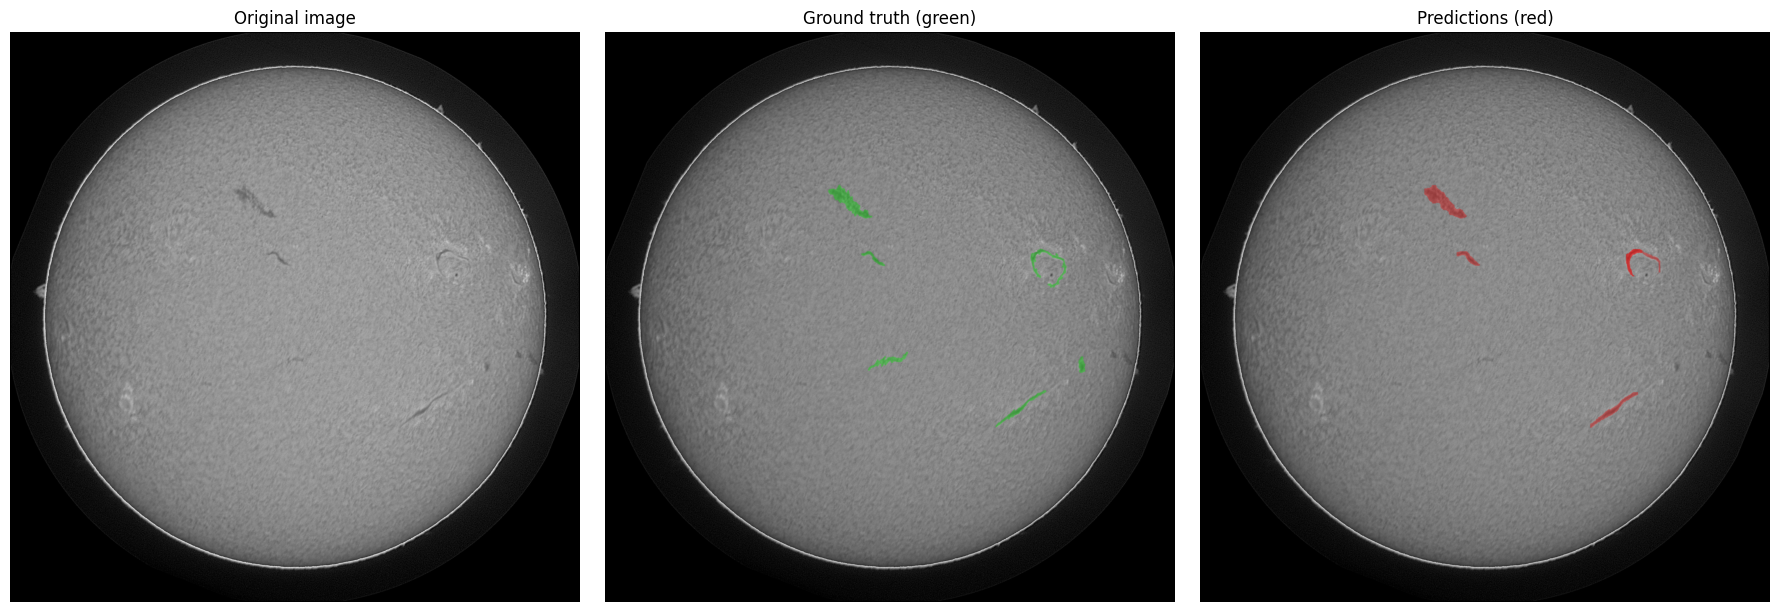

In [10]:
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict
from ultralytics import YOLO
from IPython.display import display

# Paths
DATA_ROOT = Path(
    "/kaggle/input/competitions/filament-segmentation-2026/"
    "MAGFiLO_1.0_Kaggle_2026"
)
TRAIN_IMAGE_DIR = DATA_ROOT / "train" / "train_images"
ANNOTATION_FILE = (
    DATA_ROOT / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
)
MODEL_PATH = Path(
    "/kaggle/input/datasets/joshjj123/backup/"
    "solar_filament_yolo11n_seg_best.pt"
)

# Load annotations and trained model
with open(ANNOTATION_FILE, "r", encoding="utf-8") as f:
    data = json.load(f)

model = YOLO(str(MODEL_PATH))

# Select the first record per filename, as in the original pipeline.
selected_records = {}

for record in data["images"]:
    selected_records.setdefault(record["file_name"], record)

# Reproduce the original sorted validation split.
from sklearn.model_selection import train_test_split

all_filenames = sorted(selected_records.keys())
_, val_filenames = train_test_split(
    all_filenames,
    test_size=0.15,
    random_state=42
)

# Pick the first validation image that has annotations.
annotations_by_image = defaultdict(list)

for ann in data["annotations"]:
    annotations_by_image[ann["image_id"]].append(ann)

sample_record = None

for filename in val_filenames:
    record = selected_records[filename]

    if annotations_by_image[record["id"]]:
        sample_record = record
        break

if sample_record is None:
    raise RuntimeError("No annotated validation image was found.")

image_path = TRAIN_IMAGE_DIR / sample_record["file_name"]

image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

if image is None:
    raise FileNotFoundError(f"Could not read image: {image_path}")

height, width = image.shape
ground_truth_masks = []

# Convert each polygon annotation into a separate binary instance mask.
for ann in annotations_by_image[sample_record["id"]]:
    mask = np.zeros((height, width), dtype=np.uint8)
    segmentation = ann.get("segmentation", [])

    if not isinstance(segmentation, list):
        continue

    for polygon in segmentation:
        if not isinstance(polygon, list) or len(polygon) < 6:
            continue

        points = np.asarray(polygon, dtype=np.float32).reshape(-1, 2)
        points = np.round(points).astype(np.int32)

        cv2.fillPoly(mask, [points], 1)

    if mask.any():
        ground_truth_masks.append(mask)

# Predict using the trained instance-segmentation model.
prediction = model.predict(
    source=str(image_path),
    conf=0.30,
    imgsz=1024,
    device=0,
    verbose=False
)[0]

pred_masks = []

if prediction.masks is not None:
    pred_masks = (
        prediction.masks.data.detach().cpu().numpy() > 0.5
    )

print("========== SAMPLE IMAGE ==========")
print("Filename:", sample_record["file_name"])
print("Image dimensions:", image.shape)
print("Ground-truth instances:", len(ground_truth_masks))
print("Predicted instances at confidence 0.30:", len(pred_masks))
print(
    "Ground-truth mask areas (first 10):",
    [int(mask.sum()) for mask in ground_truth_masks[:10]]
)

if prediction.boxes is not None and len(prediction.boxes):
    print(
        "Prediction confidence scores:",
        np.round(
            prediction.boxes.conf.detach().cpu().numpy(),
            3
        ).tolist()
    )
else:
    print("Prediction confidence scores: []")

# Visualize the image and combined ground-truth/predicted masks.
gt_overlay = cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)
pred_overlay = gt_overlay.copy()

for mask in ground_truth_masks:
    gt_overlay[mask.astype(bool)] = (
        0.65 * gt_overlay[mask.astype(bool)]
        + 0.35 * np.array([0, 255, 0])
    ).astype(np.uint8)

for mask in pred_masks:
    resized_mask = cv2.resize(
        mask.astype(np.uint8),
        (width, height),
        interpolation=cv2.INTER_NEAREST
    ).astype(bool)

    pred_overlay[resized_mask] = (
        0.65 * pred_overlay[resized_mask]
        + 0.35 * np.array([255, 0, 0])
    ).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original image")

axes[1].imshow(gt_overlay)
axes[1].set_title("Ground truth (green)")

axes[2].imshow(pred_overlay)
axes[2].set_title("Predictions (red)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
# ============================================================
# SOLAR FILAMENT SEGMENTATION: COMPLETE MODEL EVALUATION
# Model: Trained YOLO11n-seg
# Dataset: Original 107-image validation split
# ============================================================

import json
import time
import warnings
from pathlib import Path
from collections import defaultdict

import cv2
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from ultralytics import YOLO

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

DATA_ROOT = Path(
    "/kaggle/input/competitions/filament-segmentation-2026/"
    "MAGFiLO_1.0_Kaggle_2026"
)

IMAGE_DIR = DATA_ROOT / "train" / "train_images"

ANNOTATION_FILE = (
    DATA_ROOT / "train" /
    "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
)

MODEL_PATH = Path(
    "/kaggle/input/datasets/joshjj123/backup/"
    "solar_filament_yolo11n_seg_best.pt"
)

CONF_THRESHOLD = 0.30
IMAGE_SIZE = 1024

# ------------------------------------------------------------
# 2. VERIFY ENVIRONMENT AND LOAD MODEL
# ------------------------------------------------------------

print("=" * 65)
print("SOLAR FILAMENT SEGMENTATION MODEL EVALUATION")
print("=" * 65)

assert IMAGE_DIR.is_dir(), f"Image directory missing: {IMAGE_DIR}"
assert ANNOTATION_FILE.is_file(), "Annotation JSON not found."
assert MODEL_PATH.is_file(), "Trained model weights not found."

with open(ANNOTATION_FILE, "r", encoding="utf-8") as f:
    coco = json.load(f)

model = YOLO(str(MODEL_PATH))

assert model.task == "segment", (
    f"Expected segmentation model, received {model.task}"
)

print("Model:", MODEL_PATH.name)
print("Ultralytics:", __import__("ultralytics").__version__)
print("Device:", "GPU" if torch.cuda.is_available() else "CPU")
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

# ------------------------------------------------------------
# 3. RECONSTRUCT THE ORIGINAL VALIDATION SPLIT
# ------------------------------------------------------------

# Preserve the first annotation-image record for each filename.
selected_records = {}

for record in coco["images"]:
    selected_records.setdefault(record["file_name"], record)

all_filenames = sorted(selected_records.keys())

train_filenames, val_filenames = train_test_split(
    all_filenames,
    test_size=0.15,
    random_state=42
)

assert len(train_filenames) == 600
assert len(val_filenames) == 107
assert not (set(train_filenames) & set(val_filenames))

# Index annotations by image ID.
annotations_by_image = defaultdict(list)

for ann in coco["annotations"]:
    annotations_by_image[ann["image_id"]].append(ann)

# ------------------------------------------------------------
# 4. CONVERT POLYGONS INTO INSTANCE MASKS
# ------------------------------------------------------------

def annotation_to_mask(annotation, height, width):
    """
    Convert COCO polygon segmentation coordinates to a binary mask.
    """
    mask = np.zeros((height, width), dtype=np.uint8)
    segmentation = annotation.get("segmentation", [])

    if not isinstance(segmentation, list):
        return mask

    for polygon in segmentation:
        if not isinstance(polygon, list) or len(polygon) < 6:
            continue

        points = np.asarray(
            polygon, dtype=np.float32
        ).reshape(-1, 2)

        points = np.rint(points).astype(np.int32)

        # Ignore malformed polygons.
        if len(points) >= 3:
            cv2.fillPoly(mask, [points], 1)

    return mask


def get_ground_truth_masks(image_record, height, width):
    """
    Return nonempty ground-truth instance masks for one image.
    """
    masks = []

    for annotation in annotations_by_image[image_record["id"]]:
        mask = annotation_to_mask(annotation, height, width)

        if mask.any():
            masks.append(mask.astype(bool))

    return masks


def resize_prediction_mask(mask, height, width):
    """
    Resize a predicted mask to the original image dimensions.
    """
    mask = np.asarray(mask)

    if mask.shape != (height, width):
        mask = cv2.resize(
            mask.astype(np.uint8),
            (width, height),
            interpolation=cv2.INTER_NEAREST
        )

    return mask > 0


# ------------------------------------------------------------
# 5. INSTANCE MATCHING AND IOU
# ------------------------------------------------------------

def calculate_iou_matrix(gt_masks, pred_masks):
    """
    Calculate pairwise binary-mask IoU.
    """
    matrix = np.zeros(
        (len(gt_masks), len(pred_masks)),
        dtype=np.float32
    )

    for i, gt in enumerate(gt_masks):
        for j, pred in enumerate(pred_masks):
            intersection = np.logical_and(gt, pred).sum()
            union = np.logical_or(gt, pred).sum()

            matrix[i, j] = (
                intersection / union if union > 0 else 0.0
            )

    return matrix


def greedy_match(iou_matrix, threshold=0.50):
    """
    Match instances one-to-one, choosing the highest IoU pairs first.
    A pair is valid only when IoU > threshold.
    """
    num_gt, num_pred = iou_matrix.shape

    if num_gt == 0 or num_pred == 0:
        return [], set(), set()

    candidates = []

    for i in range(num_gt):
        for j in range(num_pred):
            iou = float(iou_matrix[i, j])

            if iou > threshold:
                candidates.append((iou, i, j))

    candidates.sort(reverse=True)

    matched_gt = set()
    matched_pred = set()
    matches = []

    for iou, i, j in candidates:
        if i not in matched_gt and j not in matched_pred:
            matched_gt.add(i)
            matched_pred.add(j)
            matches.append((i, j, iou))

    return matches, matched_gt, matched_pred


# ------------------------------------------------------------
# 6. RUN INFERENCE ON ALL VALIDATION IMAGES
# ------------------------------------------------------------

image_results = []
all_predictions = []
all_ground_truth_count = 0

total_pixel_tp = 0
total_pixel_fp = 0
total_pixel_fn = 0
total_pixel_tn = 0

total_instance_tp = 0
total_instance_fp = 0
total_instance_fn = 0
total_matched_iou = 0.0

per_image_pq = []
per_image_sq = []
per_image_rq = []

total_inference_seconds = 0.0
total_images_evaluated = 0

print("\nStarting validation inference...")
print("Validation images:", len(val_filenames))
print("Confidence threshold:", CONF_THRESHOLD)
print("Image size:", IMAGE_SIZE)

for index, filename in enumerate(val_filenames, start=1):

    record = selected_records[filename]
    image_path = IMAGE_DIR / filename

    image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

    if image is None:
        raise FileNotFoundError(
            f"Could not load validation image: {image_path}"
        )

    height, width = image.shape

    gt_masks = get_ground_truth_masks(
        record, height, width
    )

    # Time prediction generation. CUDA timings require synchronization.
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    result = model.predict(
        source=str(image_path),
        conf=CONF_THRESHOLD,
        imgsz=IMAGE_SIZE,
        device=0 if torch.cuda.is_available() else "cpu",
        verbose=False
    )[0]

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    inference_seconds = time.perf_counter() - start_time

    total_inference_seconds += inference_seconds
    total_images_evaluated += 1

    pred_masks = []
    pred_scores = []

    if result.masks is not None and result.boxes is not None:
        raw_masks = (
            result.masks.data.detach().cpu().numpy()
        )
        pred_scores = (
            result.boxes.conf.detach().cpu().numpy().tolist()
        )

        for raw_mask in raw_masks:
            pred_masks.append(
                resize_prediction_mask(raw_mask, height, width)
            )

    # Keep mask and confidence arrays aligned.
    if len(pred_scores) != len(pred_masks):
        raise RuntimeError(
            f"Prediction mismatch for {filename}: "
            f"{len(pred_scores)} scores vs {len(pred_masks)} masks"
        )

    # Pixel-level metrics: compare union of all filament instances.
    gt_union = np.zeros((height, width), dtype=bool)
    pred_union = np.zeros((height, width), dtype=bool)

    for mask in gt_masks:
        gt_union |= mask

    for mask in pred_masks:
        pred_union |= mask

    pixel_tp = int(np.logical_and(gt_union, pred_union).sum())
    pixel_fp = int(np.logical_and(~gt_union, pred_union).sum())
    pixel_fn = int(np.logical_and(gt_union, ~pred_union).sum())
    pixel_tn = int(np.logical_and(~gt_union, ~pred_union).sum())

    total_pixel_tp += pixel_tp
    total_pixel_fp += pixel_fp
    total_pixel_fn += pixel_fn
    total_pixel_tn += pixel_tn

    # Instance-level metrics.
    iou_matrix = calculate_iou_matrix(gt_masks, pred_masks)

    matches, matched_gt, matched_pred = greedy_match(
        iou_matrix, threshold=0.50
    )

    tp = len(matches)
    fp = len(pred_masks) - tp
    fn = len(gt_masks) - tp

    matched_iou_sum = sum(match[2] for match in matches)

    total_instance_tp += tp
    total_instance_fp += fp
    total_instance_fn += fn
    total_matched_iou += matched_iou_sum

    # Per-image PQ / SQ / RQ.
    denominator = tp + 0.5 * fp + 0.5 * fn

    pq = (
        matched_iou_sum / denominator
        if denominator > 0 else 0.0
    )

    sq = (
        matched_iou_sum / tp
        if tp > 0 else 0.0
    )

    rq = (
        tp / denominator
        if denominator > 0 else 0.0
    )

    per_image_pq.append(pq)
    per_image_sq.append(sq)
    per_image_rq.append(rq)

    all_ground_truth_count += len(gt_masks)

    # Store predictions for mask mAP calculation.
    all_predictions.append({
        "filename": filename,
        "gt_masks": gt_masks,
        "pred_masks": pred_masks,
        "scores": pred_scores,
    })

    image_results.append({
        "filename": filename,
        "ground_truth_instances": len(gt_masks),
        "predicted_instances": len(pred_masks),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "PQ": pq,
        "SQ": sq,
        "RQ": rq,
        "inference_seconds": inference_seconds,
    })

    if index % 10 == 0 or index == len(val_filenames):
        print(
            f"Processed {index}/{len(val_filenames)} images"
        )

# ------------------------------------------------------------
# 7. PIXEL-LEVEL METRICS
# ------------------------------------------------------------

def safe_divide(numerator, denominator):
    return (
        numerator / denominator
        if denominator != 0 else 0.0
    )


pixel_precision = safe_divide(
    total_pixel_tp,
    total_pixel_tp + total_pixel_fp
)

pixel_recall = safe_divide(
    total_pixel_tp,
    total_pixel_tp + total_pixel_fn
)

pixel_f1 = safe_divide(
    2 * pixel_precision * pixel_recall,
    pixel_precision + pixel_recall
)

pixel_iou = safe_divide(
    total_pixel_tp,
    total_pixel_tp + total_pixel_fp + total_pixel_fn
)

pixel_dice = safe_divide(
    2 * total_pixel_tp,
    2 * total_pixel_tp + total_pixel_fp + total_pixel_fn
)

pixel_accuracy = safe_divide(
    total_pixel_tp + total_pixel_tn,
    total_pixel_tp + total_pixel_fp +
    total_pixel_fn + total_pixel_tn
)

# ------------------------------------------------------------
# 8. INSTANCE-LEVEL METRICS AND PANOPTIC QUALITY
# ------------------------------------------------------------

instance_precision = safe_divide(
    total_instance_tp,
    total_instance_tp + total_instance_fp
)

instance_recall = safe_divide(
    total_instance_tp,
    total_instance_tp + total_instance_fn
)

instance_f1 = safe_divide(
    2 * instance_precision * instance_recall,
    instance_precision + instance_recall
)

instance_denominator = (
    total_instance_tp
    + 0.5 * total_instance_fp
    + 0.5 * total_instance_fn
)

pooled_pq = safe_divide(
    total_matched_iou,
    instance_denominator
)

pooled_sq = safe_divide(
    total_matched_iou,
    total_instance_tp
)

pooled_rq = safe_divide(
    total_instance_tp,
    instance_denominator
)

# ------------------------------------------------------------
# 9. MASK AP / mAP AT IOU THRESHOLDS
# ------------------------------------------------------------

def calculate_mask_ap(records, iou_threshold):
    """
    Calculate one-class mask AP using confidence-ranked predictions
    and one-to-one matching against ground-truth masks per image.

    AP uses the interpolated precision envelope and 101 recall points.
    """
    total_gt = sum(len(item["gt_masks"]) for item in records)

    if total_gt == 0:
        return 0.0

    ranked_predictions = []

    for image_index, item in enumerate(records):
        for pred_index, score in enumerate(item["scores"]):
            ranked_predictions.append((
                float(score),
                image_index,
                pred_index
            ))

    ranked_predictions.sort(key=lambda item: item[0], reverse=True)

    matched_gt_by_image = [
        set() for _ in records
    ]

    tp_flags = []
    fp_flags = []

    for score, image_index, pred_index in ranked_predictions:
        item = records[image_index]
        gt_masks = item["gt_masks"]
        pred_masks = item["pred_masks"]

        if len(gt_masks) == 0:
            tp_flags.append(0)
            fp_flags.append(1)
            continue

        iou_matrix = calculate_iou_matrix(
            gt_masks,
            [pred_masks[pred_index]]
        )

        best_gt = int(np.argmax(iou_matrix[:, 0]))
        best_iou = float(iou_matrix[best_gt, 0])

        if (
            best_iou > iou_threshold
            and best_gt not in matched_gt_by_image[image_index]
        ):
            matched_gt_by_image[image_index].add(best_gt)
            tp_flags.append(1)
            fp_flags.append(0)
        else:
            tp_flags.append(0)
            fp_flags.append(1)

    if not tp_flags:
        return 0.0

    tp_cumulative = np.cumsum(tp_flags)
    fp_cumulative = np.cumsum(fp_flags)

    recalls = tp_cumulative / total_gt
    precisions = tp_cumulative / np.maximum(
        tp_cumulative + fp_cumulative, 1
    )

    # Precision envelope.
    precision_envelope = np.maximum.accumulate(
        precisions[::-1]
    )[::-1]

    recall_points = np.linspace(0.0, 1.0, 101)
    interpolated_precision = []

    for recall_point in recall_points:
        valid = recalls >= recall_point

        interpolated_precision.append(
            float(np.max(precision_envelope[valid]))
            if np.any(valid) else 0.0
        )

    return float(np.mean(interpolated_precision))


iou_thresholds = np.arange(0.50, 0.96, 0.05)

mask_ap_results = {}

for threshold in iou_thresholds:
    ap = calculate_mask_ap(
        all_predictions,
        iou_threshold=float(threshold)
    )

    mask_ap_results[f"Mask AP@{threshold:.2f}"] = ap

mask_map50 = mask_ap_results["Mask AP@0.50"]
mask_map50_95 = float(np.mean(list(mask_ap_results.values())))

# ------------------------------------------------------------
# 10. DISPLAY FINAL METRICS
# ------------------------------------------------------------

metrics = {
    "Pixel Accuracy": pixel_accuracy,
    "Pixel Precision": pixel_precision,
    "Pixel Recall": pixel_recall,
    "Pixel F1-score": pixel_f1,
    "Pixel IoU": pixel_iou,
    "Pixel Dice Score": pixel_dice,
    "Instance Precision": instance_precision,
    "Instance Recall": instance_recall,
    "Instance F1-score": instance_f1,
    "Mask mAP@50": mask_map50,
    "Mask mAP@50-95": mask_map50_95,
    "Panoptic Quality (pooled PQ)": pooled_pq,
    "Segmentation Quality (pooled SQ)": pooled_sq,
    "Recognition Quality (pooled RQ)": pooled_rq,
    "Mean per-image PQ": float(np.mean(per_image_pq)),
    "Mean per-image SQ": float(np.mean(per_image_sq)),
    "Mean per-image RQ": float(np.mean(per_image_rq)),
    "Mean inference time (seconds/image)": (
        total_inference_seconds / total_images_evaluated
    ),
}

metrics_df = pd.DataFrame(
    [
        {"Metric": name, "Value": value}
        for name, value in metrics.items()
    ]
)

print("\n" + "=" * 65)
print("FINAL PERFORMANCE METRICS")
print("=" * 65)

display(
    metrics_df.style.format({"Value": "{:.4f}"})
)

print("\n========== INSTANCE COUNTS ==========")
print("Validation images:", total_images_evaluated)
print("Ground-truth instances:", all_ground_truth_count)
print("True positives:", total_instance_tp)
print("False positives:", total_instance_fp)
print("False negatives:", total_instance_fn)

print("\n========== MASK AP BY IOU THRESHOLD ==========")

for name, value in mask_ap_results.items():
    print(f"{name}: {value:.4f}")

print("\n========== PIXEL CONFUSION COUNTS ==========")
print("Pixel TP:", total_pixel_tp)
print("Pixel FP:", total_pixel_fp)
print("Pixel FN:", total_pixel_fn)
print("Pixel TN:", total_pixel_tn)

# ------------------------------------------------------------
# 11. SAVE RESULTS FOR YOUR PROJECT REPORT
# ------------------------------------------------------------

output_dir = Path("/kaggle/working/solar_filament_evaluation")
output_dir.mkdir(parents=True, exist_ok=True)

metrics_df.to_csv(
    output_dir / "performance_metrics.csv",
    index=False
)

pd.DataFrame(image_results).to_csv(
    output_dir / "per_image_results.csv",
    index=False
)

pd.DataFrame([
    {"IoU threshold": key, "Mask AP": value}
    for key, value in mask_ap_results.items()
]).to_csv(
    output_dir / "mask_ap_by_threshold.csv",
    index=False
)

with open(
    output_dir / "evaluation_summary.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write("Solar Filament Segmentation Model Evaluation\n")
    f.write(f"Model: {MODEL_PATH.name}\n")
    f.write(f"Validation images: {total_images_evaluated}\n")
    f.write(f"Confidence threshold: {CONF_THRESHOLD}\n")
    f.write(f"Image size: {IMAGE_SIZE}\n\n")

    for name, value in metrics.items():
        f.write(f"{name}: {value:.6f}\n")

    f.write("\nInstance counts\n")
    f.write(f"Ground truth: {all_ground_truth_count}\n")
    f.write(f"TP: {total_instance_tp}\n")
    f.write(f"FP: {total_instance_fp}\n")
    f.write(f"FN: {total_instance_fn}\n")

print("\n========== SAVED FILES ==========")
print(output_dir / "performance_metrics.csv")
print(output_dir / "per_image_results.csv")
print(output_dir / "mask_ap_by_threshold.csv")
print(output_dir / "evaluation_summary.txt")

print("\nEVALUATION COMPLETE")

SOLAR FILAMENT SEGMENTATION MODEL EVALUATION
Model: solar_filament_yolo11n_seg_best.pt
Ultralytics: 8.4.190
Device: GPU
GPU name: Tesla T4

Starting validation inference...
Validation images: 107
Confidence threshold: 0.3
Image size: 1024
Processed 10/107 images
Processed 20/107 images
Processed 30/107 images
Processed 40/107 images
Processed 50/107 images
Processed 60/107 images
Processed 70/107 images
Processed 80/107 images
Processed 90/107 images
Processed 100/107 images
Processed 107/107 images
